# Cyclone Remal: WRF forcing validation against IMD, IMERG and CCMP
Analysis notebook for the four-experiment WRF-ARW forcing study of Severe Cyclonic Storm Remal (24–28 May 2024). The FNL, GFS, CFSv2 and ERA5 runs share identical domains and physics, and are validated against the IMD best track, IMERG V07B rainfall and CCMP V3.1 ocean-surface winds.

**Two temporal supports.** The 6-hourly tracking method is **frozen** (see S5). Track, translation speed and landfall keep that 6-hourly workflow, while wind, pressure, peak intensity, intensity change and PDI use **all exact IMD-matching WRF timestamps** (30 with the complete IMD set). Irregular full-time wind/pressure scores are reported both as ordinary paired-observation statistics and as **time-weighted statistics**, and A16 compares them with the regular 6-hour subset.

The notebook also includes the input inventory check, IMERG rainfall validation, CCMP wind validation, area-weighted spatial metrics, trapezoidal PDI in SI units, the A01-A16 output-folder layout and a final **Word DOCX report builder**.

**Running it on your own data:** edit the paths in S2 and the settings in S4. Every value intended for editing carries a `# <----------------------- change this ...` marker. Then use **Kernel > Restart Kernel and Run All Cells**. The Chunk map and the Final revision summary let you locate any output without reading the whole notebook.

## Chunk map

The notebook follows the original checklist IDs A01-A15 and adds **A16** as a robustness/sampling-sensitivity analysis. Legacy chunk numbers are retained where possible; added chunks use suffixes so the old code remains easy to compare. Setup sections are labelled **S1-S12** so they cannot be confused with the analysis IDs.

| Chunk | Main purpose |
|---|---|
| 1-4 | S1-S4: imports, paths, analysis-specific folders, core settings |
| 5-7 | S6: file inventory and model metadata |
| 7B | **A01** domain map + domain metadata |
| 8-17 | S7-S12: frozen 6-hourly tracking functions, extraction, IMD read, shared helpers and track pairing |
| 16B-17B | Full IMD-time intensity extraction + exact common-time pairing (30 timestamps when complete) |
| 18-21 | **A02** tracking sensitivity and diagnostics |
| 22-24 | **A03** IMD track validation |
| 24B | **A04** translation speed + unsmoothed sensitivity |
| 25-28 | **A05** radius-maximum 10 m wind validation, including time-weighted full-time scores |
| 29-30 | **A06** central-pressure validation, including time-weighted full-time scores |
| 31 + 31B | **A07** peaks, timing and intensity-change rates |
| 32-36 | **A08** landfall/crossing analysis |
| 37-38 | **A09** corrected trapezoidal common-period PDI |
| 39-43 | **A10** IMERG rainfall maps, differences, scores and 6-hour rain-rate evolution |
| 44-46 | **A11** CCMP ocean-wind maps/vectors/differences and spatial scores |
| 46B | **A12** PW, RH850 and latent heat flux |
| 46C | **A13** 850-200 hPa environmental vector shear |
| 46D | **A14** storm-centred vertical sections + NetCDF extracts |
| 47-48 | **A15** consolidated performance + F12 summary panels |
| 48B | **A16** full-time vs regular-6-hour sampling sensitivity for wind, pressure and PDI |
| 49 | Final validation/reproducibility checks + general-folder mirrors |
| 50 | Build one complete **DOCX** report from all A01-A16 figures and CSV tables |

## Final checklist coverage

This notebook is organized around the working-methods checklist (A01-A15), with A16 added as an explicit robustness analysis.

| ID | Analysis in this notebook | Main output folder |
|---|---|---|
| A01 | Configuration, file inventory and domain map | `A01_configuration` |
| A02 | Raw/centroid/smoothed tracking diagnostics and sensitivity | `A02_tracking` |
| A03 | IMD-matched track errors on the frozen 6-hourly support | `A03_track_validation` |
| A04 | Translation speed, including unsmoothed sensitivity | `A04_translation_speed` |
| A05 | Radius-maximum 10 m wind validation using all exact IMD-matched timestamps; ordinary and time-weighted scores | `A05_wind_validation` |
| A06 | Minimum SLP validation using all exact IMD-matched timestamps; ordinary and time-weighted scores | `A06_pressure_validation` |
| A07 | Peak intensity, timing and intensity-change rates from all exact IMD-matched timestamps | `A07_intensity_change` |
| A08 | Coastal crossing / landfall comparison | `A08_landfall` |
| A09 | Common-period PDI using trapezoidal integration of V^3 with actual elapsed seconds | `A09_pdi` |
| A10 | IMERG rainfall accumulation, differences and 6-hour regional rain rate | `A10_rainfall` |
| A11 | CCMP ocean-wind maps, vectors, differences and spatial scores | `A11_ccmp_wind` |
| A12 | PW, RH850 and regional latent heat flux | `A12_moisture_flux` |
| A13 | Environmental 850-200 hPa vector shear | `A13_shear` |
| A14 | Storm-centred horizontal-wind and vertical-velocity sections | `A14_vertical_sections` |
| A15 | Consolidated performance and reproducibility checks | `A15_summary` |
| A16 | Temporal-sampling sensitivity: all exact matches vs regular 6-hour subset | `A16_sampling_sensitivity` |

At the end, all CSVs, figures and NetCDF diagnostic extracts are mirrored into `_ALL_CSV`, `_ALL_FIGURES` and `_ALL_NETCDF` for quick access.

**Important:** the notebook preserves the existing/frozen 6-hourly tracking algorithm. The full-time intensity extraction is separate from track validation: it samples each exact IMD-matching WRF output independently for minimum SLP and radius-maximum wind, so the track figures/statistics remain unchanged.

# Setup
## S1. Import libraries

In [1]:
# CHUNK 1: Import libraries
# python-docx is needed for the DOCX report (CHUNK 50). Install it once with:
#     %pip install python-docx
import os
import glob
import datetime
import shutil

import numpy as np
import pandas as pd

import xarray as xr
from netCDF4 import Dataset
import h5py                          # for IMERG .HDF5 files

from wrf import getvar, latlon_coords, to_np, interplevel, vertcross, CoordPair

from scipy import stats
from scipy.interpolate import RegularGridInterpolator, griddata

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from docx import Document

# Figure style: serif fonts, bold titles
mpl.rcParams["font.family"] = "serif"   # <----------------------- change this to use a different figure font
mpl.rcParams["axes.titleweight"] = "bold"   # <----------------------- change this to "normal" for non-bold axis titles
mpl.rcParams["figure.titleweight"] = "bold"   # <----------------------- change this to "normal" for non-bold figure titles

print("Libraries imported successfully.")

Libraries imported successfully.


## S2. Input paths (local JupyterLab layout)
Matches the local folder structure exactly, including the `csfv2` spelling and the space before `.csv`. Change these paths to match your own layout.

In [2]:
# CHUNK 2: Input paths
BASE_DIR = os.path.expanduser("~/Desktop/remaL_portfolio")   # <----------------------- change this to the folder holding your WRF runs, IMD CSV, IMERG and CCMP data

FNL_DIR = BASE_DIR + "/fnl"   # <----------------------- change this to your FNL-forced wrfout folder
GFS_DIR = BASE_DIR + "/gfs"   # <----------------------- change this to your GFS-forced wrfout folder
CFSV2_DIR = BASE_DIR + "/csfv2"        # spelling preserved exactly  <----------------------- change this to your CFSv2-forced wrfout folder
ERA5_DIR = BASE_DIR + "/era_5"   # <----------------------- change this to your ERA5-forced wrfout folder

CCMP_DIR = BASE_DIR + "/CCMP V3.1"   # <----------------------- change this to your CCMP V3.1 folder
IMERG_DIR = BASE_DIR + "/GPM_3IMERGHH_07_Remal"   # <----------------------- change this to your IMERG half-hourly HDF5 folder

# There is a space before .csv in the actual filename.
IMD_CSV = BASE_DIR + "/Remal_IMD_Validation .csv"   # <----------------------- change this to your IMD best-track CSV

## S3. Output folders (numbered by analysis)
Every figure and table goes into one of these. `OUTDIRS["key"]` gives the full path.

In [3]:
# CHUNK 3: Create output folders
# One folder per checklist analysis + three general mirror folders.
OUTPUT_DIR = BASE_DIR + "/analysis_outputs"   # <----------------------- change this to where all analysis outputs should be written

OUTDIRS = {
    "A01_configuration":       OUTPUT_DIR + "/A01_configuration",
    "A02_tracking":            OUTPUT_DIR + "/A02_tracking",
    "A03_track_validation":    OUTPUT_DIR + "/A03_track_validation",
    "A04_translation_speed":   OUTPUT_DIR + "/A04_translation_speed",
    "A05_wind_validation":     OUTPUT_DIR + "/A05_wind_validation",
    "A06_pressure_validation": OUTPUT_DIR + "/A06_pressure_validation",
    "A07_intensity_change":    OUTPUT_DIR + "/A07_intensity_change",
    "A08_landfall":            OUTPUT_DIR + "/A08_landfall",
    "A09_pdi":                 OUTPUT_DIR + "/A09_pdi",
    "A10_rainfall":            OUTPUT_DIR + "/A10_rainfall",
    "A11_ccmp_wind":           OUTPUT_DIR + "/A11_ccmp_wind",
    "A12_moisture_flux":       OUTPUT_DIR + "/A12_moisture_flux",
    "A13_shear":               OUTPUT_DIR + "/A13_shear",
    "A14_vertical_sections":   OUTPUT_DIR + "/A14_vertical_sections",
    "A15_summary":             OUTPUT_DIR + "/A15_summary",
    "A16_sampling_sensitivity": OUTPUT_DIR + "/A16_sampling_sensitivity",
}

GENERAL_CSV_DIR = OUTPUT_DIR + "/_ALL_CSV"
GENERAL_FIGURE_DIR = OUTPUT_DIR + "/_ALL_FIGURES"
GENERAL_NETCDF_DIR = OUTPUT_DIR + "/_ALL_NETCDF"
FINAL_REPORT_DIR = OUTPUT_DIR + "/FINAL_REPORT"

for path in OUTDIRS.values():
    os.makedirs(path, exist_ok=True)

os.makedirs(GENERAL_CSV_DIR, exist_ok=True)
os.makedirs(GENERAL_FIGURE_DIR, exist_ok=True)
os.makedirs(GENERAL_NETCDF_DIR, exist_ok=True)
os.makedirs(FINAL_REPORT_DIR, exist_ok=True)

print("Analysis-specific folders ready under:", OUTPUT_DIR)
print("General mirror folders:")
print(" ", GENERAL_CSV_DIR)
print(" ", GENERAL_FIGURE_DIR)
print(" ", GENERAL_NETCDF_DIR)
print("Final Word report folder:")
print(" ", FINAL_REPORT_DIR)


Analysis-specific folders ready under: /home/ushmo/Desktop/remaL_portfolio/analysis_outputs
General mirror folders:
  /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/_ALL_CSV
  /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/_ALL_FIGURES
  /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/_ALL_NETCDF
Final Word report folder:
  /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/FINAL_REPORT


## S4. Settings
The first block holds the core settings. `WIND_RADIUS_KM` is part of the frozen tracking method and reproduces the published results, so keep it fixed unless you are running a deliberate sensitivity test. Every other value is safe to edit, but changing one changes the results that depend on it.

In [4]:
# CHUNK 4: Settings
# ============================================================
# CORE SETTINGS
# WIND_RADIUS_KM is part of the frozen tracking method (see S5).
# Do not change it to "improve" agreement with IMD; it reproduces
# the published results. The other values here are safe to edit.
# ============================================================
MODEL_NAMES = ["FNL", "GFS", "CFSv2", "ERA5"]   # <----------------------- change this to your experiment names (must match the MODEL_DIRS keys)

MODEL_DIRS = {   # <----------------------- change this to map each experiment name to its folder
    "FNL": FNL_DIR,
    "GFS": GFS_DIR,
    "CFSv2": CFSV2_DIR,
    "ERA5": ERA5_DIR,
}

COLORS = {   # <----------------------- change these to set each experiment's line colour
    "IMD": "black",
    "FNL": "tab:red",
    "GFS": "tab:blue",
    "CFSv2": "tab:green",
    "ERA5": "tab:orange",
}

# True  = read the WRF files (slow, run once).
# False = load the CSV files saved by an earlier run (fast).
RUN_EXTRACTION = True   # <----------------------- change this to False to reload saved CSVs instead of rereading WRF

# Strongest 10 m wind within this many km of the tracked centre is used
# for wind verification (IMD's maximum wind is in the eyewall, not the eye).
WIND_RADIUS_KM = 150   # <----------------------- frozen-method value (km); change only for a sensitivity test

IMD_LANDFALL_TIME = None   # <----------------------- change this to an official time, e.g. "2024-05-26T18:00:00Z", to override the derived crossing
IMD_LANDFALL_LAT = None   # <----------------------- change this to the official landfall latitude (used only with the time above)
IMD_LANDFALL_LON = None   # <----------------------- change this to the official landfall longitude (used only with the time above)
LANDFALL_WINDOW_HOURS = 12   # <----------------------- change this to widen or narrow the landfall comparison window (h)

MAP_TIMES = ["2024-05-26T00:00:00Z", "2024-05-26T12:00:00Z"]   # <----------------------- change this to the UTC times for the A02 maps and A11 CCMP comparison

PDI_MIN_WIND_KT = 0   # <----------------------- change this to apply a minimum-wind threshold to PDI (kt)
# ============================================================
# END of core settings.
# ============================================================

# Column names in YOUR IMD file. Left = name used in this notebook (do not change).
# Right = name in your CSV (edit if different; the notebook checks and stops if wrong).
IMD_COLUMNS = {
    "time_utc": "time_utc",   # <----------------------- change the right-hand name to your CSV column
    "latitude": "latitude",   # <----------------------- change the right-hand name to your CSV column
    "longitude": "longitude",   # <----------------------- change the right-hand name to your CSV column
    "wind_kt": "wind_speed_kt",   # <----------------------- change the right-hand name to your CSV column
    "pressure_hpa": "central_pressure_hpa",   # <----------------------- change the right-hand name to your CSV column
}

# Expected WRF output coverage, used ONLY for the inventory check in S6
# (this is a completeness check, separate from the frozen 6-hourly tracking cadence).
EXPECTED_START = pd.Timestamp("2024-05-24T00:00:00Z")   # <----------------------- change this to your first WRF output time
EXPECTED_END = pd.Timestamp("2024-05-28T06:00:00Z")   # <----------------------- change this to the end of your analysis window
EXPECTED_INTERVAL_HOURS = 3     # 35 timestamps if every experiment is complete  <----------------------- change this to your WRF history interval (h)

# Region used for the IMERG regional rainfall time series (degrees).
# Defaults to a generous box around the track; edit if you want a tighter coastal focus.
RAINFALL_REGION = {"lon_min": 85.0, "lon_max": 93.5, "lat_min": 15.5, "lat_max": 25.5}   # <----------------------- change this to the rainfall verification box (keep equal to DIAGNOSTIC_REGION)

# CCMP daily analysis times (UTC) available in each file, per the product's own metadata.
# (Not read by any cell; kept as a record of the product cadence.)
CCMP_TIMES_PER_DAY = [0, 6, 12, 18]

# ============================================================
# Additional settings for A10-A14 diagnostics.
# Keep these fixed across all four experiments.
# ============================================================
DIAGNOSTIC_REGION = {"lon_min": 85.0, "lon_max": 93.5, "lat_min": 15.5, "lat_max": 25.5}   # <----------------------- change this to the CCMP/moisture/LH box (keep equal to RAINFALL_REGION)

# Selected common UTC snapshots used for 2-D maps and vertical sections.
DIAGNOSTIC_TIMES = [   # <----------------------- change this to the UTC times for A12 maps and A14 sections
    "2024-05-26T00:00:00Z",
    "2024-05-26T12:00:00Z",
    "2024-05-26T18:00:00Z",
]

# Environmental shear is averaged in a storm-relative annulus.
SHEAR_INNER_RADIUS_KM = 200   # <----------------------- change this to the inner annulus radius (km)
SHEAR_OUTER_RADIUS_KM = 500   # <----------------------- change this to the outer annulus radius (km)
SHEAR_MIN_COVERAGE = 0.60   # <----------------------- change this to the minimum valid annulus coverage (0-1)

# Fixed east-west cross-section through the unsmoothed centroid-track centre.
CROSS_SECTION_HALF_LENGTH_KM = 500   # <----------------------- change this to the section half-length (km)
CROSS_SECTION_TOP_KM = 16   # <----------------------- change this to the section top (km)
CROSS_SECTION_DZ_KM = 0.5   # <----------------------- change this to the section vertical spacing (km)

# 6-hour bins for the regional rainfall-rate comparison.
RAIN_INTERVAL_HOURS = 6   # <----------------------- change this to the rain-rate bin length (h)


## S5. Frozen tracking algorithm: plain-language summary
This is a description, not code, so editing the prose never touches the algorithm.

**Detection.** For every 6-hourly WRF file, the grid point with the lowest sea-level pressure is the raw centre.

**Centroid.** If that minimum is ≤ 1000 hPa, the centre is refined to the mean position of every grid point within 1.5 hPa of the minimum. Otherwise the raw minimum point is used directly.

**Accept / reject.** The first timestamp is always accepted. For every later timestamp, the candidate centre is compared with the *previously retained* centre. If it has moved more than 360 km or the pressure has jumped more than 12 hPa in the 6-hour step, the candidate is **rejected** and the previous centre's latitude, longitude and pressure are **carried forward unchanged**. Otherwise it is accepted.

**Wind.** At every timestamp, wind is resampled from that timestep's own wind field at whatever position was just retained, including a carried-forward position. Both the wind at the exact centre and the strongest wind within `WIND_RADIUS_KM` are kept.

**Smoothing.** A 3-point centred mean (this record and its immediate neighbours) is applied to latitude and longitude only, computed directly on the accept/reject output. Wind, pressure and status are not smoothed.

**Gap check.** Extraction stops with an error if any two consecutive files are not *exactly* 6 hours apart.

### One flagged (not fixed) issue
The smoothing average has no awareness of which neighbouring records were rejected/carried forward. A smoothed position can therefore be pulled toward a duplicated stale value with nothing marking that it happened. Section S9 adds a diagnostic column, `smoothing_uses_carried_forward`, computed *after* the frozen functions return, from their own output. The smoothing calculation itself is not changed.

### A note on robustness (not fixed)
The 6-hour gap check uses exact equality on the timestamp difference, so a one-second timestamp discrepancy would stop the whole run. This is existing behaviour and is left as is; see the Limitations section at the end.

## S6. Input inventory check
Checks the **full** set of WRF files per experiment (not just the 6-hourly subset used for tracking) against the expected 3-hourly coverage, and reports missing records, duplicates, and differences between experiments. Also reads the actual model configuration from file metadata (never hard-coded).

In [5]:
# CHUNK 5: Inventory: file coverage
def list_all_wrfouts(folder):
    # Every wrfout_d02 file in the folder, regardless of hour; used for inventory only.
    files = sorted(glob.glob(folder + "/wrfout_d02_2024*"))   # <----------------------- change d02/2024 to your domain and year
    records = []
    for f in files:
        name = os.path.basename(f)
        stamp = name.replace("wrfout_d02_", "")
        try:
            when = pd.to_datetime(stamp, format="%Y-%m-%d_%H_%M_%S", utc=True)
        except ValueError:
            when = pd.NaT
        records.append({"file": f, "time_utc": when})
    return pd.DataFrame(records)


expected_times = pd.date_range(EXPECTED_START, EXPECTED_END,
                               freq=str(EXPECTED_INTERVAL_HOURS) + "h", tz="UTC")
print("Expected timestamps if complete:", len(expected_times),
      "(", EXPECTED_START, "to", EXPECTED_END, "every", EXPECTED_INTERVAL_HOURS, "h )")

inventory_rows = []
all_actual_times = {}

for name in MODEL_NAMES:

    folder = MODEL_DIRS[name]

    if not os.path.isdir(folder):
        print(name, ": folder not found:", folder)
        inventory_rows.append({"model": name, "found": 0, "missing": len(expected_times),
                               "duplicates": 0, "unexpected": 0, "note": "folder not found"})
        all_actual_times[name] = pd.DatetimeIndex([], tz="UTC")
        continue

    table = list_all_wrfouts(folder)
    bad_names = table[table["time_utc"].isna()]
    table = table.dropna(subset=["time_utc"])

    actual = pd.DatetimeIndex(table["time_utc"])
    all_actual_times[name] = actual

    duplicate_times = actual[actual.duplicated()]
    missing_times = expected_times.difference(actual)
    unexpected_times = actual.difference(expected_times)

    inventory_rows.append({
        "model": name,
        "found": len(table),
        "missing": len(missing_times),
        "duplicates": len(duplicate_times),
        "unexpected": len(unexpected_times),
        "unparseable_filenames": len(bad_names),
        "note": "",
    })

    print(name, ": found", len(table), "files;",
          len(missing_times), "missing,", len(duplicate_times), "duplicate,",
          len(unexpected_times), "outside the expected range,",
          len(bad_names), "unparseable filenames")

    if len(missing_times) > 0:
        print("   missing:", list(missing_times.strftime("%Y-%m-%d %H:%M")))
    if len(duplicate_times) > 0:
        print("   duplicates:", list(duplicate_times.strftime("%Y-%m-%d %H:%M")))

inventory_table = pd.DataFrame(inventory_rows)
inventory_table.to_csv(OUTDIRS["A01_configuration"] + "/Remal_Inventory_Check.csv", index=False)
print()
print(inventory_table.to_string(index=False))

Expected timestamps if complete: 35 ( 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 every 3 h )
FNL : found 35 files; 0 missing, 0 duplicate, 0 outside the expected range, 0 unparseable filenames
GFS : found 35 files; 0 missing, 0 duplicate, 0 outside the expected range, 0 unparseable filenames
CFSv2 : found 35 files; 0 missing, 0 duplicate, 0 outside the expected range, 0 unparseable filenames
ERA5 : found 35 files; 0 missing, 0 duplicate, 0 outside the expected range, 0 unparseable filenames

model  found  missing  duplicates  unexpected  unparseable_filenames note
  FNL     35        0           0           0                      0     
  GFS     35        0           0           0                      0     
CFSv2     35        0           0           0                      0     
 ERA5     35        0           0           0                      0     


In [6]:
# CHUNK 6: Inventory: differences between experiments
# ---- Differences BETWEEN experiments (do not assume completeness from file counts alone) ----
difference_rows = []

for i in range(len(MODEL_NAMES)):
    for j in range(i + 1, len(MODEL_NAMES)):

        a, b = MODEL_NAMES[i], MODEL_NAMES[j]
        only_a = all_actual_times[a].difference(all_actual_times[b])
        only_b = all_actual_times[b].difference(all_actual_times[a])

        difference_rows.append({
            "model_a": a, "model_b": b,
            "only_in_a": len(only_a), "only_in_b": len(only_b),
            "times_only_in_a": ", ".join(only_a.strftime("%Y-%m-%d %H:%M")),
            "times_only_in_b": ", ".join(only_b.strftime("%Y-%m-%d %H:%M")),
        })

difference_table = pd.DataFrame(difference_rows)
difference_table.to_csv(OUTDIRS["A01_configuration"] + "/Remal_Timestamp_Differences.csv", index=False)
print(difference_table[["model_a", "model_b", "only_in_a", "only_in_b"]].to_string(index=False))

model_a model_b  only_in_a  only_in_b
    FNL     GFS          0          0
    FNL   CFSv2          0          0
    FNL    ERA5          0          0
    GFS   CFSv2          0          0
    GFS    ERA5          0          0
  CFSv2    ERA5          0          0


In [7]:
# CHUNK 7: Inventory: model configuration from metadata
# ---- Actual model configuration from file metadata (never hard-coded from memory) ----
config_rows = []

wanted_attrs = ["MP_PHYSICS", "RA_LW_PHYSICS", "RA_SW_PHYSICS", "SF_SFCLAY_PHYSICS",   # <----------------------- change this list to record other WRF global attributes
               "SF_SURFACE_PHYSICS", "BL_PBL_PHYSICS", "CU_PHYSICS",
               "DX", "DY", "TIME_STEP", "WEST-EAST_GRID_DIMENSION", "SOUTH-NORTH_GRID_DIMENSION"]

for name in MODEL_NAMES:

    table = list_all_wrfouts(MODEL_DIRS[name]) if os.path.isdir(MODEL_DIRS[name]) else pd.DataFrame()
    table = table.dropna(subset=["time_utc"]) if len(table) > 0 else table

    if len(table) == 0:
        print(name, ": no readable file to check configuration.")
        continue

    first_file = table.sort_values("time_utc")["file"].iloc[0]

    try:
        wrf_file = Dataset(first_file)
        row = {"model": name, "file_checked": os.path.basename(first_file)}
        for attr in wanted_attrs:
            row[attr] = getattr(wrf_file, attr, None)
        wrf_file.close()
        config_rows.append(row)
    except Exception as error:
        print(name, ": could not read configuration attributes:", error)

if len(config_rows) > 0:
    config_table = pd.DataFrame(config_rows)
    config_table.to_csv(OUTDIRS["A01_configuration"] + "/Remal_Model_Configuration.csv", index=False)
    print(config_table.to_string(index=False))
else:
    print("No model configuration could be read (no accessible WRF files in this run).")

model                   file_checked  MP_PHYSICS  RA_LW_PHYSICS  RA_SW_PHYSICS  SF_SFCLAY_PHYSICS  SF_SURFACE_PHYSICS  BL_PBL_PHYSICS  CU_PHYSICS     DX     DY TIME_STEP  WEST-EAST_GRID_DIMENSION  SOUTH-NORTH_GRID_DIMENSION
  FNL wrfout_d02_2024-05-24_00_00_00           8              1              1                  1                   2               1           0 9000.0 9000.0      None                       280                         280
  GFS wrfout_d02_2024-05-24_00_00_00           8              1              1                  1                   2               1           0 9000.0 9000.0      None                       280                         280
CFSv2 wrfout_d02_2024-05-24_00_00_00           8              1              1                  1                   2               1           0 9000.0 9000.0      None                       280                         280
 ERA5 wrfout_d02_2024-05-24_00_00_00           8              1              1                  1       

## A01. Domain map and configuration snapshot

The checklist requires a domain figure in addition to the metadata table. This chunk searches the available WRF output files for `d01`, `d02`, etc., plots every domain that is actually present, and overlays the IMD track. It does **not** invent a missing nest. If only `d02` is available in the retained files, the figure states that explicitly.


d01 was not found.
Reading d02 from: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_00_00_00
d03 was not found.

A01 DOMAIN METADATA
-------------------
domain                                                            source_file  ny  nx   dx_m   dy_m  lat_min   lat_max  lon_min   lon_max
   d02 /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_00_00_00 279 279 9000.0 9000.0 3.020866 25.440979 76.24794 99.546371

Saved: /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/A01_configuration/A01_domain_metadata.csv


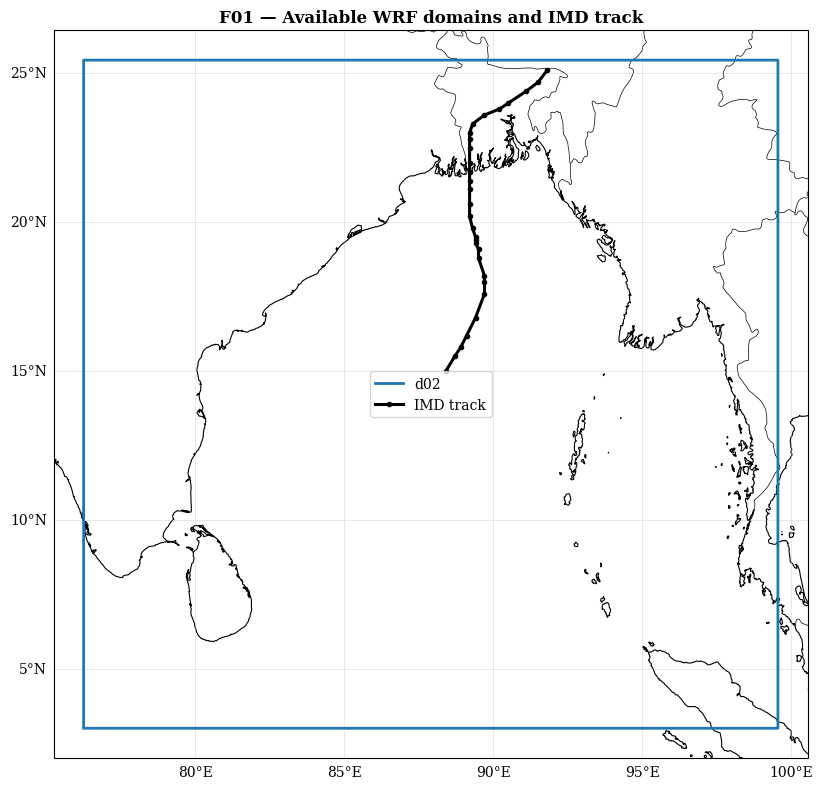


Saved: /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/A01_configuration/F01_Domain_Map.png


In [8]:
# ============================================================
# CHUNK 7B
# A01: DOMAIN MAP FROM THE WRF FILES ACTUALLY AVAILABLE
# ============================================================

domain_rows = []
domain_objects = []


# ------------------------------------------------------------
# 1. FIND AVAILABLE WRF DOMAINS
# ------------------------------------------------------------

# Search d01, d02 and d03.
# We try every experiment because a domain may be missing
# from one experiment folder but available in another.

for domain_name in ["d01", "d02", "d03"]:   # <----------------------- change this list to the domains you want drawn

    candidate = None

    for model_name in MODEL_NAMES:

        matches = sorted(
            glob.glob(
                MODEL_DIRS[model_name]
                + "/wrfout_"
                + domain_name
                + "_*"
            )
        )

        if len(matches) > 0:
            candidate = matches[0]
            break


    # If this domain does not exist anywhere, skip it.
    if candidate is None:

        print(domain_name, "was not found.")

        continue


    print(
        "Reading",
        domain_name,
        "from:",
        candidate
    )


    # --------------------------------------------------------
    # 2. READ DOMAIN INFORMATION
    # --------------------------------------------------------

    ds = Dataset(candidate)


    lat = np.array(
        ds.variables["XLAT"][0]
    )


    lon = np.array(
        ds.variables["XLONG"][0]
    )


    if "HGT" in ds.variables:

        hgt = np.array(
            ds.variables["HGT"][0]
        )

    else:

        hgt = None


    # DX and DY are global WRF attributes.
    if hasattr(ds, "DX"):

        dx = float(ds.DX)

    else:

        dx = np.nan


    if hasattr(ds, "DY"):

        dy = float(ds.DY)

    else:

        dy = np.nan


    ds.close()


    # --------------------------------------------------------
    # 3. SAVE DOMAIN METADATA
    # --------------------------------------------------------

    row = {

        "domain": domain_name,

        "source_file": candidate,

        "ny": lat.shape[0],

        "nx": lat.shape[1],

        "dx_m": dx,

        "dy_m": dy,

        "lat_min": float(np.nanmin(lat)),

        "lat_max": float(np.nanmax(lat)),

        "lon_min": float(np.nanmin(lon)),

        "lon_max": float(np.nanmax(lon)),
    }


    domain_rows.append(row)


    # Save arrays in memory for plotting later.
    domain_objects.append(
        (
            domain_name,
            lat,
            lon,
            hgt
        )
    )



# ------------------------------------------------------------
# 4. CREATE DOMAIN METADATA TABLE
# ------------------------------------------------------------

domain_table = pd.DataFrame(domain_rows)


domain_csv = (
    OUTDIRS["A01_configuration"]
    + "/A01_domain_metadata.csv"
)


domain_table.to_csv(
    domain_csv,
    index=False
)


print("\nA01 DOMAIN METADATA")
print("-------------------")


if len(domain_table) > 0:

    print(
        domain_table.to_string(
            index=False
        )
    )

else:

    print(
        "No WRF domain files were found."
    )


print(
    "\nSaved:",
    domain_csv
)



# ------------------------------------------------------------
# 5. DRAW F01 DOMAIN MAP
# ------------------------------------------------------------

if len(domain_objects) == 0:

    print(
        "\nNo WRF domain file was found."
    )

    print(
        "F01 domain map cannot be created yet."
    )


else:

    # --------------------------------------------------------
    # READ IMD TRACK
    # --------------------------------------------------------

    imd_domain = pd.read_csv(
        IMD_CSV
    )


    required = [

        IMD_COLUMNS["latitude"],

        IMD_COLUMNS["longitude"],
    ]


    missing = []


    for column_name in required:

        if column_name not in imd_domain.columns:

            missing.append(
                column_name
            )


    if len(missing) > 0:

        raise ValueError(

            "IMD CSV is missing columns required "
            "for the domain map: "
            + str(missing)

        )



    # --------------------------------------------------------
    # FIND TOTAL MAP EXTENT
    # --------------------------------------------------------

    all_lat_list = []
    all_lon_list = []


    for domain_name, lat, lon, hgt in domain_objects:

        all_lat_list.append(
            lat.ravel()
        )

        all_lon_list.append(
            lon.ravel()
        )


    all_lat = np.concatenate(
        all_lat_list
    )


    all_lon = np.concatenate(
        all_lon_list
    )


    pad = 1.0   # <----------------------- change this to pad the domain map extent (degrees)


    minimum_lon = (
        float(np.nanmin(all_lon))
        - pad
    )


    maximum_lon = (
        float(np.nanmax(all_lon))
        + pad
    )


    minimum_lat = (
        float(np.nanmin(all_lat))
        - pad
    )


    maximum_lat = (
        float(np.nanmax(all_lat))
        + pad
    )



    # --------------------------------------------------------
    # CREATE MAP
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(9, 8)   # <----------------------- change this to resize the figure (inches)
    )


    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )


    ax.set_extent(

        [
            minimum_lon,
            maximum_lon,
            minimum_lat,
            maximum_lat
        ],

        crs=ccrs.PlateCarree()
    )



    # --------------------------------------------------------
    # MAP FEATURES
    # --------------------------------------------------------

    ax.coastlines(
        resolution="10m",
        linewidth=0.8
    )


    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.5
    )


    gl = ax.gridlines(

        draw_labels=True,

        linewidth=0.4,

        alpha=0.5
    )


    gl.top_labels = False

    gl.right_labels = False



    # --------------------------------------------------------
    # DRAW EACH WRF DOMAIN
    # --------------------------------------------------------

    for domain_name, lat, lon, hgt in domain_objects:


        # Top boundary
        top_lon = lon[0, :]
        top_lat = lat[0, :]


        # Right boundary
        right_lon = lon[1:, -1]
        right_lat = lat[1:, -1]


        # Bottom boundary
        bottom_lon = lon[-1, -2::-1]
        bottom_lat = lat[-1, -2::-1]


        # Left boundary
        left_lon = lon[-2:0:-1, 0]
        left_lat = lat[-2:0:-1, 0]


        # Combine all four sides.
        boundary_lon = np.concatenate(

            [
                top_lon,
                right_lon,
                bottom_lon,
                left_lon
            ]

        )


        boundary_lat = np.concatenate(

            [
                top_lat,
                right_lat,
                bottom_lat,
                left_lat
            ]

        )


        ax.plot(

            boundary_lon,

            boundary_lat,

            linewidth=2.0,

            transform=ccrs.PlateCarree(),

            label=domain_name
        )



    # --------------------------------------------------------
    # IMD TRACK
    # --------------------------------------------------------

    ax.plot(

        imd_domain[
            IMD_COLUMNS["longitude"]
        ],

        imd_domain[
            IMD_COLUMNS["latitude"]
        ],

        color=COLORS["IMD"],

        linewidth=2.2,

        marker="o",

        markersize=3,

        transform=ccrs.PlateCarree(),

        label="IMD track"
    )



    # --------------------------------------------------------
    # FINAL FORMATTING
    # --------------------------------------------------------

    ax.set_title(
        "F01 — Available WRF domains and IMD track"
    )


    ax.legend(
        loc="best"
    )


    plt.tight_layout()



    # --------------------------------------------------------
    # SAVE FIGURE
    # --------------------------------------------------------

    figure_file = (

        OUTDIRS["A01_configuration"]

        + "/F01_Domain_Map.png"
    )


    plt.savefig(

        figure_file,

        dpi=300,   # <----------------------- change this to set the saved-figure resolution

        bbox_inches="tight"
    )


    plt.show()


    print(
        "\nSaved:",
        figure_file
    )

## S7. Frozen: file selection and distance helper
Unchanged from the original tracking workflow.

In [9]:
# CHUNK 8: FROZEN: file selection
# FROZEN: do not modify (see the plain-language summary in S5).
def list_wrfouts(folder, step_hours=6):   # <----------------------- frozen 6-hourly cadence
    files = sorted(glob.glob(folder + "/wrfout_d02_2024*"))   # <----------------------- frozen: change d02/2024 only for another domain/year
    chosen = []
    for f in files:
        hour = int(f.split("_")[-3])
        if hour % step_hours == 0:
            chosen.append(f)
    return chosen

In [10]:
# CHUNK 9: FROZEN: distance helper
# FROZEN: do not modify.
def distance_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)
    dlat = lat2 - lat1
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    a = np.clip(a, 0, 1)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

## S8. Frozen: raw track and centroid/smoothing functions
Kept verbatim from the original tracking workflow. Detection, centroid, thresholds, rejection, carry-forward, temporal sampling and smoothing are all unchanged.

In [11]:
# CHUNK 10: FROZEN: raw track extraction
# FROZEN: do not modify.
def extract_track(folder):

    files = list_wrfouts(folder)
    print("Number of files:", len(files))

    if len(files) == 0:
        raise FileNotFoundError("No WRF files found in " + folder)

    results = []

    for filename in files:

        print("Reading:", filename)
        wrf_file = Dataset(filename)

        slp = getvar(wrf_file, "slp", units="hPa")
        lat, lon = latlon_coords(slp)

        wind = getvar(wrf_file, "uvmet10_wspd_wdir", units="m s-1")
        wind_speed = wind[0]

        grid = pd.DataFrame({
            "latitude": lat.values.flatten(),
            "longitude": lon.values.flatten(),
            "slp_hpa": slp.values.flatten(),
            "wind_speed_ms": wind_speed.values.flatten(),
        })

        centre = grid.loc[grid["slp_hpa"].idxmin()]

        distance_to_centre = distance_km(
            grid["latitude"], grid["longitude"],
            centre["latitude"], centre["longitude"],
        )
        near = grid[distance_to_centre <= WIND_RADIUS_KM]
        strongest = near.loc[near["wind_speed_ms"].idxmax()]
        max_wind_ms = strongest["wind_speed_ms"]
        max_wind_distance = distance_to_centre[strongest.name]

        time = getvar(wrf_file, "times")
        time_utc = pd.to_datetime(str(time.values), utc=True)

        results.append({
            "time_utc": time_utc.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "latitude": centre["latitude"],
            "longitude": centre["longitude"],
            "wind_speed_kt": centre["wind_speed_ms"] * 3600 / 1852,
            "wind_speed_ms": centre["wind_speed_ms"],
            "central_pressure_hpa": centre["slp_hpa"],
            "max_wind_kt": max_wind_ms * 3600 / 1852,
            "max_wind_ms": max_wind_ms,
            "max_wind_distance_km": max_wind_distance,
        })

        wrf_file.close()

    return pd.DataFrame(results)

In [12]:
# CHUNK 11: FROZEN: centroid track, smoothing
# FROZEN: do not modify.
def extract_centroid_track(folder):

    files = list_wrfouts(folder)
    print("Number of files:", len(files))

    if len(files) == 0:
        raise FileNotFoundError("No WRF files found in " + folder)

    results = []
    diagnostics = []

    for filename in files:

        print("Reading:", filename)
        wrf_file = Dataset(filename)

        time = getvar(wrf_file, "times")
        time_utc = pd.to_datetime(str(time.values), utc=True)

        if len(results) > 0:
            time_gap = time_utc - results[-1]["time_utc"]
            if time_gap != pd.Timedelta(hours=6):
                wrf_file.close()
                raise ValueError("Expected a 6-hour gap before " + str(time_utc))

        slp = getvar(wrf_file, "slp", units="hPa")
        latitude, longitude = latlon_coords(slp)

        wind = getvar(wrf_file, "uvmet10_wspd_wdir", units="m s-1")
        wind_speed = wind[0]

        grid = pd.DataFrame({
            "latitude": latitude.values.flatten(),
            "longitude": longitude.values.flatten(),
            "slp_hpa": slp.values.flatten(),
            "wind_speed_ms": wind_speed.values.flatten(),
        })

        minimum_point = grid.loc[grid["slp_hpa"].idxmin()]
        candidate_pressure = minimum_point["slp_hpa"]

        if candidate_pressure <= 1000.0:   # <----------------------- frozen centroid threshold (hPa): change only for a sensitivity test
            pressure_limit = candidate_pressure + 1.5   # <----------------------- frozen centroid band (hPa): change only for a sensitivity test
            close_points = grid[grid["slp_hpa"] <= pressure_limit]
            candidate_latitude = close_points["latitude"].mean()
            candidate_longitude = close_points["longitude"].mean()
        else:
            candidate_latitude = minimum_point["latitude"]
            candidate_longitude = minimum_point["longitude"]

        if len(results) == 0:
            center_latitude = candidate_latitude
            center_longitude = candidate_longitude
            center_pressure = candidate_pressure
            status = "FIRST"
            movement_km = np.nan
            pressure_change = np.nan
        else:
            previous = results[-1]

            movement_km = distance_km(
                previous["latitude"], previous["longitude"],
                candidate_latitude, candidate_longitude,
            )
            pressure_change = abs(candidate_pressure - previous["central_pressure_hpa"])

            if movement_km > 360.0 or pressure_change > 12.0:   # <----------------------- frozen reject limits (km, hPa): change only for a sensitivity test
                center_latitude = previous["latitude"]
                center_longitude = previous["longitude"]
                center_pressure = previous["central_pressure_hpa"]
                status = "REJECTED"
            else:
                center_latitude = candidate_latitude
                center_longitude = candidate_longitude
                center_pressure = candidate_pressure
                status = "ACCEPTED"

        distances = distance_km(
            grid["latitude"], grid["longitude"],
            center_latitude, center_longitude,
        )
        nearest_point = grid.loc[distances.idxmin()]

        center_wind_ms = nearest_point["wind_speed_ms"]
        center_wind_kt = center_wind_ms * 3600 / 1852

        near = grid[distances <= WIND_RADIUS_KM]
        strongest = near.loc[near["wind_speed_ms"].idxmax()]
        max_wind_ms = strongest["wind_speed_ms"]
        max_wind_distance = distances[strongest.name]

        results.append({
            "time_utc": time_utc,
            "latitude": center_latitude,
            "longitude": center_longitude,
            "wind_speed_kt": center_wind_kt,
            "wind_speed_ms": center_wind_ms,
            "central_pressure_hpa": center_pressure,
            "max_wind_kt": max_wind_ms * 3600 / 1852,
            "max_wind_ms": max_wind_ms,
            "max_wind_distance_km": max_wind_distance,
        })

        diagnostics.append({
            "time_utc": time_utc,
            "status": status,
            "candidate_latitude": candidate_latitude,
            "candidate_longitude": candidate_longitude,
            "candidate_pressure_hpa": candidate_pressure,
            "movement_km": movement_km,
            "pressure_change_hpa": pressure_change,
        })

        wrf_file.close()

    centroid_df = pd.DataFrame(results)
    diagnostic_df = pd.DataFrame(diagnostics)

    smooth_df = centroid_df.copy()

    for row_number in range(len(centroid_df)):

        start_row = row_number - 1
        end_row = row_number + 2

        if start_row < 0:
            start_row = 0
        if end_row > len(centroid_df):
            end_row = len(centroid_df)

        nearby_rows = centroid_df.iloc[start_row:end_row]

        smooth_df.loc[row_number, "latitude"] = nearby_rows["latitude"].mean()
        smooth_df.loc[row_number, "longitude"] = nearby_rows["longitude"].mean()

    centroid_df["time_utc"] = centroid_df["time_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    smooth_df["time_utc"] = smooth_df["time_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    diagnostic_df["time_utc"] = diagnostic_df["time_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")

    return centroid_df, smooth_df, diagnostic_df

## S9. Run extraction (or load saved CSVs), then add carry-forward diagnostic flags
Extraction itself is unchanged. After it returns, this cell adds two diagnostic columns, `carried_forward` and `smoothing_uses_carried_forward`, computed from the frozen output without altering it.

In [13]:
# CHUNK 12: Run or load extraction
raw = {}
centroid = {}
smooth = {}
diag = {}

if RUN_EXTRACTION:

    for name in MODEL_NAMES:
        print("=====", name, "=====")
        raw[name] = extract_track(MODEL_DIRS[name])
        centroid[name], smooth[name], diag[name] = extract_centroid_track(MODEL_DIRS[name])

        raw[name].to_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Raw.csv", index=False)
        centroid[name].to_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Centroid.csv", index=False)
        smooth[name].to_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Smoothed.csv", index=False)
        diag[name].to_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Diagnostics.csv", index=False)

    print("Extraction finished and saved to A02_tracking.")

else:

    for name in MODEL_NAMES:
        raw[name] = pd.read_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Raw.csv")
        centroid[name] = pd.read_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Centroid.csv")
        smooth[name] = pd.read_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Smoothed.csv")
        diag[name] = pd.read_csv(OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Diagnostics.csv")

    print("Loaded saved CSV files from A02_tracking.")

===== FNL =====
Number of files: 18
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_00_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_06_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_12_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-24_18_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-25_00_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-25_06_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-25_12_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-25_18_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-26_00_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-26_06_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-26_12_00_00
Reading: /home/ushmo/Desktop/remaL_portfolio/fnl/wrfout_d02_2024-05-26_18_00_00
Read

In [14]:
# CHUNK 13: Convert times to dates
for table_group in [raw, centroid, smooth, diag]:
    for name in MODEL_NAMES:
        table = table_group[name]
        table["time_utc"] = pd.to_datetime(table["time_utc"], utc=True)
        table_group[name] = table.sort_values("time_utc").reset_index(drop=True)

for name in MODEL_NAMES:
    print(name, len(smooth[name]), "records,",
          smooth[name]["time_utc"].min(), "to", smooth[name]["time_utc"].max())

FNL 18 records, 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00
GFS 18 records, 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00
CFSv2 18 records, 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00
ERA5 18 records, 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00


In [15]:
# CHUNK 14: Flag carried-forward and smoothing-affected rows
# NEW; diagnostic flags only. Nothing here changes a position, a pressure, a wind value,
# or the accept/reject decision. It only records which rows were affected by carry-forward.
for name in MODEL_NAMES:

    d = diag[name]
    status_by_time = dict(zip(d["time_utc"], d["status"]))

    centroid[name]["carried_forward"] = centroid[name]["time_utc"].map(status_by_time) == "REJECTED"
    smooth[name]["carried_forward"] = smooth[name]["time_utc"].map(status_by_time) == "REJECTED"

    # Mirror the frozen smoothing window (row-1 .. row+1, clipped) to flag which
    # smoothed rows drew on at least one carried-forward neighbour.
    status_list = d.sort_values("time_utc")["status"].tolist()
    window_flag = []
    for row_number in range(len(status_list)):
        start_row = max(0, row_number - 1)
        end_row = min(len(status_list), row_number + 2)
        window_flag.append("REJECTED" in status_list[start_row:end_row])

    smooth[name]["smoothing_uses_carried_forward"] = window_flag

    n_carried = int(smooth[name]["carried_forward"].sum())
    n_smoothing_affected = int(smooth[name]["smoothing_uses_carried_forward"].sum())
    print(name, ":", n_carried, "of", len(smooth[name]),
          "timestamps are carried-forward positions;",
          n_smoothing_affected, "smoothed rows have a carried-forward value in their averaging window")

    smooth[name].to_csv(
        OUTDIRS["A02_tracking"] + "/Remal_" + name + "_6hr_Smoothed_Flagged.csv", index=False)

FNL : 3 of 18 timestamps are carried-forward positions; 4 smoothed rows have a carried-forward value in their averaging window
GFS : 3 of 18 timestamps are carried-forward positions; 4 smoothed rows have a carried-forward value in their averaging window
CFSv2 : 0 of 18 timestamps are carried-forward positions; 0 smoothed rows have a carried-forward value in their averaging window
ERA5 : 3 of 18 timestamps are carried-forward positions; 4 smoothed rows have a carried-forward value in their averaging window


## S10. Read the IMD file and check it

In [16]:
# CHUNK 15: Read and check IMD file
imd_raw = pd.read_csv(IMD_CSV)
imd_raw.columns = imd_raw.columns.str.strip()

print("Columns in your IMD file:", imd_raw.columns.tolist())

missing_columns = [wanted for wanted in IMD_COLUMNS.values() if wanted not in imd_raw.columns]
if len(missing_columns) > 0:
    raise KeyError("These columns are not in your IMD file: " + str(missing_columns)
                   + ". Edit IMD_COLUMNS in the settings chunk.")

rename_map = {IMD_COLUMNS[k]: k for k in IMD_COLUMNS}
imd = imd_raw.rename(columns=rename_map)[list(IMD_COLUMNS.keys())].copy()

imd["time_utc"] = pd.to_datetime(imd["time_utc"], utc=True)
for column in ["latitude", "longitude", "wind_kt", "pressure_hpa"]:
    imd[column] = pd.to_numeric(imd[column], errors="coerce")

imd = imd.sort_values("time_utc").reset_index(drop=True)

print(imd.head())
print(len(imd), "IMD records from", imd["time_utc"].min(), "to", imd["time_utc"].max())

Columns in your IMD file: ['time_utc', 'latitude', 'longitude', 'wind_speed_kt', 'wind_speed_ms', 'central_pressure_hpa']
                   time_utc  latitude  longitude  wind_kt  pressure_hpa
0 2024-05-24 00:00:00+00:00      15.0       88.4       25           996
1 2024-05-24 03:00:00+00:00      15.5       88.7       25           996
2 2024-05-24 06:00:00+00:00      15.8       88.9       25           996
3 2024-05-24 12:00:00+00:00      16.2       89.1       25           995
4 2024-05-24 18:00:00+00:00      16.8       89.4       25           995
30 IMD records from 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00


## S11. Shared helper functions
Map drawing, time-series statistics, area-weighted spatial statistics, bilinear regridding, and pairing model output with IMD.

In [17]:
# CHUNK 16: Shared helper functions
def extent_of(frames, pad=1.0):
    all_points = pd.concat(frames, ignore_index=True)
    return [
        all_points["longitude"].min() - pad, all_points["longitude"].max() + pad,
        all_points["latitude"].min() - pad, all_points["latitude"].max() + pad,
    ]

def draw_base_map(ax, extent):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    gridlines = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
    gridlines.top_labels = False
    gridlines.right_labels = False

def format_time_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))

def show(table, digits=2):
    table = table.copy()
    for column in table.columns:
        if pd.api.types.is_float_dtype(table[column]):
            table[column] = table[column].round(digits)
    print(table.to_string(index=False))

def error_stats(model_values, imd_values):
    # Time-series bias/MAE/RMSE/correlation, using only times where BOTH have a value.
    both = pd.DataFrame({
        "model": np.array(model_values, dtype=float),
        "imd": np.array(imd_values, dtype=float),
    }).dropna()

    n = len(both)
    if n == 0:
        return {"n": 0, "bias": np.nan, "mae": np.nan, "rmse": np.nan, "corr": np.nan}

    difference = both["model"] - both["imd"]
    return {
        "n": n,
        "bias": difference.mean(),
        "mae": difference.abs().mean(),
        "rmse": np.sqrt((difference**2).mean()),
        "corr": both["model"].corr(both["imd"]),
    }



def time_support_weights(times):
    """
    Trapezoidal time-support weights for irregularly sampled timestamps.

    Each interior observation represents half of the interval before it plus
    half of the interval after it. The first/last observations receive half
    of their adjacent interval. Returned weights sum to 1.
    """
    times = pd.DatetimeIndex(pd.to_datetime(times, utc=True))

    if len(times) == 0:
        return np.array([], dtype=float)

    if len(times) == 1:
        return np.array([1.0], dtype=float)

    time_seconds = times.asi8.astype(float) / 1.0e9
    gaps_seconds = np.diff(time_seconds)

    if np.any(gaps_seconds <= 0):
        raise ValueError("Timestamps for time-weighted statistics must be unique and increasing.")

    weights = np.zeros(len(times), dtype=float)
    weights[0] = gaps_seconds[0] / 2.0
    weights[-1] = gaps_seconds[-1] / 2.0

    if len(times) > 2:
        weights[1:-1] = (gaps_seconds[:-1] + gaps_seconds[1:]) / 2.0

    total = weights.sum()

    if total <= 0:
        return np.ones(len(times), dtype=float) / len(times)

    return weights / total


def time_weighted_error_stats(times, model_values, imd_values):
    """
    Time-weighted bias/MAE/RMSE/correlation for an irregular matched series.

    These statistics answer a time-average question, so densely sampled
    portions of the storm do not automatically receive more influence only
    because they contain more records.
    """
    both = pd.DataFrame({
        "time_utc": pd.to_datetime(times, utc=True),
        "model": np.asarray(model_values, dtype=float),
        "imd": np.asarray(imd_values, dtype=float),
    }).dropna().sort_values("time_utc").reset_index(drop=True)

    n = len(both)

    if n == 0:
        return {
            "n": 0,
            "bias": np.nan,
            "mae": np.nan,
            "rmse": np.nan,
            "corr": np.nan,
            "duration_hours": 0.0,
        }

    if n == 1:
        difference = float(both.loc[0, "model"] - both.loc[0, "imd"])
        return {
            "n": 1,
            "bias": difference,
            "mae": abs(difference),
            "rmse": abs(difference),
            "corr": np.nan,
            "duration_hours": 0.0,
        }

    weights = time_support_weights(both["time_utc"])
    model = both["model"].to_numpy(dtype=float)
    obs = both["imd"].to_numpy(dtype=float)
    difference = model - obs

    bias = np.sum(weights * difference)
    mae = np.sum(weights * np.abs(difference))
    rmse = np.sqrt(np.sum(weights * difference**2))

    model_mean = np.sum(weights * model)
    obs_mean = np.sum(weights * obs)
    covariance = np.sum(weights * (model - model_mean) * (obs - obs_mean))
    model_variance = np.sum(weights * (model - model_mean)**2)
    obs_variance = np.sum(weights * (obs - obs_mean)**2)

    if model_variance > 0 and obs_variance > 0:
        corr = covariance / np.sqrt(model_variance * obs_variance)
    else:
        corr = np.nan

    duration_hours = (
        both["time_utc"].iloc[-1] - both["time_utc"].iloc[0]
    ) / pd.Timedelta(hours=1)

    return {
        "n": n,
        "bias": float(bias),
        "mae": float(mae),
        "rmse": float(rmse),
        "corr": float(corr) if np.isfinite(corr) else np.nan,
        "duration_hours": float(duration_hours),
    }


def spatial_error_stats(model_field, ref_field, lat_2d):
    # Area-weighted (cos-latitude) bias/MAE/RMSE/spatial correlation between two
    # equal-shaped 2D fields already on the SAME grid. NaN cells in either field
    # are excluded from both the statistics and the weight sum.
    model_field = np.asarray(model_field, dtype=float)
    ref_field = np.asarray(ref_field, dtype=float)
    weights = np.cos(np.radians(np.asarray(lat_2d, dtype=float)))

    valid = np.isfinite(model_field) & np.isfinite(ref_field) & np.isfinite(weights)
    n_valid = int(valid.sum())

    if n_valid == 0:
        return {"n_valid_cells": 0, "bias": np.nan, "mae": np.nan, "rmse": np.nan, "corr": np.nan}

    m = model_field[valid]
    r = ref_field[valid]
    w = weights[valid]
    w = w / w.sum()

    difference = m - r
    bias = np.sum(w * difference)
    mae = np.sum(w * np.abs(difference))
    rmse = np.sqrt(np.sum(w * difference**2))

    m_mean = np.sum(w * m)
    r_mean = np.sum(w * r)
    cov = np.sum(w * (m - m_mean) * (r - r_mean))
    m_var = np.sum(w * (m - m_mean)**2)
    r_var = np.sum(w * (r - r_mean)**2)
    corr = cov / np.sqrt(m_var * r_var) if (m_var > 0 and r_var > 0) else np.nan

    return {"n_valid_cells": n_valid, "bias": bias, "mae": mae, "rmse": rmse, "corr": corr}

def regrid_to_regular(src_lon, src_lat, src_field, dst_lon_1d, dst_lat_1d, method="linear"):
    """
    Regrid a field onto a regular lon/lat grid.

    - Regular 1-D source lon/lat: RegularGridInterpolator.
    - Curvilinear 2-D WRF lon/lat: scipy.griddata.

    This is interpolation, NOT conservative remapping. That limitation matters
    especially for accumulated rainfall and is stated in the manuscript notes.
    """
    src_lon = np.asarray(src_lon)
    src_lat = np.asarray(src_lat)
    src_field = np.asarray(src_field, dtype=float)

    dst_lon_2d, dst_lat_2d = np.meshgrid(dst_lon_1d, dst_lat_1d)

    if src_lon.ndim == 1 and src_lat.ndim == 1:
        field = src_field.copy()

        # RegularGridInterpolator requires increasing coordinates.
        lon_order = np.argsort(src_lon)
        lat_order = np.argsort(src_lat)
        lon_sorted = src_lon[lon_order]
        lat_sorted = src_lat[lat_order]
        field_sorted = field[np.ix_(lat_order, lon_order)]

        interpolator = RegularGridInterpolator(
            (lat_sorted, lon_sorted),
            field_sorted,
            method="nearest" if method == "nearest" else "linear",
            bounds_error=False,
            fill_value=np.nan,
        )
        points = np.column_stack([dst_lat_2d.ravel(), dst_lon_2d.ravel()])
        return interpolator(points).reshape(dst_lat_2d.shape)

    if src_lon.ndim == 2 and src_lat.ndim == 2:
        valid = np.isfinite(src_lon) & np.isfinite(src_lat) & np.isfinite(src_field)
        if valid.sum() < 3:
            return np.full(dst_lon_2d.shape, np.nan)

        points = np.column_stack([src_lon[valid], src_lat[valid]])
        values = src_field[valid]

        out = griddata(
            points,
            values,
            (dst_lon_2d, dst_lat_2d),
            method="nearest" if method == "nearest" else "linear",
        )
        return out

    raise ValueError("Source lon/lat must both be 1-D or both be 2-D.")


# Backwards-compatible name used by earlier chunks.
def regrid_bilinear(src_lon, src_lat, src_field, dst_lon_1d, dst_lat_1d):
    return regrid_to_regular(src_lon, src_lat, src_field, dst_lon_1d, dst_lat_1d, method="linear")


def area_weighted_mean(field, lat):
    field = np.asarray(field, dtype=float)
    lat = np.asarray(lat, dtype=float)
    weights = np.cos(np.radians(lat))
    valid = np.isfinite(field) & np.isfinite(weights)
    if valid.sum() == 0:
        return np.nan
    return np.sum(field[valid] * weights[valid]) / np.sum(weights[valid])


def sync_general_output_folders():
    """
    Copy final CSV/figure/NetCDF outputs from each analysis folder into
    the three general mirror folders. Prefix with the analysis folder name
    so files with the same basename never overwrite one another.
    """
    copied = {"csv": 0, "figures": 0, "netcdf": 0}

    for analysis_key, folder in OUTDIRS.items():
        if not os.path.isdir(folder):
            continue

        for root, _, files in os.walk(folder):
            for filename in files:
                source = os.path.join(root, filename)
                safe_name = analysis_key + "__" + filename

                lower = filename.lower()
                if lower.endswith(".csv"):
                    shutil.copy2(source, os.path.join(GENERAL_CSV_DIR, safe_name))
                    copied["csv"] += 1
                elif lower.endswith((".png", ".jpg", ".jpeg", ".pdf", ".svg")):
                    shutil.copy2(source, os.path.join(GENERAL_FIGURE_DIR, safe_name))
                    copied["figures"] += 1
                elif lower.endswith((".nc", ".nc4", ".netcdf")):
                    shutil.copy2(source, os.path.join(GENERAL_NETCDF_DIR, safe_name))
                    copied["netcdf"] += 1

    return copied


def build_pair(model_table, imd_table):
    # Inner merge on EXACT shared timestamps only. No interpolation of IMD.
    m = model_table[["time_utc", "latitude", "longitude", "max_wind_kt",
                     "wind_speed_kt", "central_pressure_hpa", "carried_forward"]].copy()
    m.columns = ["time_utc", "lat_model", "lon_model", "wind_model",
                "wind_centre_model", "pres_model", "carried_forward"]

    i = imd_table[["time_utc", "latitude", "longitude", "wind_kt", "pressure_hpa"]].copy()
    i.columns = ["time_utc", "lat_imd", "lon_imd", "wind_imd", "pres_imd"]

    pair = i.merge(m, on="time_utc", how="inner")
    pair = pair.sort_values("time_utc").reset_index(drop=True)

    pair["track_error_km"] = distance_km(
        pair["lat_imd"], pair["lon_imd"], pair["lat_model"], pair["lon_model"])
    pair["wind_bias_kt"] = pair["wind_model"] - pair["wind_imd"]
    pair["wind_centre_bias_kt"] = pair["wind_centre_model"] - pair["wind_imd"]
    pair["pres_bias_hpa"] = pair["pres_model"] - pair["pres_imd"]

    return pair

## S12. Exact-time IMD matching: frozen track support + full intensity support
Two separate pair tables are built so the sampling rules cannot be mixed accidentally.

- **`pairs`** = the original/frozen 6-hourly smoothed-track comparison used by A03-A04 and track-dependent landfall work.
- **`intensity_pairs`** = every exact IMD-matching WRF timestamp common to all four experiments, used by A05-A07 and A09. With the supplied complete IMD set this should be **30 timestamps**.

Both use exact timestamp matching only. IMD is never temporally interpolated.


### PATCH: track-guided intensity centre
The full-time intensity extraction below now limits the minimum-SLP search to **300 km around each model's own frozen 6-hourly centroid track** (interpolated to the 3-hourly IMD times). Previously the search covered the whole d02 domain, and after Remal decayed the domain minimum moved to the north-India heat low (~24.5-25 N, 83-84.5 E), so late FNL, GFS and ERA5 intensity samples described the wrong low. The 150-km maximum-wind search is unchanged. Each run prints the times where the domain-wide minimum lay outside the search disk, and the extraction CSV records `guide_latitude`, `guide_longitude`, `domain_min_slp_hpa` and `domain_min_outside_search`.

**Rerun from this cell to the end** (`RUN_EXTRACTION = True`), so Tables A05-A07, PDI (A09), the sampling sensitivity (A16) and the summary table are all rebuilt from the corrected series.

In [18]:
# ============================================================
# CHUNK 16B / 17B
# FULL IMD-TIME INTENSITY EXTRACTION AND PAIRING
#
# IMPORTANT:
# - This does NOT modify the frozen 6-hourly track calculation.
# - Track/translation/landfall continue to use `pairs`.
# - Wind, pressure, biases, peaks, change rates and PDI use
#   `intensity_pairs`, built from every exact IMD-matching WRF file.
# - No temporal interpolation of wind or pressure is performed.
# ============================================================

def parse_wrf_output_time(filename):
    """
    Read the UTC timestamp from a WRF output filename.

    Supports both common forms:
      wrfout_d02_2024-05-24_00_00_00
      wrfout_d02_2024-05-24_00:00:00
    """
    base = os.path.basename(filename)
    stamp = base.replace("wrfout_d02_", "")

    formats = [
        "%Y-%m-%d_%H_%M_%S",
        "%Y-%m-%d_%H:%M:%S",
    ]

    for fmt in formats:
        try:
            return pd.to_datetime(stamp, format=fmt, utc=True)
        except ValueError:
            pass

    return pd.NaT


# ------------------------------------------------------------
# PATCH (track-guided intensity centre)
# The original version searched the WHOLE d02 domain for the minimum SLP.
# After Remal decayed, that minimum jumped to the north-India heat low
# (~24.5-25 N, 83-84.5 E), ~800 km from the storm, so late intensity values
# for FNL, GFS and ERA5 described the wrong low. The search is now limited to
# INTENSITY_SEARCH_RADIUS_KM around the model's OWN frozen 6-hourly centroid
# track (linearly interpolated to the 3-hourly IMD times). IMD positions are
# never used to locate the model centre.
# ------------------------------------------------------------
INTENSITY_SEARCH_RADIUS_KM = 300.0   # <----------------------- change this to resize the track-guided SLP search disk (km)


def guide_position(guide_track, when):
    """Model's own frozen centroid-track position, linearly interpolated in time."""
    g = guide_track.copy()
    g["time_utc"] = pd.to_datetime(g["time_utc"], utc=True)
    g = g.sort_values("time_utc")
    epoch = pd.Timestamp("2000-01-01T00:00:00Z")
    t = (g["time_utc"] - epoch).dt.total_seconds().to_numpy(dtype=float)
    x = float((pd.Timestamp(when) - epoch).total_seconds())
    if x < t[0] or x > t[-1]:
        raise ValueError("Intensity time " + str(when) + " lies outside the guide track.")
    lat = float(np.interp(x, t, g["latitude"].to_numpy(dtype=float)))
    lon = float(np.interp(x, t, g["longitude"].to_numpy(dtype=float)))
    return lat, lon


def extract_all_imd_intensity_times(folder, imd_table, guide_track=None,
                                    search_radius_km=INTENSITY_SEARCH_RADIUS_KM):
    """
    Extract intensity diagnostics from every WRF d02 file whose timestamp
    exactly matches a timestamp in the supplied IMD table.

    Centre used ONLY for this full-time intensity sampling:
      0. (PATCH) If guide_track is given, restrict the SLP search to cells
         within search_radius_km of the model's own frozen track position.
      1. Find the grid minimum SLP.
      2. If minimum SLP <= 1000 hPa, use the unweighted centroid of cells
         within 1.5 hPa of that minimum.
      3. Otherwise use the raw minimum-SLP grid point.
      4. Find the strongest 10 m wind inside WIND_RADIUS_KM of that centre.

    There is NO temporal smoothing and NO carry-forward in this full-time
    intensity extraction. It is deliberately separate from the frozen
    6-hourly track-validation method.
    """

    requested_times = set(pd.DatetimeIndex(imd_table["time_utc"]))
    files = sorted(glob.glob(folder + "/wrfout_d02_2024*"))   # <----------------------- change d02/2024 to your domain and year

    if len(files) == 0:
        raise FileNotFoundError("No WRF d02 files found in " + folder)

    file_rows = []

    for filename in files:
        when = parse_wrf_output_time(filename)

        if pd.isna(when):
            # Filename could not be parsed. Skip it here; the inventory
            # section already reports unparseable filenames.
            continue

        if when in requested_times:
            file_rows.append({
                "time_utc": when,
                "file": filename,
            })

    file_table = pd.DataFrame(file_rows)

    if len(file_table) == 0:
        raise ValueError(
            "No exact IMD-matching WRF timestamps were found in " + folder
        )

    # If duplicate files represent the same timestamp, stop rather than
    # silently selecting one.
    duplicated_times = file_table["time_utc"].duplicated(keep=False)

    if duplicated_times.any():
        duplicates = file_table.loc[duplicated_times, "time_utc"].tolist()
        raise ValueError(
            "Duplicate WRF files found for intensity timestamps: "
            + str(duplicates)
        )

    file_table = file_table.sort_values("time_utc").reset_index(drop=True)

    results = []

    for row_number in range(len(file_table)):

        filename = file_table.loc[row_number, "file"]
        expected_time = file_table.loc[row_number, "time_utc"]

        print(
            "Intensity extraction:",
            expected_time.strftime("%Y-%m-%d %H:%M UTC"),
            os.path.basename(filename)
        )

        wrf_file = Dataset(filename)

        try:
            # Verify the internal model time rather than trusting only
            # the filename.
            internal_time = getvar(wrf_file, "times")
            time_utc = pd.to_datetime(str(internal_time.values), utc=True)

            if time_utc != expected_time:
                raise ValueError(
                    "Filename time and internal WRF time disagree for "
                    + filename
                    + ": filename="
                    + str(expected_time)
                    + ", internal="
                    + str(time_utc)
                )

            slp = getvar(wrf_file, "slp", units="hPa")
            latitude, longitude = latlon_coords(slp)

            wind = getvar(
                wrf_file,
                "uvmet10_wspd_wdir",
                units="m s-1"
            )
            wind_speed = wind[0]

            grid = pd.DataFrame({
                "latitude": latitude.values.flatten(),
                "longitude": longitude.values.flatten(),
                "slp_hpa": slp.values.flatten(),
                "wind_speed_ms": wind_speed.values.flatten(),
            })

            # PATCH: keep the full grid for the 150-km wind search, but find
            # the pressure centre only inside the track-guided search disk.
            grid_full = grid
            domain_min_pressure = float(grid_full["slp_hpa"].min())
            domain_min_row = grid_full.loc[grid_full["slp_hpa"].idxmin()]

            if guide_track is not None:
                guide_lat, guide_lon = guide_position(guide_track, time_utc)
                guide_distance = distance_km(
                    grid_full["latitude"], grid_full["longitude"],
                    guide_lat, guide_lon,
                )
                grid = grid_full[guide_distance <= search_radius_km]
                if len(grid) == 0:
                    raise ValueError("Empty intensity search disk at " + str(time_utc))
                domain_min_outside = bool(
                    distance_km(domain_min_row["latitude"], domain_min_row["longitude"],
                                guide_lat, guide_lon) > search_radius_km
                )
            else:
                guide_lat = guide_lon = np.nan
                domain_min_outside = False

            minimum_point = grid.loc[
                grid["slp_hpa"].idxmin()
            ]

            minimum_pressure = float(
                minimum_point["slp_hpa"]
            )

            # Same low-SLP centroid definition as the frozen method,
            # but without temporal accept/reject or smoothing.
            if minimum_pressure <= 1000.0:   # <----------------------- same threshold as the frozen centroid (hPa)

                pressure_limit = (
                    minimum_pressure
                    + 1.5   # <----------------------- same band as the frozen centroid (hPa)
                )

                close_points = grid[
                    grid["slp_hpa"]
                    <= pressure_limit
                ]

                centre_latitude = float(
                    close_points["latitude"].mean()
                )

                centre_longitude = float(
                    close_points["longitude"].mean()
                )

                centre_method = (
                    "1.5_hPa_low_SLP_centroid"
                )

                n_centroid_cells = len(
                    close_points
                )

            else:

                centre_latitude = float(
                    minimum_point["latitude"]
                )

                centre_longitude = float(
                    minimum_point["longitude"]
                )

                centre_method = (
                    "raw_minimum_SLP_point"
                )

                n_centroid_cells = 1

            distances = distance_km(
                grid_full["latitude"],
                grid_full["longitude"],
                centre_latitude,
                centre_longitude,
            )

            nearest_index = distances.idxmin()

            centre_wind_ms = float(
                grid_full.loc[
                    nearest_index,
                    "wind_speed_ms"
                ]
            )

            near = grid_full[
                distances
                <= WIND_RADIUS_KM
            ]

            if len(near) == 0:
                raise ValueError(
                    "No wind grid cells found within "
                    + str(WIND_RADIUS_KM)
                    + " km at "
                    + str(time_utc)
                )

            strongest_index = near[
                "wind_speed_ms"
            ].idxmax()

            max_wind_ms = float(
                grid_full.loc[
                    strongest_index,
                    "wind_speed_ms"
                ]
            )

            max_wind_distance = float(
                distances.loc[
                    strongest_index
                ]
            )

            results.append({
                "time_utc": time_utc,
                "latitude": centre_latitude,
                "longitude": centre_longitude,
                "central_pressure_hpa": minimum_pressure,
                "wind_speed_ms": centre_wind_ms,
                "wind_speed_kt": centre_wind_ms * 3600.0 / 1852.0,
                "max_wind_ms": max_wind_ms,
                "max_wind_kt": max_wind_ms * 3600.0 / 1852.0,
                "max_wind_distance_km": max_wind_distance,
                "centre_method": centre_method,
                "n_centroid_cells": n_centroid_cells,
                "source_file": filename,
                "guide_latitude": guide_lat,
                "guide_longitude": guide_lon,
                "search_radius_km": search_radius_km if guide_track is not None else np.nan,
                "domain_min_slp_hpa": domain_min_pressure,
                "domain_min_outside_search": domain_min_outside,
            })

        finally:
            wrf_file.close()

    return pd.DataFrame(results).sort_values(
        "time_utc"
    ).reset_index(drop=True)


def build_intensity_pair(model_table, imd_table):
    """
    Exact-time IMD/model pairing for full-time intensity validation.
    No track-error column is created here because this table is NOT the
    primary track-validation table.
    """

    model_columns = [
        "time_utc",
        "latitude",
        "longitude",
        "max_wind_kt",
        "wind_speed_kt",
        "central_pressure_hpa",
        "max_wind_distance_km",
        "centre_method",
        "n_centroid_cells",
    ]

    model_part = model_table[
        model_columns
    ].copy()

    model_part.columns = [
        "time_utc",
        "lat_model_intensity",
        "lon_model_intensity",
        "wind_model",
        "wind_centre_model",
        "pres_model",
        "max_wind_distance_km",
        "centre_method",
        "n_centroid_cells",
    ]

    imd_part = imd_table[
        [
            "time_utc",
            "wind_kt",
            "pressure_hpa",
        ]
    ].copy()

    imd_part.columns = [
        "time_utc",
        "wind_imd",
        "pres_imd",
    ]

    pair = imd_part.merge(
        model_part,
        on="time_utc",
        how="inner"
    )

    pair = pair.sort_values(
        "time_utc"
    ).reset_index(drop=True)

    pair["wind_bias_kt"] = (
        pair["wind_model"]
        - pair["wind_imd"]
    )

    pair["wind_centre_bias_kt"] = (
        pair["wind_centre_model"]
        - pair["wind_imd"]
    )

    pair["pres_bias_hpa"] = (
        pair["pres_model"]
        - pair["pres_imd"]
    )

    return pair


# ------------------------------------------------------------
# EXTRACT OR LOAD THE FULL-TIME INTENSITY CACHE
# ------------------------------------------------------------

intensity_model = {}
intensity_pairs_all = {}
intensity_pairs = {}

cache_files = {}

for name in MODEL_NAMES:

    cache_files[name] = (
        OUTDIRS["A05_wind_validation"]
        + "/Remal_"
        + name
        + "_All_IMD_Intensity_Extraction.csv"
    )


cache_complete = True

for name in MODEL_NAMES:

    if not os.path.isfile(
        cache_files[name]
    ):
        cache_complete = False


if RUN_EXTRACTION or not cache_complete:

    print(
        "\nExtracting all exact IMD-matching "
        "WRF timestamps for intensity validation."
    )

    for name in MODEL_NAMES:

        print(
            "\n==========",
            name,
            "FULL-TIME INTENSITY =========="
        )

        intensity_model[name] = (
            extract_all_imd_intensity_times(
                MODEL_DIRS[name],
                imd,
                guide_track=centroid[name],
            )
        )

        intensity_model[name].to_csv(
            cache_files[name],
            index=False
        )

        affected = intensity_model[name][
            intensity_model[name]["domain_min_outside_search"]
        ]
        print(
            name, ": domain-wide SLP minimum lay outside the",
            int(INTENSITY_SEARCH_RADIUS_KM), "km track-guided search at",
            len(affected), "of", len(intensity_model[name]), "times",
        )
        if len(affected) > 0:
            print(affected[["time_utc", "domain_min_slp_hpa",
                            "central_pressure_hpa", "max_wind_kt"]].to_string(index=False))

else:

    print(
        "\nLoading saved full-time intensity "
        "extractions."
    )

    for name in MODEL_NAMES:

        intensity_model[name] = pd.read_csv(
            cache_files[name]
        )

        intensity_model[name][
            "time_utc"
        ] = pd.to_datetime(
            intensity_model[name]["time_utc"],
            utc=True
        )


# ------------------------------------------------------------
# BUILD EXACT MODEL-vs-IMD PAIRS
# ------------------------------------------------------------

for name in MODEL_NAMES:

    intensity_pairs_all[name] = (
        build_intensity_pair(
            intensity_model[name],
            imd
        )
    )

    print(
        name,
        ":",
        len(intensity_pairs_all[name]),
        "exact IMD intensity matches"
    )


# ------------------------------------------------------------
# FORCE IDENTICAL TEMPORAL SUPPORT ACROSS ALL FOUR MODELS
# ------------------------------------------------------------
# This keeps inter-model validation comparisons fair. If all files are
# present, the expected result for the supplied IMD table is 30 times.

common_intensity_times = set(
    pd.DatetimeIndex(
        imd["time_utc"]
    )
)

for name in MODEL_NAMES:

    model_times = set(
        pd.DatetimeIndex(
            intensity_pairs_all[name][
                "time_utc"
            ]
        )
    )

    common_intensity_times = (
        common_intensity_times
        & model_times
    )


common_intensity_times = pd.DatetimeIndex(
    sorted(
        common_intensity_times
    )
)


for name in MODEL_NAMES:

    intensity_pairs[name] = (
        intensity_pairs_all[name][
            intensity_pairs_all[name][
                "time_utc"
            ].isin(
                common_intensity_times
            )
        ]
        .copy()
        .sort_values(
            "time_utc"
        )
        .reset_index(
            drop=True
        )
    )


requested_n = len(imd)
common_n = len(common_intensity_times)

print()
print(
    "IMD intensity timestamps requested:",
    requested_n
)

print(
    "Common exact timestamps available "
    "in IMD + all four WRF runs:",
    common_n
)

if common_n == requested_n:

    print(
        "PASS: every IMD intensity timestamp "
        "has an exact WRF match in all four runs."
    )

else:

    missing_common = pd.DatetimeIndex(
        imd["time_utc"]
    ).difference(
        common_intensity_times
    )

    print(
        "WARNING:",
        requested_n - common_n,
        "IMD timestamps cannot be compared "
        "across all four runs."
    )

    print(
        "Missing from common support:",
        list(
            missing_common.strftime(
                "%Y-%m-%d %H:%M"
            )
        )
    )


# ------------------------------------------------------------
# SAVE ANALYSIS-SPECIFIC MATCH TABLES
# ------------------------------------------------------------

coverage_rows = []

for name in MODEL_NAMES:

    p = intensity_pairs[name]

    # Master full intensity table for A07.
    p.to_csv(
        OUTDIRS["A07_intensity_change"]
        + "/Remal_"
        + name
        + "_All_IMD_Intensity_Matches.csv",
        index=False
    )

    # Wind-specific table for A05.
    wind_export = p[
        [
            "time_utc",
            "wind_imd",
            "wind_model",
            "wind_bias_kt",
            "wind_centre_model",
            "wind_centre_bias_kt",
            "max_wind_distance_km",
            "lat_model_intensity",
            "lon_model_intensity",
            "centre_method",
            "n_centroid_cells",
        ]
    ].copy()

    wind_export.to_csv(
        OUTDIRS["A05_wind_validation"]
        + "/Remal_"
        + name
        + "_All_IMD_Wind_Matches.csv",
        index=False
    )

    # Pressure-specific table for A06.
    pressure_export = p[
        [
            "time_utc",
            "pres_imd",
            "pres_model",
            "pres_bias_hpa",
            "lat_model_intensity",
            "lon_model_intensity",
            "centre_method",
            "n_centroid_cells",
        ]
    ].copy()

    pressure_export.to_csv(
        OUTDIRS["A06_pressure_validation"]
        + "/Remal_"
        + name
        + "_All_IMD_Pressure_Matches.csv",
        index=False
    )

    coverage_rows.append({
        "model": name,
        "imd_records_requested": requested_n,
        "model_exact_matches_before_common_filter": len(
            intensity_pairs_all[name]
        ),
        "common_matches_used_for_validation": len(
            p
        ),
    })


intensity_coverage_table = pd.DataFrame(
    coverage_rows
)

intensity_coverage_table.to_csv(
    OUTDIRS["A05_wind_validation"]
    + "/A05_A06_Intensity_Match_Coverage.csv",
    index=False
)

print()
show(
    intensity_coverage_table,
    0
)



Extracting all exact IMD-matching WRF timestamps for intensity validation.

========== FNL FULL-TIME INTENSITY ==========
Intensity extraction: 2024-05-24 00:00 UTC wrfout_d02_2024-05-24_00_00_00
Intensity extraction: 2024-05-24 03:00 UTC wrfout_d02_2024-05-24_03_00_00
Intensity extraction: 2024-05-24 06:00 UTC wrfout_d02_2024-05-24_06_00_00
Intensity extraction: 2024-05-24 12:00 UTC wrfout_d02_2024-05-24_12_00_00
Intensity extraction: 2024-05-24 18:00 UTC wrfout_d02_2024-05-24_18_00_00
Intensity extraction: 2024-05-25 00:00 UTC wrfout_d02_2024-05-25_00_00_00
Intensity extraction: 2024-05-25 03:00 UTC wrfout_d02_2024-05-25_03_00_00
Intensity extraction: 2024-05-25 06:00 UTC wrfout_d02_2024-05-25_06_00_00
Intensity extraction: 2024-05-25 12:00 UTC wrfout_d02_2024-05-25_12_00_00
Intensity extraction: 2024-05-25 15:00 UTC wrfout_d02_2024-05-25_15_00_00
Intensity extraction: 2024-05-25 18:00 UTC wrfout_d02_2024-05-25_18_00_00
Intensity extraction: 2024-05-25 21:00 UTC wrfout_d02_2024-05-2

In [19]:
# CHUNK 17: Pair every model with IMD
pairs = {}
pairs_excluding_carried_forward = {}

for name in MODEL_NAMES:

    pairs[name] = build_pair(smooth[name], imd)
    pairs[name].to_csv(OUTDIRS["A03_track_validation"] + "/Remal_" + name + "_vs_IMD.csv", index=False)

    n_total = len(pairs[name])
    n_carried = int(pairs[name]["carried_forward"].sum())

    print(name, ":", n_total, "matched timestamps with IMD (",
          pairs[name]["time_utc"].min(), "to", pairs[name]["time_utc"].max(), ") —",
          n_carried, "of them are carried-forward (rejected) positions.")

    if n_total == 0:
        raise ValueError("No shared timestamps for " + name + ". Check the time format in the IMD file.")

    # Supplementary only; does NOT change the primary track or any analysis above.
    pairs_excluding_carried_forward[name] = pairs[name][~pairs[name]["carried_forward"]].copy()
    pairs_excluding_carried_forward[name].to_csv(
        OUTDIRS["A03_track_validation"] + "/Remal_" + name + "_vs_IMD_excluding_carried_forward.csv", index=False)

FNL : 18 matched timestamps with IMD ( 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 ) — 3 of them are carried-forward (rejected) positions.
GFS : 18 matched timestamps with IMD ( 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 ) — 3 of them are carried-forward (rejected) positions.
CFSv2 : 18 matched timestamps with IMD ( 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 ) — 0 of them are carried-forward (rejected) positions.
ERA5 : 18 matched timestamps with IMD ( 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 ) — 3 of them are carried-forward (rejected) positions.


# A02: Tracking-method sensitivity and diagnostics
Compares raw, centroid and smoothed tracks, lists rejected candidates, and maps the selected pressure and wind fields.

**Folder:** `A02_tracking` (output filenames keep the legacy `Remal_A1_` prefix)

### How to read this figure
- Each dot is one time (one 6-hourly WRF output, or one IMD report).
- Black = IMD track. Grey dashed = raw model track. Blue = centroid track. Red = smoothed track.
- Green X = a candidate position that was rejected (carried forward from the previous timestamp).

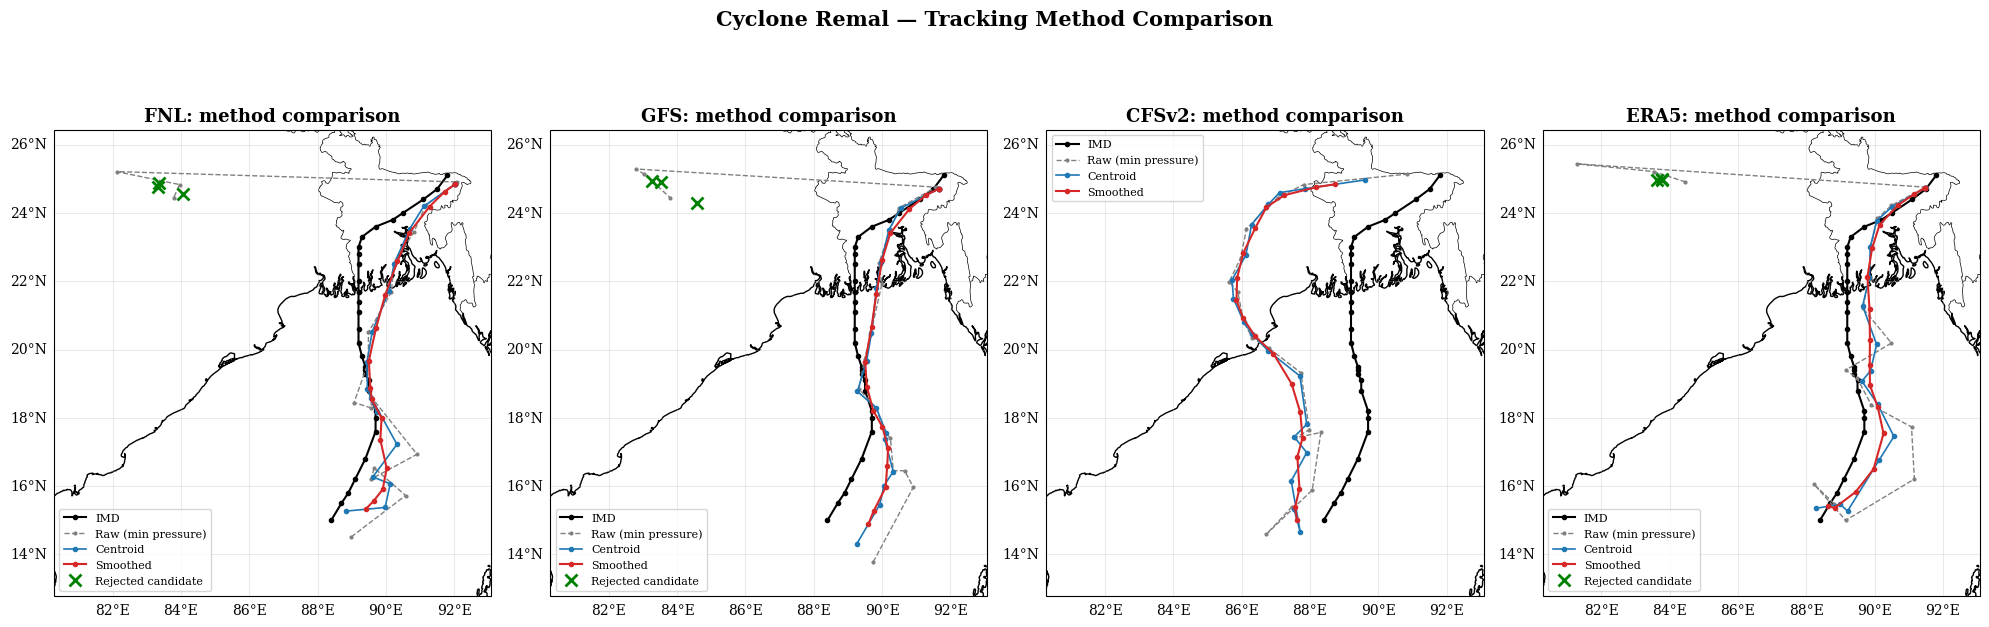

In [20]:
# CHUNK 18: A02: raw vs centroid vs smoothed tracks
extent = extent_of([imd] + list(raw.values()) + list(centroid.values()), pad=1.0)

fig, axes = plt.subplots(1, 4, figsize=(20, 7), subplot_kw={"projection": ccrs.PlateCarree()})   # <----------------------- change this to resize the figure (inches)

for i in range(4):

    name = MODEL_NAMES[i]
    ax = axes[i]
    draw_base_map(ax, extent)

    ax.plot(imd["longitude"], imd["latitude"], color="black", marker="o",
            markersize=3, linewidth=1.5, label="IMD", transform=ccrs.PlateCarree())
    ax.plot(raw[name]["longitude"], raw[name]["latitude"], color="grey",
            marker=".", markersize=4, linewidth=1, linestyle="--",
            label="Raw (min pressure)", transform=ccrs.PlateCarree())
    ax.plot(centroid[name]["longitude"], centroid[name]["latitude"], color="tab:blue",
            marker="o", markersize=3, linewidth=1.2, label="Centroid", transform=ccrs.PlateCarree())
    ax.plot(smooth[name]["longitude"], smooth[name]["latitude"], color="tab:red",
            marker="o", markersize=3, linewidth=1.5, label="Smoothed", transform=ccrs.PlateCarree())

    rejected = diag[name][diag[name]["status"] == "REJECTED"]
    if len(rejected) > 0:
        ax.plot(rejected["candidate_longitude"], rejected["candidate_latitude"],
                linestyle="none", marker="x", color="green", markersize=9, markeredgewidth=2,
                label="Rejected candidate", transform=ccrs.PlateCarree())

    ax.set_title(name + ": method comparison", fontsize=13, fontweight="bold")
    ax.legend(fontsize=8)

fig.suptitle("Cyclone Remal — Tracking Method Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTDIRS["A02_tracking"] + "/Remal_A1_Tracking_Method.png", dpi=300, bbox_inches="tight")   # <----------------------- change this to set the saved-figure resolution
plt.show()

In [21]:
# CHUNK 19: A02: track error by method
method_rows = []

for name in MODEL_NAMES:
    for method_name, table in [("Raw", raw[name]), ("Centroid", centroid[name]), ("Smoothed", smooth[name])]:
        t = table.copy()
        if "carried_forward" not in t.columns:
            t["carried_forward"] = False
        p = build_pair(t, imd)
        error = p["track_error_km"]
        method_rows.append({
            "model": name, "method": method_name, "n_matched": len(p),
            "mean_error_km": error.mean(), "rmse_km": np.sqrt((error**2).mean()), "max_error_km": error.max(),
        })

method_errors = pd.DataFrame(method_rows)
method_errors.to_csv(OUTDIRS["A02_tracking"] + "/Remal_A1_Method_Errors.csv", index=False)
show(method_errors, 1)

model   method  n_matched  mean_error_km  rmse_km  max_error_km
  FNL      Raw         18          233.0    351.2         858.3
  FNL Centroid         18          108.6    129.2         274.3
  FNL Smoothed         18          102.1    123.5         249.9
  GFS      Raw         18          236.7    353.0         818.1
  GFS Centroid         18          102.5    114.9         233.8
  GFS Smoothed         18           99.5    110.9         205.5
CFSv2      Raw         18          259.5    275.2         369.4
CFSv2 Centroid         18          263.8    275.4         361.6
CFSv2 Smoothed         18          261.7    273.3         349.6
 ERA5      Raw         18          240.0    358.9         945.1
 ERA5 Centroid         18          101.0    115.1         221.6
 ERA5 Smoothed         18           95.8    109.2         203.8


In [22]:
# CHUNK 20: A02: rejected candidates table
rejected_list = []
for name in MODEL_NAMES:
    r = diag[name][diag[name]["status"] == "REJECTED"].copy()
    r.insert(0, "model", name)
    rejected_list.append(r)

rejected_all = pd.concat(rejected_list, ignore_index=True)
rejected_all.to_csv(OUTDIRS["A02_tracking"] + "/Remal_A1_Rejected_Candidates.csv", index=False)

print("Rejected (carried-forward) candidates per model:")
for name in MODEL_NAMES:
    print(" ", name, ":", int((diag[name]["status"] == "REJECTED").sum()))

if len(rejected_all) > 0:
    show(rejected_all, 2)
else:
    print("No candidates were rejected in this run.")

Rejected (carried-forward) candidates per model:
  FNL : 3
  GFS : 3
  CFSv2 : 0
  ERA5 : 3
model                  time_utc   status  candidate_latitude  candidate_longitude  candidate_pressure_hpa  movement_km  pressure_change_hpa
  FNL 2024-05-27 18:00:00+00:00 REJECTED           24.750000            83.330002                  990.80       878.20                 5.61
  FNL 2024-05-28 00:00:00+00:00 REJECTED           24.870001            83.360001                  991.19       874.82                 6.00
  FNL 2024-05-28 06:00:00+00:00 REJECTED           24.549999            84.059998                  991.70       806.31                 6.51
  GFS 2024-05-27 18:00:00+00:00 REJECTED           24.930000            83.260002                  990.56       847.50                 6.38
  GFS 2024-05-28 00:00:00+00:00 REJECTED           24.920000            83.519997                  990.79       821.48                 6.61
  GFS 2024-05-28 06:00:00+00:00 REJECTED           24.290001        

### How to read these maps
- Top row: sea-level pressure. Bottom row: 10 m wind (kt).
- White + = raw point, blue circle = centroid, red triangle = smoothed centre.
- Dashed circle = the search radius for the strongest wind; cyan star = where it was found.

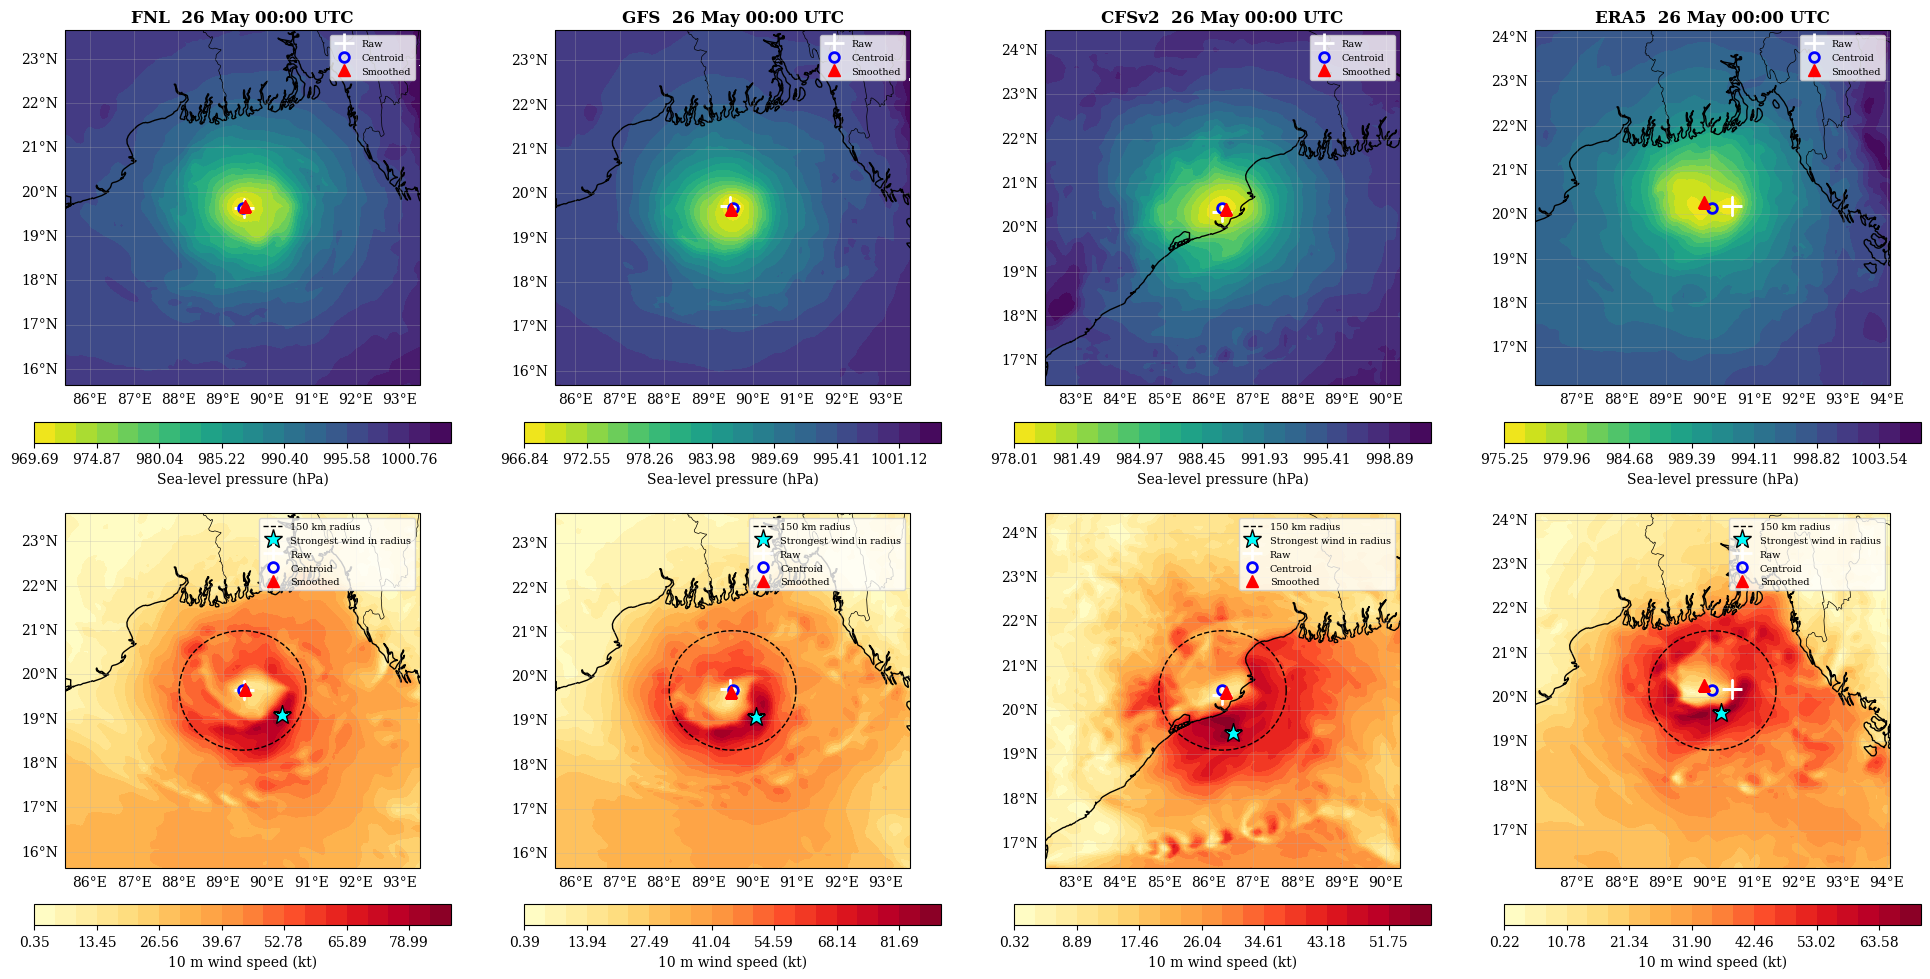

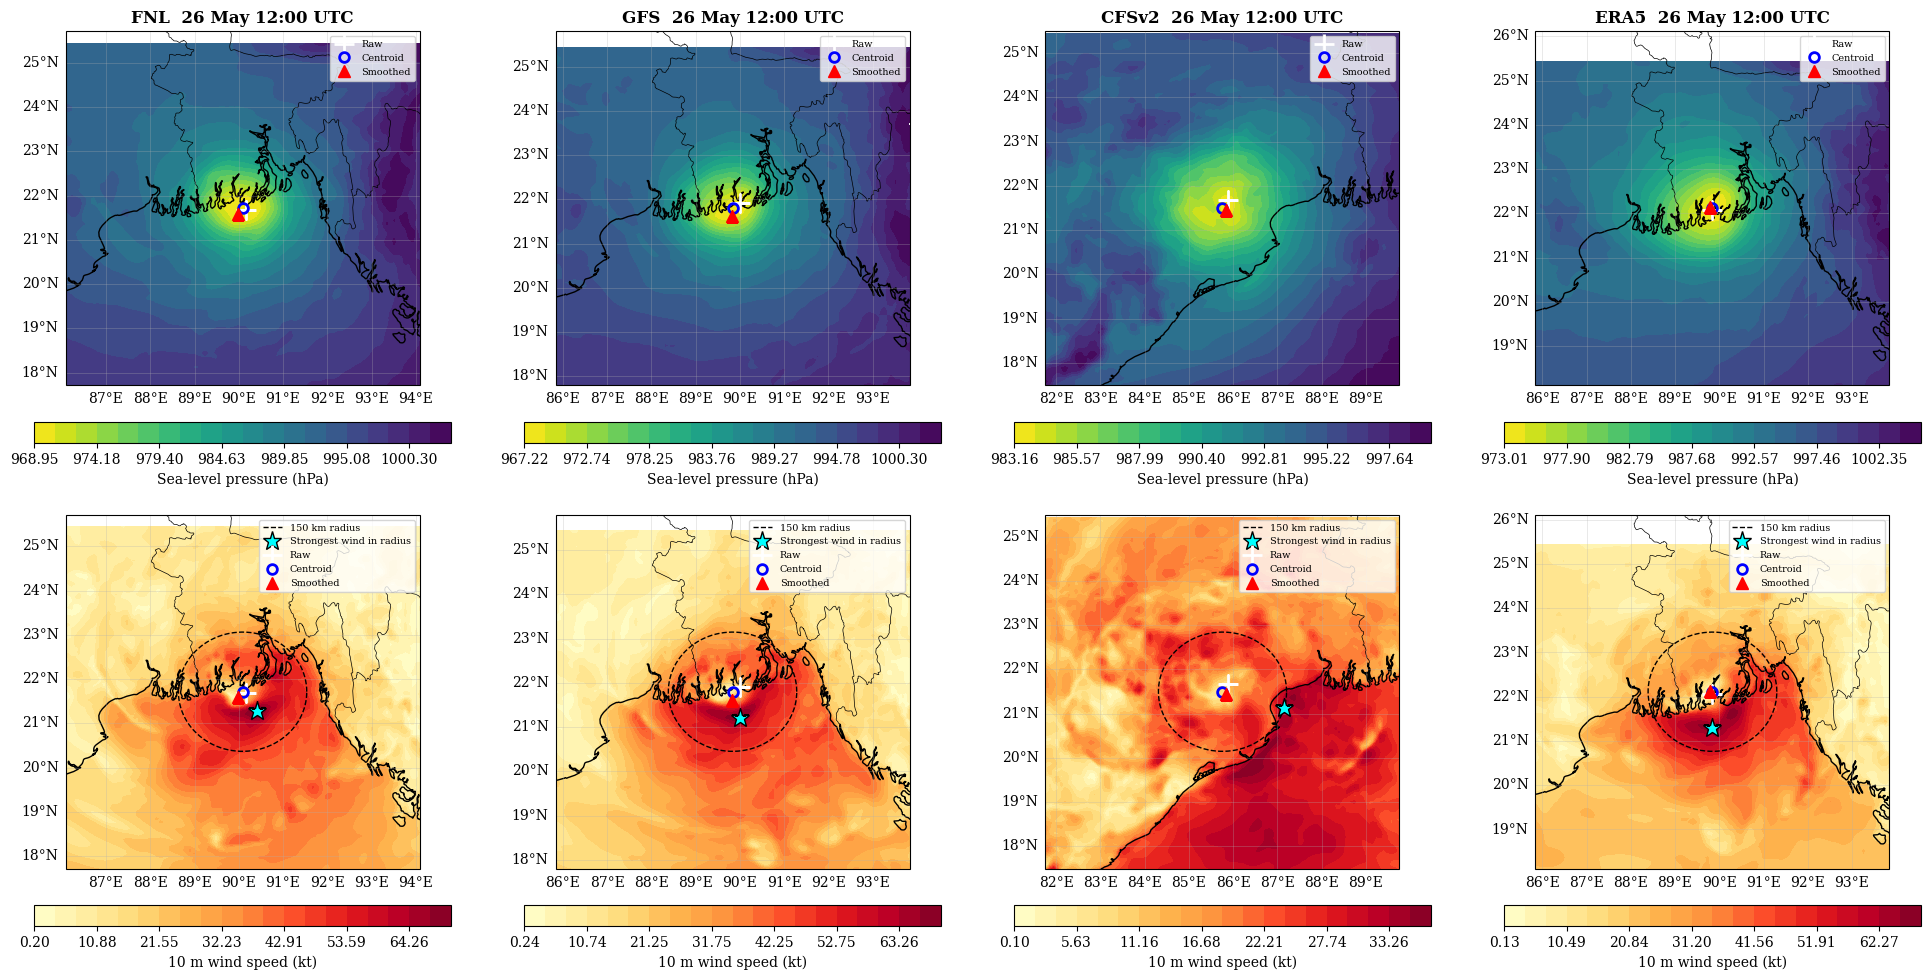

In [23]:
# CHUNK 21: A02: pressure and wind maps
def plot_selected_maps(time_text):

    when = pd.to_datetime(time_text, utc=True)
    fig, axes = plt.subplots(2, 4, figsize=(20, 10), subplot_kw={"projection": ccrs.PlateCarree()})   # <----------------------- change this to resize the figure (inches)

    for col in range(4):

        name = MODEL_NAMES[col]
        filename = MODEL_DIRS[name] + "/wrfout_d02_" + when.strftime("%Y-%m-%d_%H_%M_%S")
        if not os.path.exists(filename):
            print("Skipping", name, "- file not found:", filename)
            continue

        raw_row = raw[name][raw[name]["time_utc"] == when]
        centroid_row = centroid[name][centroid[name]["time_utc"] == when]
        smooth_row = smooth[name][smooth[name]["time_utc"] == when]
        if len(raw_row) == 0 or len(centroid_row) == 0 or len(smooth_row) == 0:
            print("Skipping", name, "- time not in the track tables:", when)
            continue

        wrf_file = Dataset(filename)
        slp = getvar(wrf_file, "slp", units="hPa")
        lat, lon = latlon_coords(slp)
        wind_speed = getvar(wrf_file, "uvmet10_wspd_wdir", units="m s-1")[0]
        lats, lons = lat.values, lon.values
        slp_values, wind_values = slp.values, wind_speed.values * 3600 / 1852
        wrf_file.close()

        cx = float(centroid_row["longitude"].iloc[0]); cy = float(centroid_row["latitude"].iloc[0])
        box = [cx - 4, cx + 4, cy - 4, cy + 4]   # <----------------------- change this to zoom the A02 maps (degrees around the centre)
        inside = (lons >= box[0]) & (lons <= box[1]) & (lats >= box[2]) & (lats <= box[3])

        for row in range(2):
            ax = axes[row, col]
            draw_base_map(ax, box)

            if row == 0:
                levels = np.linspace(np.nanmin(slp_values[inside]), np.nanmax(slp_values[inside]), 21)
                shading = ax.contourf(lons, lats, slp_values, levels=levels, cmap="viridis_r", transform=ccrs.PlateCarree())   # <----------------------- change this to use a different colour map
                label = "Sea-level pressure (hPa)"
            else:
                levels = np.linspace(np.nanmin(wind_values[inside]), np.nanmax(wind_values[inside]), 21)
                shading = ax.contourf(lons, lats, wind_values, levels=levels, cmap="YlOrRd", transform=ccrs.PlateCarree())   # <----------------------- change this to use a different colour map
                label = "10 m wind speed (kt)"

                angle = np.linspace(0, 2 * np.pi, 200)
                ring_lat = cy + (WIND_RADIUS_KM / 111.32) * np.sin(angle)
                ring_lon = cx + (WIND_RADIUS_KM / (111.32 * np.cos(np.radians(cy)))) * np.cos(angle)
                ax.plot(ring_lon, ring_lat, color="black", linestyle="--", linewidth=1,
                        label=str(WIND_RADIUS_KM) + " km radius", transform=ccrs.PlateCarree())
                distance_grid = distance_km(lats, lons, cy, cx)
                inside_radius = np.where(distance_grid <= WIND_RADIUS_KM, wind_values, -1)
                strongest = np.unravel_index(np.argmax(inside_radius), inside_radius.shape)
                ax.plot(lons[strongest], lats[strongest], marker="*", markersize=14, color="cyan",
                        markeredgecolor="black", linestyle="none", label="Strongest wind in radius",
                        transform=ccrs.PlateCarree())

            ax.plot(raw_row["longitude"], raw_row["latitude"], "w+", markersize=14, markeredgewidth=2,
                    label="Raw", transform=ccrs.PlateCarree())
            ax.plot(centroid_row["longitude"], centroid_row["latitude"], "bo", markersize=7,
                    markerfacecolor="none", markeredgewidth=2, label="Centroid", transform=ccrs.PlateCarree())
            ax.plot(smooth_row["longitude"], smooth_row["latitude"], "r^", markersize=8,
                    label="Smoothed", transform=ccrs.PlateCarree())

            plt.colorbar(shading, ax=ax, orientation="horizontal", pad=0.08, shrink=0.85, label=label)
            if row == 0:
                ax.set_title(name + "  " + when.strftime("%d %b %H:%M UTC"), fontweight="bold")
            ax.legend(loc="upper right", fontsize=7)

    plt.tight_layout()
    out_name = "/Remal_A1_Selected_Maps_" + when.strftime("%Y%m%d_%H") + ".png"
    plt.savefig(OUTDIRS["A02_tracking"] + out_name, dpi=300, bbox_inches="tight")   # <----------------------- change this to set the saved-figure resolution
    plt.show()

for time_text in MAP_TIMES:
    plot_selected_maps(time_text)

# A03: Cyclone track validation
Model-IMD track maps, position error through time, mean error, RMSE and max error, all on exact shared timestamps only.

**Folder:** `A03_track_validation` (output filenames keep the legacy `Remal_A2_` prefix)

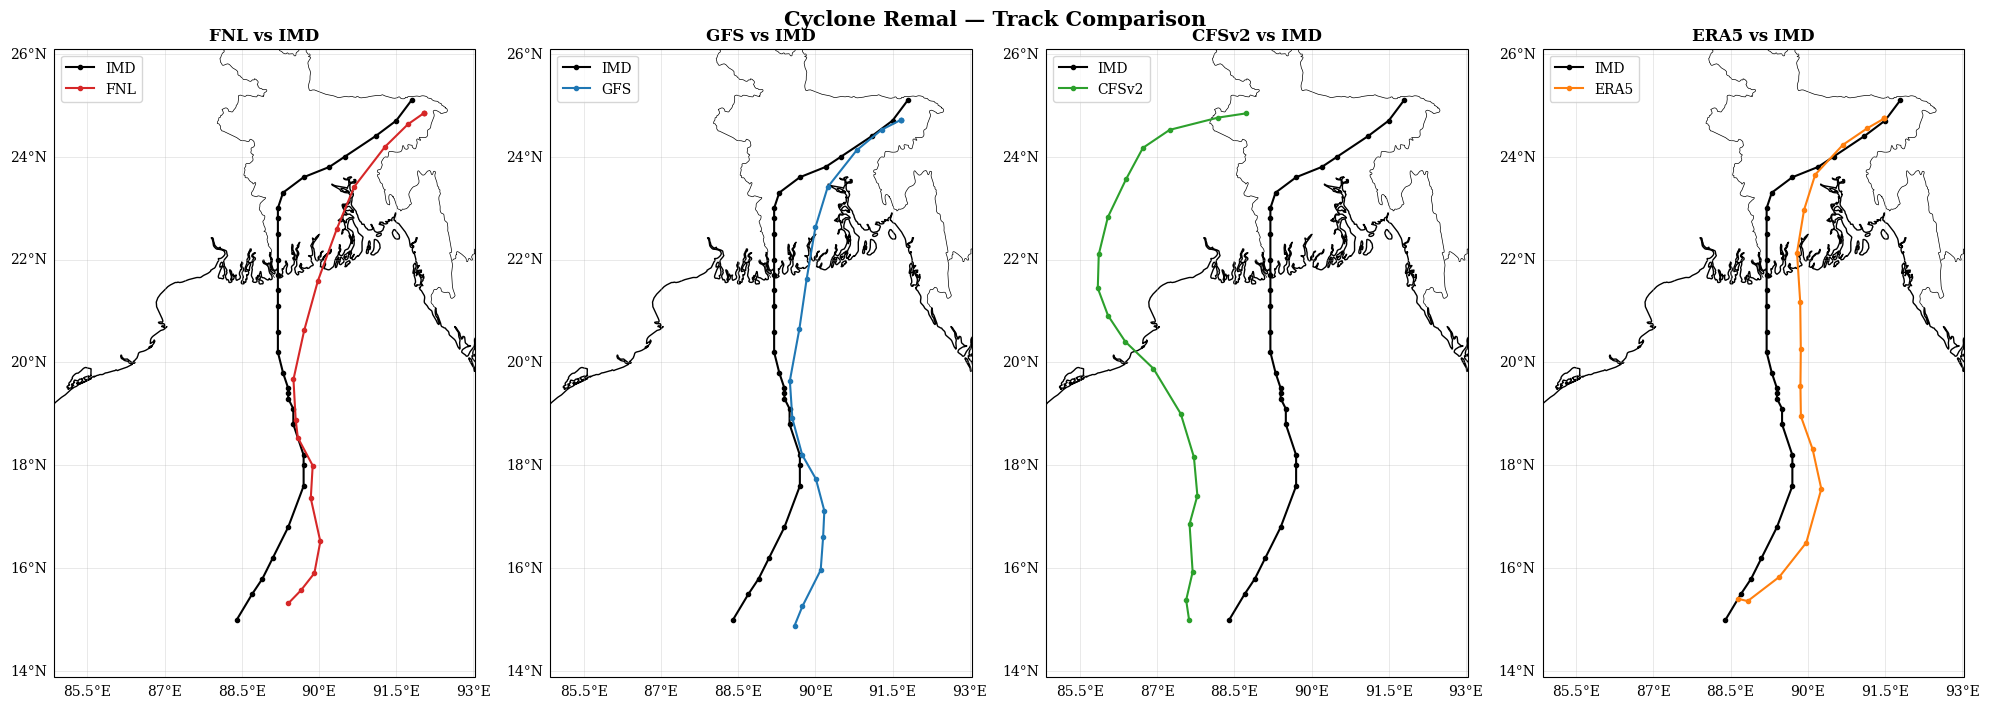

In [24]:
# CHUNK 22: A03: track maps against IMD
extent = extent_of([imd] + list(smooth.values()), pad=1.0)
fig, axes = plt.subplots(1, 4, figsize=(20, 7), subplot_kw={"projection": ccrs.PlateCarree()})   # <----------------------- change this to resize the figure (inches)

for i in range(4):
    name = MODEL_NAMES[i]
    ax = axes[i]
    draw_base_map(ax, extent)
    ax.plot(imd["longitude"], imd["latitude"], color="black", marker="o", markersize=3,
            linewidth=1.5, label="IMD", transform=ccrs.PlateCarree())
    ax.plot(smooth[name]["longitude"], smooth[name]["latitude"], color=COLORS[name], marker="o",
            markersize=3, linewidth=1.5, label=name, transform=ccrs.PlateCarree())
    ax.set_title(name + " vs IMD", fontweight="bold")
    ax.legend()

fig.suptitle("Cyclone Remal — Track Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTDIRS["A03_track_validation"] + "/Remal_A2_Track_Maps.png", dpi=300, bbox_inches="tight")   # <----------------------- change this to set the saved-figure resolution
plt.show()

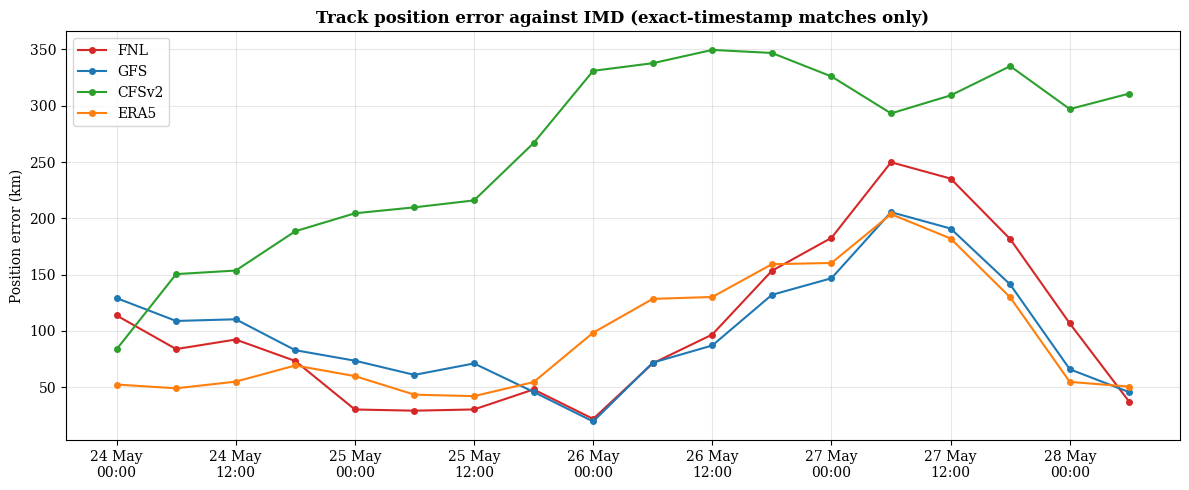

In [25]:
# CHUNK 23: A03: position error over time
fig, ax = plt.subplots(figsize=(12, 5))   # <----------------------- change this to resize the figure (inches)
for name in MODEL_NAMES:
    ax.plot(pairs[name]["time_utc"], pairs[name]["track_error_km"], marker="o", markersize=4,
            color=COLORS[name], label=name)
ax.set_ylabel("Position error (km)")
ax.set_title("Track position error against IMD (exact-timestamp matches only)", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend()
format_time_axis(ax)
plt.tight_layout()
plt.savefig(OUTDIRS["A03_track_validation"] + "/Remal_A2_Position_Error_Series.png", dpi=300, bbox_inches="tight")   # <----------------------- change this to set the saved-figure resolution
plt.show()

In [26]:
# CHUNK 24: A03: track statistics table
track_rows = []
for name in MODEL_NAMES:
    p = pairs[name]
    error = p["track_error_km"]
    worst = error.idxmax()
    track_rows.append({
        "model": name, "n_matched": len(p), "mean_error_km": error.mean(),
        "track_rmse_km": np.sqrt((error**2).mean()), "max_error_km": error.max(),
        "max_error_time": p.loc[worst, "time_utc"],
        "n_carried_forward_in_sample": int(p["carried_forward"].sum()),
    })

track_table = pd.DataFrame(track_rows)
track_table.to_csv(OUTDIRS["A03_track_validation"] + "/Remal_A2_Track_Stats.csv", index=False)
show(track_table, 1)

model  n_matched  mean_error_km  track_rmse_km  max_error_km            max_error_time  n_carried_forward_in_sample
  FNL         18          102.1          123.5         249.9 2024-05-27 06:00:00+00:00                            3
  GFS         18           99.5          110.9         205.5 2024-05-27 06:00:00+00:00                            3
CFSv2         18          261.7          273.3         349.6 2024-05-26 12:00:00+00:00                            0
 ERA5         18           95.8          109.2         203.8 2024-05-27 06:00:00+00:00                            3


# A04: Translation-speed comparison

Translation speed is calculated from consecutive storm positions divided by the **actual elapsed hours**. The main comparison uses the same IMD/model timestamps as A03 and places each speed at the interval midpoint. A supplementary CSV repeats the model calculation with the unsmoothed centroid track so the effect of smoothing can be inspected.


model  n_intervals  bias_kmh  mae_kmh  rmse_kmh  correlation
  FNL           17     -1.24     5.51      7.54        -0.18
  GFS           17     -0.99     6.05      7.60        -0.36
CFSv2           17      0.30     4.91      5.72        -0.51
 ERA5           17     -0.93     5.93      7.61        -0.29


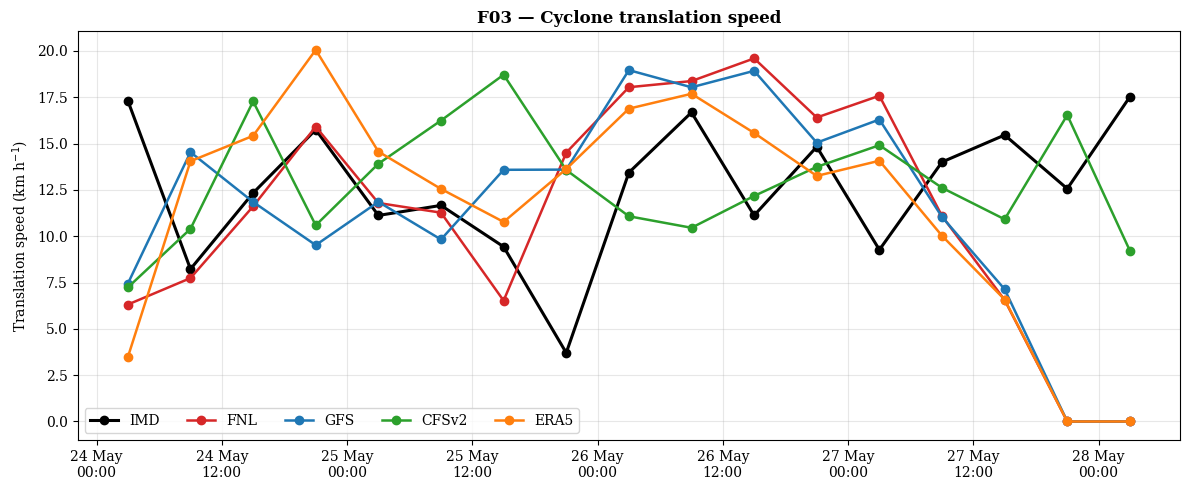

In [27]:
# CHUNK 24B: A04 translation speed
def translation_speed_table(track, lat_col, lon_col, source_name):
    rows = []
    track = track.sort_values("time_utc").reset_index(drop=True)

    for i in range(1, len(track)):
        t0 = pd.to_datetime(track.loc[i - 1, "time_utc"], utc=True)
        t1 = pd.to_datetime(track.loc[i, "time_utc"], utc=True)
        dt_h = (t1 - t0) / pd.Timedelta(hours=1)

        if dt_h <= 0:
            continue

        d_km = distance_km(
            track.loc[i - 1, lat_col], track.loc[i - 1, lon_col],
            track.loc[i, lat_col], track.loc[i, lon_col],
        )

        rows.append({
            "source": source_name,
            "start_time_utc": t0,
            "end_time_utc": t1,
            "mid_time_utc": t0 + (t1 - t0) / 2,
            "elapsed_hours": float(dt_h),
            "distance_km": float(d_km),
            "translation_speed_kmh": float(d_km / dt_h),
        })

    return pd.DataFrame(rows)


translation_main = []
translation_sensitivity = []

for name in MODEL_NAMES:
    p = pairs[name].copy()

    # Main: model and IMD over identical interval endpoints.
    model_track = p[["time_utc", "lat_model", "lon_model"]].copy()
    imd_track = p[["time_utc", "lat_imd", "lon_imd"]].copy()

    model_speed = translation_speed_table(
        model_track, "lat_model", "lon_model", name
    )
    imd_speed = translation_speed_table(
        imd_track, "lat_imd", "lon_imd", "IMD"
    )

    merged = model_speed.merge(
        imd_speed[["start_time_utc", "end_time_utc", "translation_speed_kmh"]],
        on=["start_time_utc", "end_time_utc"],
        how="inner",
        suffixes=("_model", "_imd"),
    )

    merged["model"] = name
    merged["speed_bias_kmh"] = (
        merged["translation_speed_kmh_model"] -
        merged["translation_speed_kmh_imd"]
    )
    translation_main.append(merged)

    # Sensitivity: unsmoothed centroid at the same model timestamps.
    centroid_track = centroid[name][["time_utc", "latitude", "longitude"]].copy()
    centroid_track = centroid_track[
        centroid_track["time_utc"].isin(p["time_utc"])
    ].copy()

    unsmoothed_speed = translation_speed_table(
        centroid_track, "latitude", "longitude", name + "_unsmoothed_centroid"
    )
    translation_sensitivity.append(unsmoothed_speed)

translation_main = pd.concat(translation_main, ignore_index=True)
translation_sensitivity = pd.concat(translation_sensitivity, ignore_index=True)

translation_main.to_csv(
    OUTDIRS["A04_translation_speed"] + "/A04_translation_speed_main.csv",
    index=False
)
translation_sensitivity.to_csv(
    OUTDIRS["A04_translation_speed"] + "/A04_translation_speed_unsmoothed_sensitivity.csv",
    index=False
)

# Summary scores
speed_rows = []
for name in MODEL_NAMES:
    s = translation_main[translation_main["model"] == name]
    stats_speed = error_stats(
        s["translation_speed_kmh_model"],
        s["translation_speed_kmh_imd"],
    )
    speed_rows.append({
        "model": name,
        "n_intervals": stats_speed["n"],
        "bias_kmh": stats_speed["bias"],
        "mae_kmh": stats_speed["mae"],
        "rmse_kmh": stats_speed["rmse"],
        "correlation": stats_speed["corr"],
    })

translation_score_table = pd.DataFrame(speed_rows)
translation_score_table.to_csv(
    OUTDIRS["A04_translation_speed"] + "/T03_translation_speed_scores.csv",
    index=False
)
show(translation_score_table, 2)

# F03
fig, ax = plt.subplots(figsize=(12, 5))   # <----------------------- change this to resize the figure (inches)

# Plot IMD once using the first model's identical matched support.
first_name = MODEL_NAMES[0]
first = translation_main[translation_main["model"] == first_name]
ax.plot(
    first["mid_time_utc"],
    first["translation_speed_kmh_imd"],
    color=COLORS["IMD"], linewidth=2.2, marker="o", label="IMD"
)

for name in MODEL_NAMES:
    s = translation_main[translation_main["model"] == name]
    ax.plot(
        s["mid_time_utc"],
        s["translation_speed_kmh_model"],
        color=COLORS[name], linewidth=1.8, marker="o", label=name
    )

ax.set_ylabel("Translation speed (km h$^{-1}$)")
ax.set_title("F03 — Cyclone translation speed")
ax.grid(alpha=0.3)
ax.legend(ncol=5)
format_time_axis(ax)
plt.tight_layout()
plt.savefig(
    OUTDIRS["A04_translation_speed"] + "/F03_Translation_Speed.png",
    dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
)
plt.show()


# A05: Maximum-wind validation
Uses every exact IMD-matching timestamp common to all four WRF runs. The figures show all matched values; the saved statistics include both ordinary paired-observation scores and time-weighted scores to account for irregular temporal spacing.

In [28]:
# CHUNK 25: A05/A06 shared plotting functions
def plot_series_and_bias(
    imd_col,
    model_col,
    bias_col,
    ylabel,
    bias_label,
    title,
    filename,
    out_key,
    pair_source,
):

    # `pair_source` is explicit so the 6-hourly track pair table and the
    # full-time intensity pair table can never be mixed accidentally.
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 9),   # <----------------------- change this to resize the figure (inches)
        sharex=True
    )

    common_plot_times = pd.DatetimeIndex(
        pair_source[MODEL_NAMES[0]]["time_utc"]
    )

    imd_plot = imd[
        imd["time_utc"].isin(common_plot_times)
    ].copy().sort_values("time_utc")

    axes[0].plot(
        imd_plot["time_utc"],
        imd_plot[imd_col],
        color="black",
        marker="o",
        markersize=4,
        linewidth=2,
        label="IMD"
    )

    for name in MODEL_NAMES:

        p = pair_source[name]

        axes[0].plot(
            p["time_utc"],
            p[model_col],
            marker="o",
            markersize=3,
            color=COLORS[name],
            label=name
        )

    axes[0].set_ylabel(
        ylabel
    )

    axes[0].set_title(
        title + " | N = " + str(len(common_plot_times)),
        fontweight="bold"
    )

    axes[0].grid(
        alpha=0.3
    )

    axes[0].legend()


    for name in MODEL_NAMES:

        p = pair_source[name]

        axes[1].plot(
            p["time_utc"],
            p[bias_col],
            marker="o",
            markersize=4,
            color=COLORS[name],
            label=name
        )

    axes[1].axhline(
        0,
        color="black",
        linewidth=1
    )

    axes[1].set_ylabel(
        bias_label
    )

    axes[1].grid(
        alpha=0.3
    )

    axes[1].legend()

    format_time_axis(
        axes[1]
    )

    plt.tight_layout()

    plt.savefig(
        OUTDIRS[out_key]
        + "/"
        + filename,
        dpi=300,   # <----------------------- change this to set the saved-figure resolution
        bbox_inches="tight"
    )

    plt.show()


def plot_scatter(
    imd_col,
    model_col,
    label,
    filename,
    out_key,
    pair_source,
):

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)   # <----------------------- change this to resize the figure (inches)
    )

    for i in range(4):

        name = MODEL_NAMES[i]
        ax = axes[i]

        p = pair_source[name].dropna(
            subset=[
                imd_col,
                model_col
            ]
        )

        if len(p) == 0:

            ax.set_title(
                name
                + ": no data"
            )

            continue

        ax.scatter(
            p[imd_col],
            p[model_col],
            color=COLORS[name],
            s=35
        )

        low = min(
            p[imd_col].min(),
            p[model_col].min()
        ) - 2

        high = max(
            p[imd_col].max(),
            p[model_col].max()
        ) + 2

        ax.plot(
            [low, high],
            [low, high],
            color="black",
            linestyle="--",
            linewidth=1
        )

        ax.set_xlim(
            low,
            high
        )

        ax.set_ylim(
            low,
            high
        )

        ax.set_aspect(
            "equal"
        )

        s = error_stats(
            p[model_col],
            p[imd_col]
        )

        ax.text(
            0.04,
            0.96,
            "N = "
            + str(s["n"])
            + "\nBias = "
            + str(round(s["bias"], 2))
            + "\nRMSE = "
            + str(round(s["rmse"], 2))
            + "\nr = "
            + str(round(s["corr"], 2)),
            transform=ax.transAxes,
            va="top",
            bbox=dict(
                facecolor="white",
                alpha=0.8,
                edgecolor="grey"
            )
        )

        ax.set_xlabel(
            "IMD "
            + label
        )

        ax.set_ylabel(
            name
            + " "
            + label
        )

        ax.set_title(
            name,
            fontweight="bold"
        )

        ax.grid(
            alpha=0.3
        )

    plt.tight_layout()

    plt.savefig(
        OUTDIRS[out_key]
        + "/"
        + filename,
        dpi=300,   # <----------------------- change this to set the saved-figure resolution
        bbox_inches="tight"
    )

    plt.show()


### How to read these wind figures
- Top: black = IMD maximum wind, coloured = each model's strongest wind near the centre.
- Bottom (bias): each dot = model minus IMD. Below zero = model too weak.
- Scatter: dashed diagonal is perfect agreement; the box shows N, bias, RMSE, r.
- `N` should be 30 when every supplied IMD timestamp has an exact WRF file in all four experiments; otherwise the notebook reports the smaller common support explicitly.


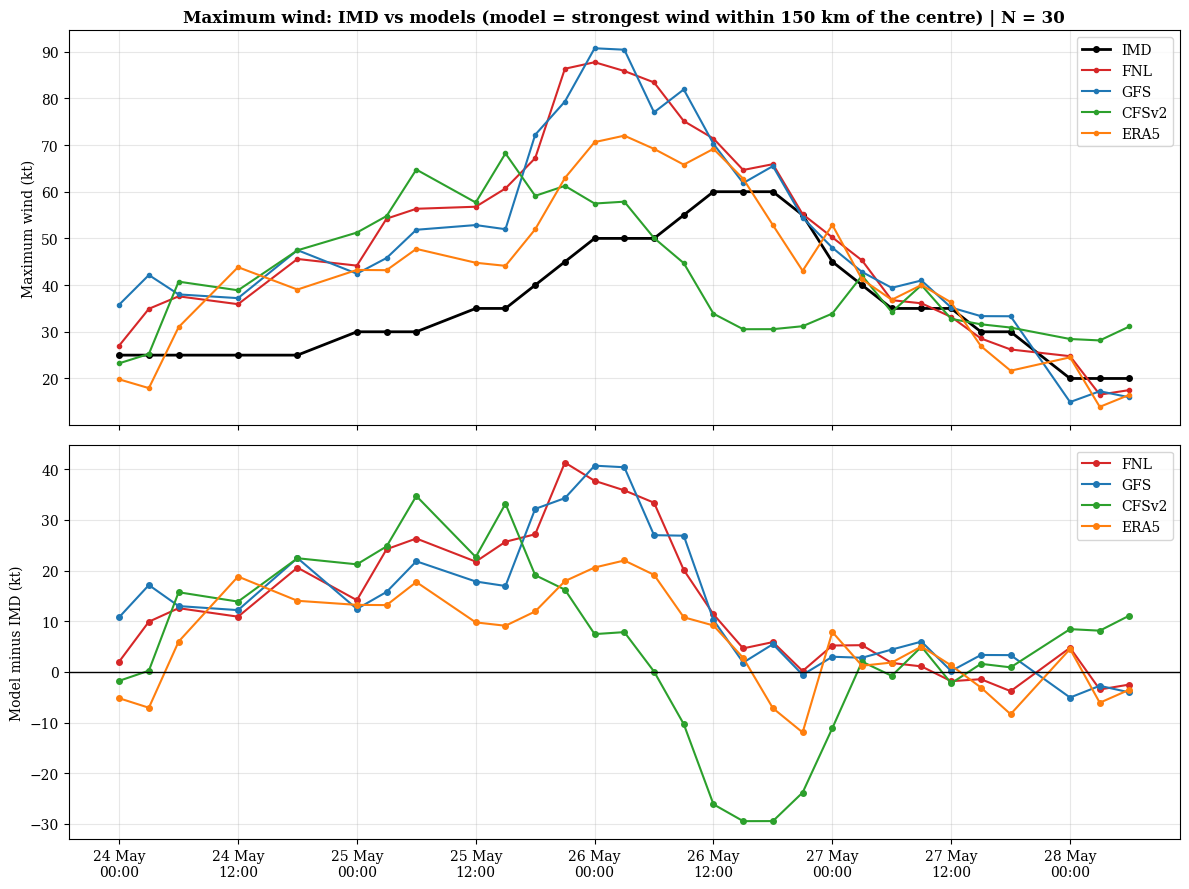

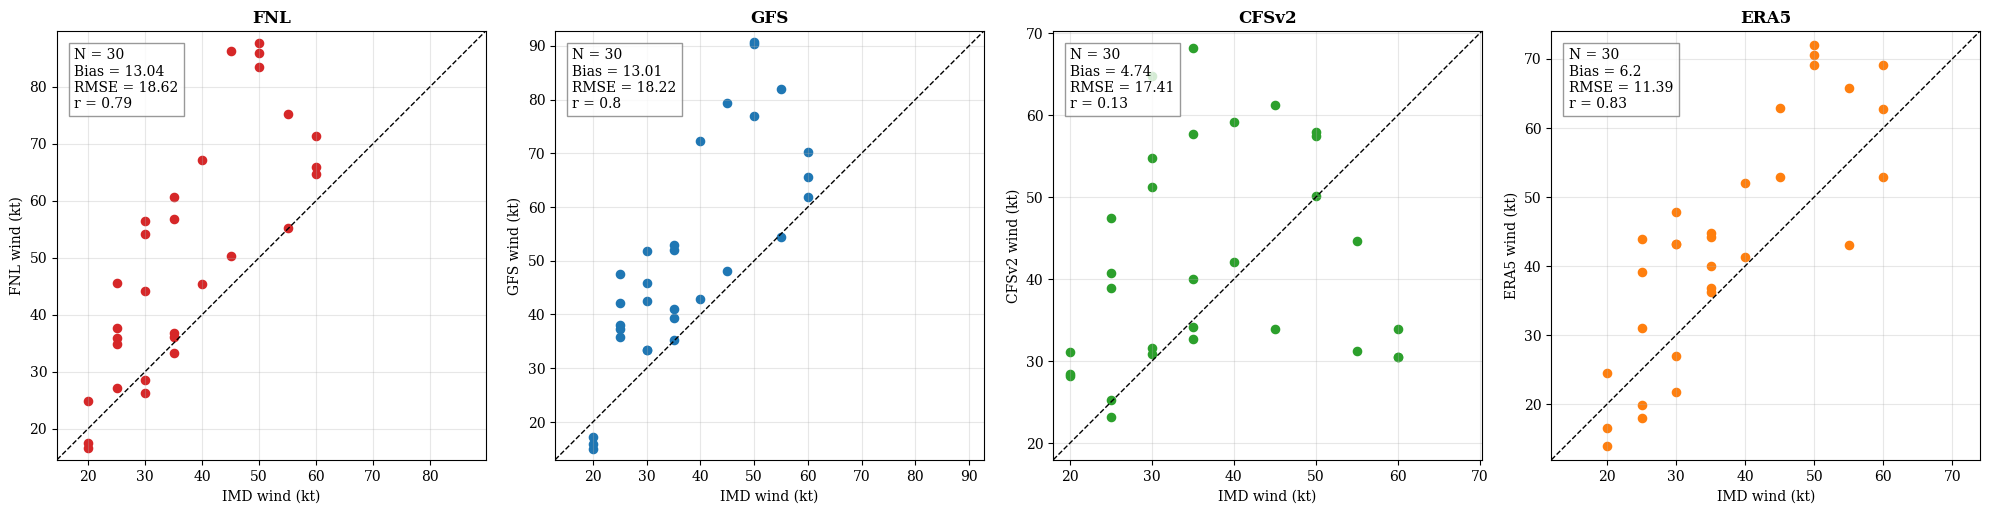

In [29]:
# ============================================================
# CHUNK 26
# A05: WIND VALIDATION
# Wind time series, bias and scatter figures
# ============================================================

plot_series_and_bias(

    imd_col="wind_kt",

    model_col="wind_model",

    bias_col="wind_bias_kt",

    ylabel="Maximum wind (kt)",

    bias_label="Model minus IMD (kt)",

    title=(
        "Maximum wind: IMD vs models "
        "(model = strongest wind within "
        + str(WIND_RADIUS_KM)
        + " km of the centre)"
    ),

    filename="F04_Wind_Series_and_Bias.png",

    out_key="A05_wind_validation",
    pair_source=intensity_pairs,
)


plot_scatter(

    "wind_imd",

    "wind_model",

    "wind (kt)",

    "S03_Wind_Scatter.png",

    "A05_wind_validation",
    intensity_pairs
)

In [30]:
# CHUNK 27: A05 wind statistics table (all exact IMD matches)
# Both ordinary paired-observation scores and time-weighted scores are saved.
wind_rows = []

for name in MODEL_NAMES:
    p = intensity_pairs[name].copy().sort_values("time_utc")

    ordinary = error_stats(
        p["wind_model"],
        p["wind_imd"]
    )

    weighted = time_weighted_error_stats(
        p["time_utc"],
        p["wind_model"],
        p["wind_imd"]
    )

    wind_rows.append({
        "model": name,
        "n": ordinary["n"],
        "mean_bias_kt": ordinary["bias"],
        "mae_kt": ordinary["mae"],
        "rmse_kt": ordinary["rmse"],
        "correlation": ordinary["corr"],
        "time_weighted_bias_kt": weighted["bias"],
        "time_weighted_mae_kt": weighted["mae"],
        "time_weighted_rmse_kt": weighted["rmse"],
        "time_weighted_correlation": weighted["corr"],
        "time_weighted_duration_h": weighted["duration_hours"],
    })

wind_table = pd.DataFrame(wind_rows)
wind_table.to_csv(
    OUTDIRS["A05_wind_validation"] + "/T03_A05_Wind_Stats_All_IMD_Matches.csv",
    index=False
)

print("A05: ordinary and time-weighted statistics are both reported because the full IMD timeline is irregularly sampled.")
show(wind_table, 3)

A05: ordinary and time-weighted statistics are both reported because the full IMD timeline is irregularly sampled.
model  n  mean_bias_kt  mae_kt  rmse_kt  correlation  time_weighted_bias_kt  time_weighted_mae_kt  time_weighted_rmse_kt  time_weighted_correlation  time_weighted_duration_h
  FNL 30        13.040  13.905   18.623        0.789                 13.555                14.357                 18.571                      0.778                     102.0
  GFS 30        13.013  13.839   18.224        0.798                 13.336                14.094                 18.093                      0.790                     102.0
CFSv2 30         4.735  13.735   17.414        0.133                  6.635                14.524                 17.968                      0.091                     102.0
 ERA5 30         6.196   9.684   11.393        0.830                  7.193                10.261                 11.860                      0.803                     102.0


In [31]:
# CHUNK 28: A05 centre wind vs radius-max wind comparison
definition_rows = []
for name in MODEL_NAMES:
    centre_stats = error_stats(intensity_pairs[name]["wind_centre_model"], intensity_pairs[name]["wind_imd"])
    radius_stats = error_stats(intensity_pairs[name]["wind_model"], intensity_pairs[name]["wind_imd"])
    definition_rows.append({
        "model": name, "centre_bias_kt": centre_stats["bias"], "centre_rmse_kt": centre_stats["rmse"],
        "centre_corr": centre_stats["corr"], "radius_max_bias_kt": radius_stats["bias"],
        "radius_max_rmse_kt": radius_stats["rmse"], "radius_max_corr": radius_stats["corr"],
    })
wind_definition_table = pd.DataFrame(definition_rows)
wind_definition_table.to_csv(OUTDIRS["A05_wind_validation"] + "/S04_A05_Wind_Definition_Comparison_All_IMD_Matches.csv", index=False)
print("Radius used for the strongest wind:", WIND_RADIUS_KM, "km")
show(wind_definition_table, 2)

Radius used for the strongest wind: 150 km
model  centre_bias_kt  centre_rmse_kt  centre_corr  radius_max_bias_kt  radius_max_rmse_kt  radius_max_corr
  FNL          -26.17           30.09        -0.04               13.04               18.62             0.79
  GFS          -28.85           32.28        -0.30               13.01               18.22             0.80
CFSv2          -29.29           32.54        -0.29                4.74               17.41             0.13
 ERA5          -28.14           31.52        -0.18                6.20               11.39             0.83


# A06: Central-pressure validation
Uses every exact IMD-matching timestamp common to all four WRF runs. The saved statistics include both ordinary paired-observation scores and time-weighted scores to account for irregular temporal spacing.

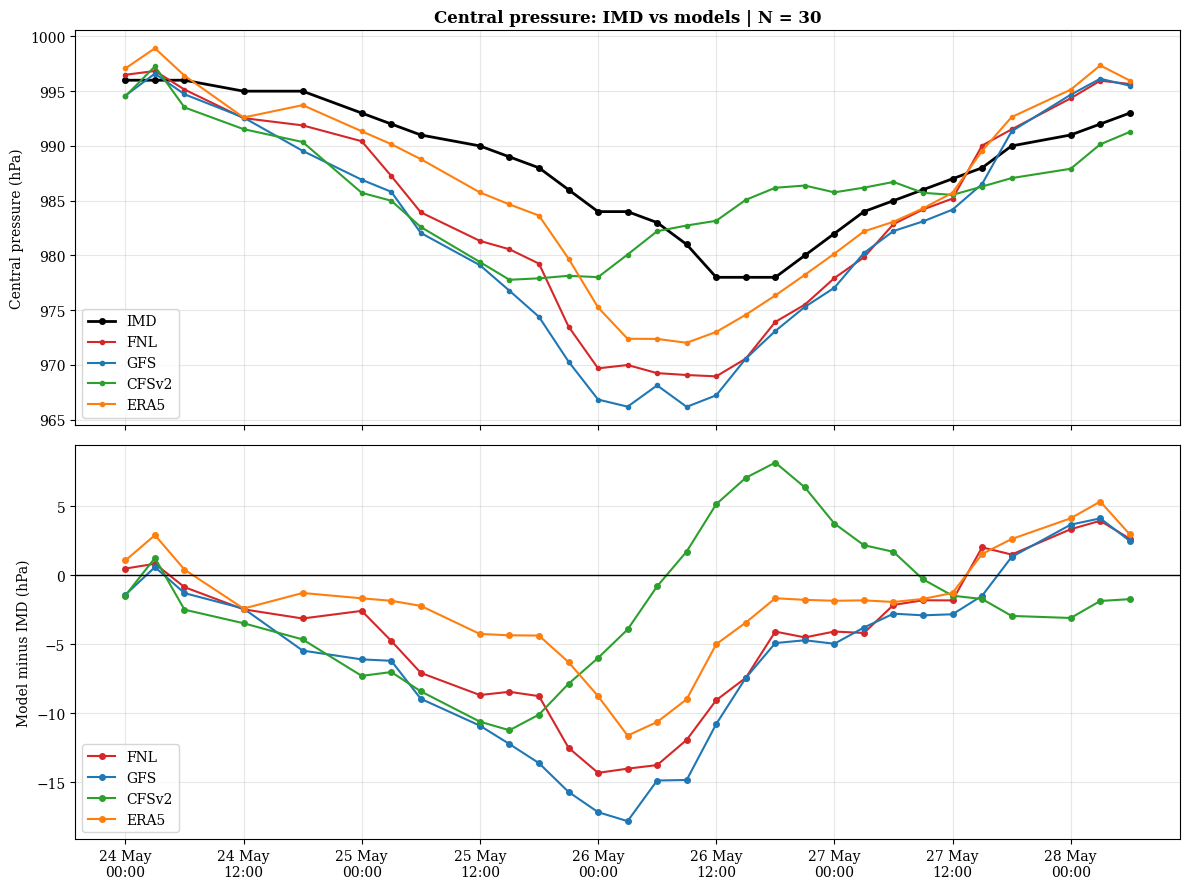

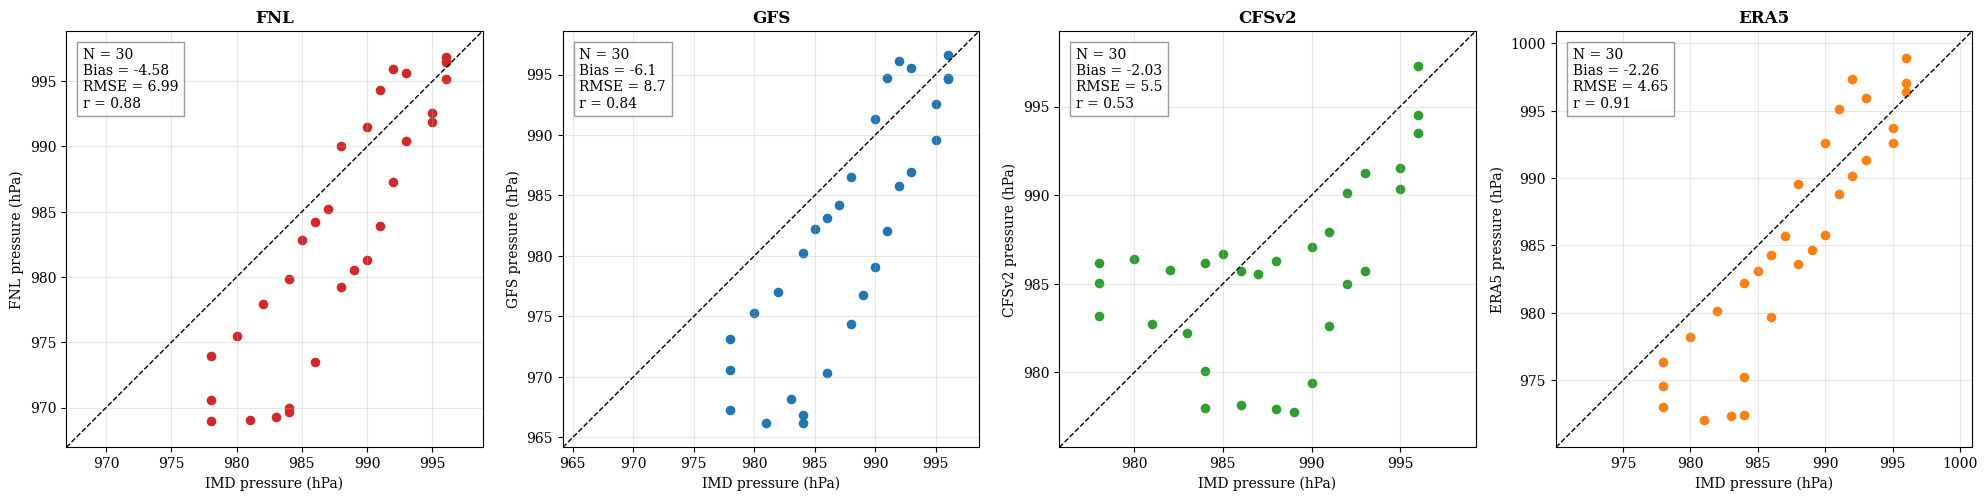

In [32]:
# ============================================================
# CHUNK 29
# A06: CENTRAL PRESSURE VALIDATION
# Pressure time series, bias and scatter figures
# ============================================================

plot_series_and_bias(

    imd_col="pressure_hpa",

    model_col="pres_model",

    bias_col="pres_bias_hpa",

    ylabel="Central pressure (hPa)",

    bias_label="Model minus IMD (hPa)",

    title="Central pressure: IMD vs models",

    filename="F04_Pressure_Series_and_Bias.png",

    out_key="A06_pressure_validation",
    pair_source=intensity_pairs,
)


plot_scatter(

    "pres_imd",

    "pres_model",

    "pressure (hPa)",

    "S03_Pressure_Scatter.png",

    "A06_pressure_validation",
    intensity_pairs
)

In [33]:
# CHUNK 30: A06 pressure statistics table (all exact IMD matches)
# Both ordinary paired-observation scores and time-weighted scores are saved.
pressure_rows = []

for name in MODEL_NAMES:
    p = intensity_pairs[name].copy().sort_values("time_utc")

    ordinary = error_stats(
        p["pres_model"],
        p["pres_imd"]
    )

    weighted = time_weighted_error_stats(
        p["time_utc"],
        p["pres_model"],
        p["pres_imd"]
    )

    pressure_rows.append({
        "model": name,
        "n": ordinary["n"],
        "mean_bias_hpa": ordinary["bias"],
        "mae_hpa": ordinary["mae"],
        "rmse_hpa": ordinary["rmse"],
        "correlation": ordinary["corr"],
        "time_weighted_bias_hpa": weighted["bias"],
        "time_weighted_mae_hpa": weighted["mae"],
        "time_weighted_rmse_hpa": weighted["rmse"],
        "time_weighted_correlation": weighted["corr"],
        "time_weighted_duration_h": weighted["duration_hours"],
    })

pressure_table = pd.DataFrame(pressure_rows)
pressure_table.to_csv(
    OUTDIRS["A06_pressure_validation"] + "/T03_A06_Pressure_Stats_All_IMD_Matches.csv",
    index=False
)

print("A06: ordinary and time-weighted statistics are both reported because the full IMD timeline is irregularly sampled.")
show(pressure_table, 3)

A06: ordinary and time-weighted statistics are both reported because the full IMD timeline is irregularly sampled.
model  n  mean_bias_hpa  mae_hpa  rmse_hpa  correlation  time_weighted_bias_hpa  time_weighted_mae_hpa  time_weighted_rmse_hpa  time_weighted_correlation  time_weighted_duration_h
  FNL 30         -4.579    5.569     6.993        0.883                  -4.461                  5.385                   6.757                      0.881                     102.0
  GFS 30         -6.104    6.921     8.696        0.839                  -5.960                  6.754                   8.448                      0.837                     102.0
CFSv2 30         -2.028    4.525     5.504        0.534                  -2.493                  4.696                   5.611                      0.539                     102.0
 ERA5 30         -2.264    3.669     4.655        0.914                  -2.179                  3.511                   4.463                      0.911            

# A07: Peak intensity, timing and change rates
Maximum wind, minimum pressure, when they occur, and the timing error (model minus IMD), with every tied IMD peak listed. These calculations use the full exact-match `intensity_pairs` timeline rather than only the 6-hourly track times.

**Folder:** `A07_intensity_change`

In [34]:
# CHUNK 31: A07 peak intensity and timing table (all exact IMD matches)
def peak_rows_for(name, pair):

    rows = []
    for variable, imd_col, model_col, kind in [
        ("Maximum wind (kt)", "wind_imd", "wind_model", "max"),
        ("Minimum pressure (hPa)", "pres_imd", "pres_model", "min"),
    ]:
        p = pair.dropna(subset=[imd_col, model_col])
        if kind == "max":
            imd_value = p[imd_col].max(); model_value = p[model_col].max()
        else:
            imd_value = p[imd_col].min(); model_value = p[model_col].min()

        imd_tied = p[np.isclose(p[imd_col], imd_value)]["time_utc"].tolist()
        model_tied = p[np.isclose(p[model_col], model_value)]["time_utc"].tolist()
        model_time = model_tied[0]

        differences = [(model_time - t) / pd.Timedelta(hours=1) for t in imd_tied]
        nearest = min(differences, key=abs)
        tied_text = "; ".join([t.strftime("%d %b %H:%M") for t in imd_tied])

        rows.append({
            "model": name, "variable": variable, "imd_peak": imd_value, "imd_peak_times": tied_text,
            "n_tied_imd_times": len(imd_tied), "model_peak": model_value,
            "model_peak_time": model_time.strftime("%d %b %H:%M"), "value_error": model_value - imd_value,
            "timing_error_h_nearest_tie": nearest, "timing_error_h_vs_first_tie": differences[0],
            "timing_error_h_vs_last_tie": differences[-1],
        })
    return rows


peak_rows = []
for name in MODEL_NAMES:
    peak_rows = peak_rows + peak_rows_for(name, intensity_pairs[name])

peak_table = pd.DataFrame(peak_rows)
peak_table.to_csv(OUTDIRS["A07_intensity_change"] + "/T04_A07_Peak_Intensity_Timing_All_IMD_Matches.csv", index=False)
show(peak_table, 1)

model               variable  imd_peak                           imd_peak_times  n_tied_imd_times  model_peak model_peak_time  value_error  timing_error_h_nearest_tie  timing_error_h_vs_first_tie  timing_error_h_vs_last_tie
  FNL      Maximum wind (kt)        60 26 May 12:00; 26 May 15:00; 26 May 18:00                 3        87.7    26 May 00:00         27.7                       -12.0                        -12.0                       -18.0
  FNL Minimum pressure (hPa)       978 26 May 12:00; 26 May 15:00; 26 May 18:00                 3       969.0    26 May 12:00         -9.0                         0.0                          0.0                        -6.0
  GFS      Maximum wind (kt)        60 26 May 12:00; 26 May 15:00; 26 May 18:00                 3        90.7    26 May 00:00         30.7                       -12.0                        -12.0                       -18.0
  GFS Minimum pressure (hPa)       978 26 May 12:00; 26 May 15:00; 26 May 18:00                 3       

## A07B. Intensity-change rates

This adds the checklist item that was missing from the previous notebook: interval wind-change and pressure-change rates, plus exact 24-hour changes where both endpoints exist. Rates use the actual elapsed time and are not relabelled as 24-hour changes.


In [35]:
# CHUNK 31B: A07 intensity-change rates
intensity_rate_rows = []
change24_rows = []

for name in MODEL_NAMES:
    p = intensity_pairs[name].sort_values("time_utc").reset_index(drop=True)

    # Consecutive-interval rates
    for i in range(1, len(p)):
        t0 = p.loc[i - 1, "time_utc"]
        t1 = p.loc[i, "time_utc"]
        dt_h = (t1 - t0) / pd.Timedelta(hours=1)
        if dt_h <= 0:
            continue

        intensity_rate_rows.append({
            "model": name,
            "start_time_utc": t0,
            "end_time_utc": t1,
            "elapsed_hours": float(dt_h),
            "model_dwind_dt_kt_per_h": (p.loc[i, "wind_model"] - p.loc[i - 1, "wind_model"]) / dt_h,
            "imd_dwind_dt_kt_per_h": (p.loc[i, "wind_imd"] - p.loc[i - 1, "wind_imd"]) / dt_h,
            "model_dpressure_dt_hpa_per_h": (p.loc[i, "pres_model"] - p.loc[i - 1, "pres_model"]) / dt_h,
            "imd_dpressure_dt_hpa_per_h": (p.loc[i, "pres_imd"] - p.loc[i - 1, "pres_imd"]) / dt_h,
        })

    # Exact 24-hour changes only
    lookup = p.set_index("time_utc")
    for t0 in p["time_utc"]:
        t1 = t0 + pd.Timedelta(hours=24)
        if t1 in lookup.index:
            a = lookup.loc[t0]
            b = lookup.loc[t1]
            change24_rows.append({
                "model": name,
                "start_time_utc": t0,
                "end_time_utc": t1,
                "model_wind_change_24h_kt": b["wind_model"] - a["wind_model"],
                "imd_wind_change_24h_kt": b["wind_imd"] - a["wind_imd"],
                "model_pressure_change_24h_hpa": b["pres_model"] - a["pres_model"],
                "imd_pressure_change_24h_hpa": b["pres_imd"] - a["pres_imd"],
            })

intensity_rate_table = pd.DataFrame(intensity_rate_rows)
change24_table = pd.DataFrame(change24_rows)

intensity_rate_table.to_csv(
    OUTDIRS["A07_intensity_change"] + "/A07_intensity_change_rates.csv", index=False
)
change24_table.to_csv(
    OUTDIRS["A07_intensity_change"] + "/A07_exact_24h_changes.csv", index=False
)

# Compact summary of strongest sampled deepening/weakening and wind change.
rate_summary_rows = []
for name in MODEL_NAMES:
    s = intensity_rate_table[intensity_rate_table["model"] == name]
    rate_summary_rows.append({
        "model": name,
        "max_model_wind_increase_kt_per_h": s["model_dwind_dt_kt_per_h"].max(),
        "max_imd_wind_increase_kt_per_h": s["imd_dwind_dt_kt_per_h"].max(),
        "max_model_deepening_hpa_per_h": -s["model_dpressure_dt_hpa_per_h"].min(),
        "max_imd_deepening_hpa_per_h": -s["imd_dpressure_dt_hpa_per_h"].min(),
    })

rate_summary = pd.DataFrame(rate_summary_rows)
rate_summary.to_csv(
    OUTDIRS["A07_intensity_change"] + "/T04_intensity_change_summary.csv", index=False
)
show(rate_summary, 2)


model  max_model_wind_increase_kt_per_h  max_imd_wind_increase_kt_per_h  max_model_deepening_hpa_per_h  max_imd_deepening_hpa_per_h
  FNL                              6.38                            1.67                           1.91                          1.0
  GFS                              6.74                            1.67                           1.36                          1.0
CFSv2                              5.16                            1.67                           1.25                          1.0
 ERA5                              4.35                            1.67                           1.49                          1.0


# A08: Landfall comparison
Landfall is found by walking each track across the WRF land mask. By default the IMD reference crossing is derived from the IMD track with the same land mask, as in the paper, so observed and simulated tracks share one coastline definition. To use the official IMD bulletin landfall instead, set `IMD_LANDFALL_TIME`, `IMD_LANDFALL_LAT` and `IMD_LANDFALL_LON` in S4.

**Folder:** `A08_landfall` (output filenames keep the legacy `Remal_A6_` prefix, which the paper-figures notebook reads)

In [36]:
# CHUNK 32: A08: land mask and landfall finder
mask_file_name = None
for name in MODEL_NAMES:
    found = list_wrfouts(MODEL_DIRS[name])
    if len(found) > 0:
        mask_file_name = found[0]
        break

mask_file = Dataset(mask_file_name)
grid_lat = np.array(mask_file.variables["XLAT"][0, :, :])
grid_lon = np.array(mask_file.variables["XLONG"][0, :, :])
grid_land = np.array(mask_file.variables["LANDMASK"][0, :, :])
mask_file.close()

def is_land(lat, lon):
    d = (grid_lat - lat)**2 + ((grid_lon - lon) * np.cos(np.radians(lat)))**2
    index = np.unravel_index(np.argmin(d), d.shape)
    return grid_land[index] > 0.5

def find_landfall(track):
    track = track.sort_values("time_utc").reset_index(drop=True)
    land = [is_land(track.loc[i, "latitude"], track.loc[i, "longitude"]) for i in range(len(track))]

    for i in range(len(track) - 1):
        stays_on_land = (i + 2 >= len(track)) or land[i + 2]
        if (not land[i]) and land[i + 1] and stays_on_land:
            lat0, lon0 = track.loc[i, "latitude"], track.loc[i, "longitude"]
            lat1, lon1 = track.loc[i + 1, "latitude"], track.loc[i + 1, "longitude"]
            time0, time1 = track.loc[i, "time_utc"], track.loc[i + 1, "time_utc"]
            for step in range(1, 201):   # <----------------------- change 201/200 to refine the crossing search along each segment
                fraction = step / 200
                lat = lat0 + fraction * (lat1 - lat0)
                lon = lon0 + fraction * (lon1 - lon0)
                if is_land(lat, lon):
                    return {"time_utc": (time0 + fraction * (time1 - time0)).round("min"),
                           "latitude": lat, "longitude": lon}
    return None

In [37]:
# CHUNK 33: A08: IMD landfall
if IMD_LANDFALL_TIME is not None and IMD_LANDFALL_LAT is not None and IMD_LANDFALL_LON is not None:
    imd_landfall = {"time_utc": pd.to_datetime(IMD_LANDFALL_TIME, utc=True),
                    "latitude": IMD_LANDFALL_LAT, "longitude": IMD_LANDFALL_LON}
    imd_landfall_source = "IMD bulletin (entered in settings)"
else:
    imd_landfall = find_landfall(imd)
    imd_landfall_source = "derived from IMD track and WRF land mask"

if imd_landfall is None:
    print("No IMD landfall could be found. Enter IMD_LANDFALL_TIME/LAT/LON in the settings chunk.")
else:
    print("IMD landfall (" + imd_landfall_source + "): time", imd_landfall["time_utc"],
          "lat/lon", round(imd_landfall["latitude"], 2), round(imd_landfall["longitude"], 2))

IMD landfall (derived from IMD track and WRF land mask): time 2024-05-26 17:24:00+00:00 lat/lon 21.64 89.2


In [38]:
# CHUNK 34: A08: model landfall errors table
model_landfalls = {}
crossing_rows = []

if imd_landfall is not None:
    crossing_rows.append({"source": "IMD", "landfall_time_utc": imd_landfall["time_utc"],
                          "latitude": imd_landfall["latitude"], "longitude": imd_landfall["longitude"],
                          "time_error_h": 0.0, "position_error_km": 0.0, "note": imd_landfall_source})

    for name in MODEL_NAMES:
        result = find_landfall(smooth[name])
        model_landfalls[name] = result
        if result is None:
            crossing_rows.append({"source": name, "landfall_time_utc": pd.NaT, "latitude": np.nan,
                                  "longitude": np.nan, "time_error_h": np.nan, "position_error_km": np.nan,
                                  "note": "no sea-to-land crossing found in the track"})
        else:
            crossing_rows.append({
                "source": name, "landfall_time_utc": result["time_utc"],
                "latitude": result["latitude"], "longitude": result["longitude"],
                "time_error_h": (result["time_utc"] - imd_landfall["time_utc"]) / pd.Timedelta(hours=1),
                "position_error_km": distance_km(imd_landfall["latitude"], imd_landfall["longitude"],
                                                 result["latitude"], result["longitude"]),
                "note": "model minus IMD",
            })

landfall_table = pd.DataFrame(crossing_rows)
landfall_table.to_csv(OUTDIRS["A08_landfall"] + "/Remal_A6_Landfall_Crossings.csv", index=False)
show(landfall_table, 2)

source         landfall_time_utc  latitude  longitude  time_error_h  position_error_km                                     note
   IMD 2024-05-26 17:24:00+00:00     21.64      89.20          0.00               0.00 derived from IMD track and WRF land mask
   FNL 2024-05-26 13:44:00+00:00     21.88      90.08         -3.67              94.86                          model minus IMD
   GFS 2024-05-26 14:55:00+00:00     22.11      89.91         -2.48              90.18                          model minus IMD
 CFSv2 2024-05-25 22:01:00+00:00     20.23      86.56        -19.38             315.58                          model minus IMD
  ERA5 2024-05-26 10:21:00+00:00     21.87      89.81         -7.05              67.84                          model minus IMD


In [39]:
# CHUNK 35: A08: conditions around landfall table
window_tables = []
if imd_landfall is not None:
    for name in MODEL_NAMES:
        p = pairs[name].copy()
        p["hours_from_imd_landfall"] = (p["time_utc"] - imd_landfall["time_utc"]) / pd.Timedelta(hours=1)
        near = p[p["hours_from_imd_landfall"].abs() <= LANDFALL_WINDOW_HOURS].copy()
        near.insert(0, "model", name)
        window_tables.append(near)

    landfall_window = pd.concat(window_tables, ignore_index=True)
    landfall_window = landfall_window[["model", "time_utc", "hours_from_imd_landfall", "track_error_km",
                                       "wind_imd", "wind_model", "wind_bias_kt",
                                       "pres_imd", "pres_model", "pres_bias_hpa"]]
    landfall_window.to_csv(OUTDIRS["A08_landfall"] + "/Remal_A6_Landfall_Window.csv", index=False)
    show(landfall_window, 1)

model                  time_utc  hours_from_imd_landfall  track_error_km  wind_imd  wind_model  wind_bias_kt  pres_imd  pres_model  pres_bias_hpa
  FNL 2024-05-26 06:00:00+00:00                    -11.4            71.3        50        83.4          33.4       983       969.3          -13.7
  FNL 2024-05-26 12:00:00+00:00                     -5.4            96.9        60        71.4          11.4       978       969.0           -9.0
  FNL 2024-05-26 18:00:00+00:00                      0.6           153.5        60        65.9           5.9       978       973.9           -4.1
  FNL 2024-05-27 00:00:00+00:00                      6.6           182.7        45        50.2           5.2       982       977.9           -4.1
  GFS 2024-05-26 06:00:00+00:00                    -11.4            71.9        50        77.0          27.0       983       968.1          -14.9
  GFS 2024-05-26 12:00:00+00:00                     -5.4            87.1        60        70.3          10.3       978      

### How to read this map
Lines are the tracks (black = IMD). Each star is a landfall point.

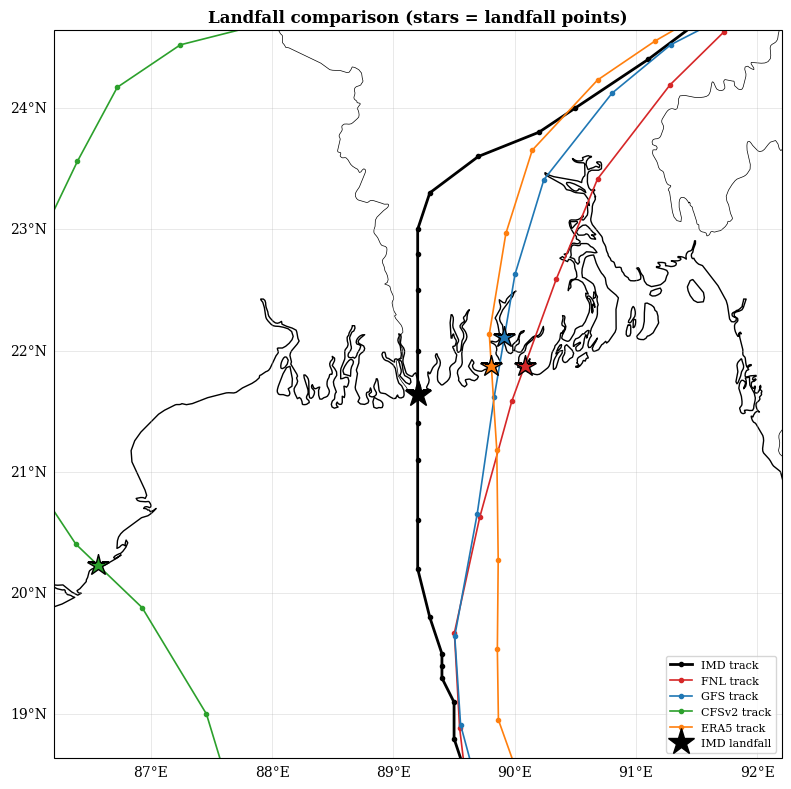

In [40]:
# CHUNK 36: A08: landfall map
if imd_landfall is not None:
    fig = plt.figure(figsize=(9, 8))   # <----------------------- change this to resize the figure (inches)
    ax = plt.axes(projection=ccrs.PlateCarree())
    box = [imd_landfall["longitude"] - 3, imd_landfall["longitude"] + 3,   # <----------------------- change this to zoom the landfall map (degrees)
          imd_landfall["latitude"] - 3, imd_landfall["latitude"] + 3]
    draw_base_map(ax, box)

    ax.plot(imd["longitude"], imd["latitude"], color="black", marker="o", markersize=3, linewidth=2,
            label="IMD track", transform=ccrs.PlateCarree())
    for name in MODEL_NAMES:
        ax.plot(smooth[name]["longitude"], smooth[name]["latitude"], color=COLORS[name], marker="o",
                markersize=3, linewidth=1.2, label=name + " track", transform=ccrs.PlateCarree())
        if model_landfalls[name] is not None:
            ax.plot(model_landfalls[name]["longitude"], model_landfalls[name]["latitude"], marker="*",
                    markersize=16, color=COLORS[name], markeredgecolor="black", linestyle="none",
                    transform=ccrs.PlateCarree())

    ax.plot(imd_landfall["longitude"], imd_landfall["latitude"], marker="*", markersize=20, color="black",
            linestyle="none", label="IMD landfall", transform=ccrs.PlateCarree())
    ax.set_title("Landfall comparison (stars = landfall points)", fontweight="bold")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTDIRS["A08_landfall"] + "/Remal_A6_Landfall_Map.png", dpi=300, bbox_inches="tight")   # <----------------------- change this to set the saved-figure resolution
    plt.show()

# A09: Common-period PDI comparison
PDI is calculated over the identical matched period for IMD and all four experiments as the trapezoidal integral of `V^3` using wind in m s-1 and actual elapsed **seconds**. The main output is one five-row table (IMD + four WRF runs). This is a common-period intensity index, not total storm energy.

In [41]:
# CHUNK 37: A09 corrected trapezoidal PDI helper
def time_weighted_pdi(times, wind_kt, min_wind_kt=0):
    """
    Common-period PDI = integral of V^3 dt using trapezoidal integration.

    Wind is converted from knots to m s-1 and elapsed time is used in seconds,
    so the returned SI value has units m^3 s^-2. Actual timestamp gaps are used;
    no fixed 3-hour or 6-hour interval is assumed.

    When a positive threshold is requested, values below the threshold contribute
    zero V^3 at that endpoint. The current notebook default is 0 kt.
    """
    table = pd.DataFrame({
        "time_utc": pd.to_datetime(times, utc=True),
        "wind_kt": np.asarray(wind_kt, dtype=float),
    }).dropna().sort_values("time_utc").reset_index(drop=True)

    if len(table) < 2:
        return np.nan, int((table["wind_kt"] >= min_wind_kt).sum()), 0, 0.0

    if table["time_utc"].duplicated().any():
        raise ValueError("PDI timestamps must be unique.")

    wind_ms = table["wind_kt"].to_numpy(dtype=float) * 1852.0 / 3600.0
    wind_cube = np.where(
        table["wind_kt"].to_numpy(dtype=float) >= min_wind_kt,
        wind_ms**3,
        0.0,
    )

    pdi = 0.0
    integrated_seconds = 0.0
    valid_intervals = 0

    for i in range(len(table) - 1):
        dt_seconds = (
            table.loc[i + 1, "time_utc"] - table.loc[i, "time_utc"]
        ).total_seconds()

        if dt_seconds <= 0:
            raise ValueError("PDI timestamps must be strictly increasing.")

        pdi = pdi + 0.5 * (wind_cube[i] + wind_cube[i + 1]) * dt_seconds
        integrated_seconds = integrated_seconds + dt_seconds
        valid_intervals = valid_intervals + 1

    n_above_threshold = int(
        (table["wind_kt"] >= min_wind_kt).sum()
    )

    return (
        float(pdi),
        n_above_threshold,
        valid_intervals,
        integrated_seconds / 3600.0,
    )

In [42]:
# CHUNK 38: A09 five-row common-period PDI table (IMD + four WRF runs)
# All sources use the identical full-time support and actual elapsed seconds.
pdi_rows = []

reference_pair = intensity_pairs[MODEL_NAMES[0]].copy().sort_values("time_utc")

pdi_imd, n_imd, intervals_imd, hours_imd = time_weighted_pdi(
    reference_pair["time_utc"],
    reference_pair["wind_imd"].to_numpy(),
    PDI_MIN_WIND_KT,
)

pdi_rows.append({
    "source": "IMD",
    "start_utc": reference_pair["time_utc"].iloc[0],
    "end_utc": reference_pair["time_utc"].iloc[-1],
    "n_timestamps": len(reference_pair),
    "valid_intervals": intervals_imd,
    "integrated_hours": hours_imd,
    "wind_threshold_kt": PDI_MIN_WIND_KT,
    "n_above_threshold": n_imd,
    "pdi_m3_s_minus2": pdi_imd,
    "difference_from_imd_pct": 0.0,
    "model_over_imd": 1.0,
})

for name in MODEL_NAMES:
    p = intensity_pairs[name].dropna(
        subset=["wind_imd", "wind_model"]
    ).sort_values("time_utc").reset_index(drop=True)

    pdi_model, n_model, valid_intervals, integrated_hours = time_weighted_pdi(
        p["time_utc"],
        p["wind_model"].to_numpy(),
        PDI_MIN_WIND_KT,
    )

    if pdi_imd > 0:
        difference_pct = 100.0 * (pdi_model - pdi_imd) / pdi_imd
        ratio = pdi_model / pdi_imd
    else:
        difference_pct = np.nan
        ratio = np.nan

    pdi_rows.append({
        "source": name,
        "start_utc": p["time_utc"].iloc[0],
        "end_utc": p["time_utc"].iloc[-1],
        "n_timestamps": len(p),
        "valid_intervals": valid_intervals,
        "integrated_hours": integrated_hours,
        "wind_threshold_kt": PDI_MIN_WIND_KT,
        "n_above_threshold": n_model,
        "pdi_m3_s_minus2": pdi_model,
        "difference_from_imd_pct": difference_pct,
        "model_over_imd": ratio,
    })

pdi_table = pd.DataFrame(pdi_rows)
pdi_table.to_csv(
    OUTDIRS["A09_pdi"] + "/T05_A09_Common_Period_PDI.csv",
    index=False
)

print(
    "PDI uses trapezoidal integration of V^3 with actual elapsed seconds; "
    "units = m^3 s^-2; threshold =",
    PDI_MIN_WIND_KT,
    "kt."
)
show(pdi_table, 3)

PDI uses trapezoidal integration of V^3 with actual elapsed seconds; units = m^3 s^-2; threshold = 0 kt.
source                 start_utc                   end_utc  n_timestamps  valid_intervals  integrated_hours  wind_threshold_kt  n_above_threshold  pdi_m3_s_minus2  difference_from_imd_pct  model_over_imd
   IMD 2024-05-24 00:00:00+00:00 2024-05-28 06:00:00+00:00            30               29             102.0                  0                 30     3.250623e+09                    0.000           1.000
   FNL 2024-05-24 00:00:00+00:00 2024-05-28 06:00:00+00:00            30               29             102.0                  0                 30     9.190174e+09                  182.720           2.827
   GFS 2024-05-24 00:00:00+00:00 2024-05-28 06:00:00+00:00            30               29             102.0                  0                 30     9.026508e+09                  177.686           2.777
 CFSv2 2024-05-24 00:00:00+00:00 2024-05-28 06:00:00+00:00            30       

# A10: Rainfall validation against IMERG Final V07B
WRF accumulated-rainfall maps, the matching IMERG accumulation, difference maps, a regional 6-hour rain-rate series and area-weighted validation scores. IMERG files are discovered and read at run time; nothing about their structure is hard-coded beyond what each file's own metadata confirms.

**Folder:** `A10_rainfall`

In [43]:
# CHUNK 39: Rainfall: IMERG file reader
imerg_files = sorted(glob.glob(IMERG_DIR + "/*.HDF5"))   # <----------------------- change this pattern if your IMERG files differ
print("IMERG files found:", len(imerg_files))

RAINFALL_START = EXPECTED_START
RAINFALL_END = EXPECTED_END

def imerg_file_window(path):
    # IMERG half-hourly filenames encode their own start/end time; we still verify
    # against the file's internal time_bnds rather than trusting the filename alone.
    name = os.path.basename(path)
    parts = name.split(".")
    date_part = parts[4].split("-")
    yyyymmdd = date_part[0]
    start_hhmmss = date_part[1].lstrip("S")
    end_hhmmss = date_part[2].lstrip("E")
    start = pd.to_datetime(yyyymmdd + start_hhmmss, format="%Y%m%d%H%M%S", utc=True)
    end = pd.to_datetime(yyyymmdd + end_hhmmss, format="%Y%m%d%H%M%S", utc=True)
    return start, end

def read_imerg_file(path):
    # Reads Grid/precipitation, Grid/lat, Grid/lon, Grid/time, Grid/time_bnds and VERIFIES
    # units, fill value and dimension order from the file's own metadata rather than assuming.
    with h5py.File(path, "r") as f:

        precip_ds = f["Grid/precipitation"]
        lat = f["Grid/lat"][:]
        lon = f["Grid/lon"][:]

        units = precip_ds.attrs.get("units", b"")
        if isinstance(units, bytes):
            units = units.decode()
        fill_value = precip_ds.attrs.get("_FillValue", -9999.9)

        precip = precip_ds[:]   # shape as stored; checked below, not assumed

        # Verify dimension order against the length of lat/lon rather than assuming (time, lon, lat).
        if precip.ndim == 3:
            shape = precip.shape
            if shape[1] == len(lon) and shape[2] == len(lat):
                precip2d = precip[0].T          # -> (lat, lon)
            elif shape[1] == len(lat) and shape[2] == len(lon):
                precip2d = precip[0]            # already (lat, lon)
            else:
                raise ValueError("Unexpected precipitation shape " + str(shape)
                                 + " for lat=" + str(len(lat)) + ", lon=" + str(len(lon)))
        else:
            raise ValueError("Unexpected precipitation ndim: " + str(precip.ndim))

        precip2d = precip2d.astype(float)
        precip2d[np.isclose(precip2d, fill_value)] = np.nan

        if "Grid/time_bnds" in f:
            time_bnds = f["Grid/time_bnds"][:]
            time_units_attr = f["Grid/time"].attrs.get("units", b"")
            if isinstance(time_units_attr, bytes):
                time_units_attr = time_units_attr.decode()
            # "seconds since 1980-01-06 00:00:00 UTC" per the sample metadata; parsed from the
            # attribute text rather than hard-coded, falling back to the documented epoch if parsing fails.
            try:
                epoch_text = time_units_attr.split("since")[1].strip()
                epoch = pd.to_datetime(epoch_text, utc=True)
            except Exception:
                epoch = pd.Timestamp("1980-01-06T00:00:00Z")
            bounds_start = epoch + pd.to_timedelta(float(np.ravel(time_bnds)[0]), unit="s")
            bounds_end = epoch + pd.to_timedelta(float(np.ravel(time_bnds)[1]), unit="s")
            interval_hours = (bounds_end - bounds_start) / pd.Timedelta(hours=1)
        else:
            # No time_bnds in the file; fall back to the filename window, but flag it.
            bounds_start, bounds_end = imerg_file_window(path)
            interval_hours = (bounds_end - bounds_start) / pd.Timedelta(hours=1)
            print("  (no Grid/time_bnds in", os.path.basename(path), "— used filename window instead)")

        return {
            "lat": lat, "lon": lon, "precip_rate_mmhr": precip2d,
            "start": bounds_start, "end": bounds_end, "interval_hours": interval_hours,
            "units": units,
        }

IMERG files found: 240


In [44]:
# CHUNK 40: Rainfall: IMERG accumulation over the period
def imerg_accumulation(files, period_start, period_end, region):
    # Sums rate * actual interval duration for every file whose window falls FULLY within
    # [period_start, period_end]. Partial coverage at the edges is reported, never silently
    # folded into the total, and a partial interval is never labelled complete.
    total = None
    lat_out = lon_out = None
    n_intervals = 0
    covered_hours = 0.0
    skipped_partial = []

    for path in files:
        try:
            data = read_imerg_file(path)
        except Exception as error:
            print("  could not read", os.path.basename(path), ":", error)
            continue

        if data["start"] < period_start or data["end"] > period_end:
            skipped_partial.append(os.path.basename(path))
            continue

        lat_mask = (data["lat"] >= region["lat_min"]) & (data["lat"] <= region["lat_max"])
        lon_mask = (data["lon"] >= region["lon_min"]) & (data["lon"] <= region["lon_max"])

        rate = data["precip_rate_mmhr"][np.ix_(lat_mask, lon_mask)]
        accum = rate * data["interval_hours"]

        if total is None:
            total = np.zeros_like(accum)
            lat_out = data["lat"][lat_mask]
            lon_out = data["lon"][lon_mask]

        valid = np.isfinite(accum)
        total = np.where(valid, np.nan_to_num(total) + np.where(valid, accum, 0), total)
        n_intervals += 1
        covered_hours += data["interval_hours"]

    return {
        "accumulation_mm": total, "lat": lat_out, "lon": lon_out,
        "n_intervals": n_intervals, "covered_hours": covered_hours,
        "n_skipped_partial_files": len(skipped_partial),
    }


imerg_result = None
if len(imerg_files) > 0:
    imerg_result = imerg_accumulation(imerg_files, RAINFALL_START, RAINFALL_END, RAINFALL_REGION)
    print("IMERG accumulation: used", imerg_result["n_intervals"], "half-hourly intervals,",
          round(imerg_result["covered_hours"], 1), "h covered;",
          imerg_result["n_skipped_partial_files"], "files skipped (window not fully inside the period).")
    expected_hours = (RAINFALL_END - RAINFALL_START) / pd.Timedelta(hours=1)
    if imerg_result["covered_hours"] < expected_hours - 0.01:
        print("  NOTE: covered hours (", round(imerg_result["covered_hours"], 1),
              ") is less than the requested period (", expected_hours, "h). This is a PARTIAL total —",
              "it is not labelled as the complete-period accumulation.")
else:
    print("No IMERG .HDF5 files found in", IMERG_DIR, "— rainfall validation skipped.")

IMERG accumulation: used 204 half-hourly intervals, 102.0 h covered; 36 files skipped (window not fully inside the period).


In [45]:
# CHUNK 41: Rainfall: WRF accumulation over the period
def wrf_accumulation(folder, period_start, period_end):
    # WRF accumulation from the DIFFERENCE in (RAINC + RAINNC) between the two bracketing
    # 6-hourly outputs closest to period_start and period_end (needs both endpoints present).
    # Checks for an accumulator reset (end < start) and reports it rather than silently
    # producing a negative total. Bucket-counter terms (I_RAINC/I_RAINNC), if the file writes
    # them, are added automatically when present.
    files = list_wrfouts(folder)
    if len(files) == 0:
        return None

    file_times = []
    for f in files:
        stamp = os.path.basename(f).replace("wrfout_d02_", "")
        file_times.append((pd.to_datetime(stamp, format="%Y-%m-%d_%H_%M_%S", utc=True), f))
    file_times.sort()

    start_file = min(file_times, key=lambda t: abs((t[0] - period_start).total_seconds()))
    end_file = min(file_times, key=lambda t: abs((t[0] - period_end).total_seconds()))

    if start_file[0] == end_file[0]:
        print("  start and end WRF outputs resolve to the same file — no accumulation possible.")
        return None

    def total_rain(path):
        ds = Dataset(path)
        rainc = np.array(ds.variables["RAINC"][0])
        rainnc = np.array(ds.variables["RAINNC"][0])
        total = rainc + rainnc
        if "I_RAINC" in ds.variables and "I_RAINNC" in ds.variables:
            bucket = (np.array(ds.variables["I_RAINC"][0]) + np.array(ds.variables["I_RAINNC"][0])) * 100.0   # <----------------------- change 100.0 to bucket_mm from your namelist
            total = total + bucket
        lat = np.array(ds.variables["XLAT"][0])
        lon = np.array(ds.variables["XLONG"][0])
        ds.close()
        return total, lat, lon

    start_total, lat, lon = total_rain(start_file[1])
    end_total, _, _ = total_rain(end_file[1])

    reset_detected = bool(np.nanmean(end_total) < np.nanmean(start_total))
    accumulation = end_total - start_total

    return {
        "accumulation_mm": accumulation, "lat": lat, "lon": lon,
        "start_file_time": start_file[0], "end_file_time": end_file[0],
        "reset_detected": reset_detected,
    }


wrf_rain = {}
for name in MODEL_NAMES:
    result = wrf_accumulation(MODEL_DIRS[name], RAINFALL_START, RAINFALL_END)
    wrf_rain[name] = result
    if result is None:
        print(name, ": no WRF rainfall accumulation could be computed (missing files).")
    else:
        print(name, ": accumulated", result["start_file_time"], "to", result["end_file_time"],
              "— reset detected:", result["reset_detected"])
        if result["reset_detected"]:
            print("   WARNING: mean(end) < mean(start) — RAINC/RAINNC likely reset during the period.",
                  "This run's I_RAINC/I_RAINNC bucket check above should normally correct for this;",
                  "if the warning persists, the accumulation for", name, "is not reliable as computed.")

FNL : accumulated 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 — reset detected: False
GFS : accumulated 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 — reset detected: False
CFSv2 : accumulated 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 — reset detected: False
ERA5 : accumulated 2024-05-24 00:00:00+00:00 to 2024-05-28 06:00:00+00:00 — reset detected: False


### How to read the rainfall maps
- F06A: IMERG V07B plus the four WRF accumulations (mm), all on one common colour scale.
- F06B: WRF minus IMERG (mm) on a zero-centred diverging scale; red = WRF wetter, blue = WRF drier.

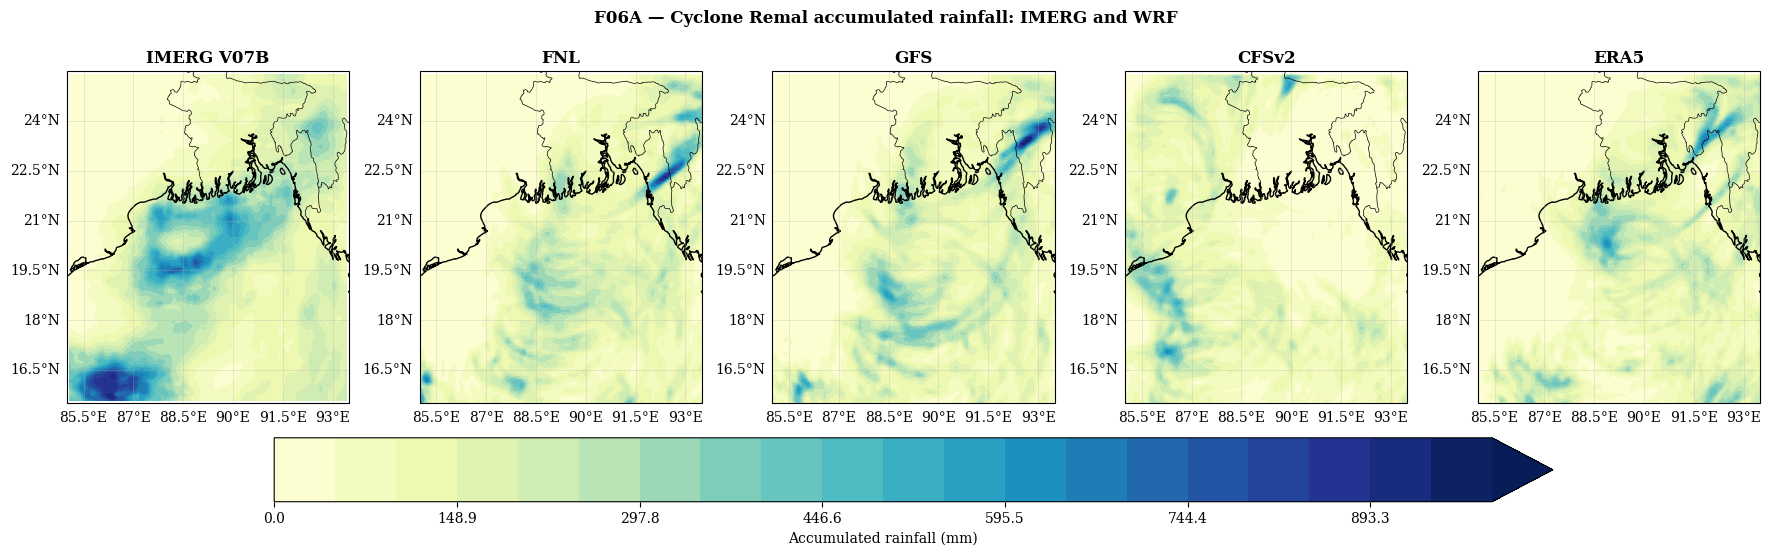

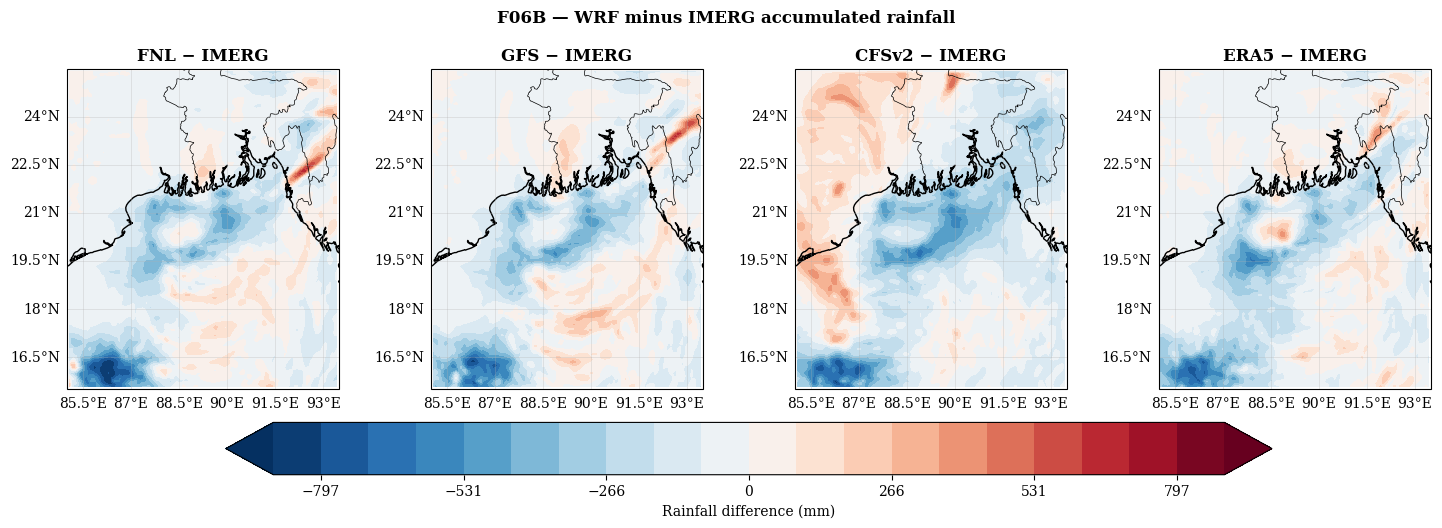

model  n_valid_cells   bias    mae   rmse  corr
  FNL          13924 -76.98 107.03 168.23  0.41
  GFS          13924 -70.79 107.22 163.86  0.44
CFSv2          13924 -85.93 159.96 207.23 -0.12
 ERA5          13924 -81.21 107.60 163.93  0.47


In [46]:
# CHUNK 42: A10 rainfall maps and area-weighted scores
rainfall_scores = []

if imerg_result is not None and imerg_result["accumulation_mm"] is not None:

    common_lon = np.linspace(RAINFALL_REGION["lon_min"], RAINFALL_REGION["lon_max"], 120)   # <----------------------- change 120 to set the common-grid size
    common_lat = np.linspace(RAINFALL_REGION["lat_min"], RAINFALL_REGION["lat_max"], 120)   # <----------------------- change 120 to set the common-grid size
    common_lon_2d, common_lat_2d = np.meshgrid(common_lon, common_lat)

    imerg_on_common = regrid_to_regular(
        imerg_result["lon"], imerg_result["lat"],
        imerg_result["accumulation_mm"],
        common_lon, common_lat, method="linear"
    )

    wrf_common = {}
    for name in MODEL_NAMES:
        if wrf_rain[name] is None:
            wrf_common[name] = None
            continue

        wrf_common[name] = regrid_to_regular(
            wrf_rain[name]["lon"], wrf_rain[name]["lat"],
            wrf_rain[name]["accumulation_mm"],
            common_lon, common_lat, method="linear"
        )

    # ---------- F06A: IMERG + four WRF accumulation maps ----------
    maxima = [np.nanmax(imerg_on_common)]
    for name in MODEL_NAMES:
        if wrf_common[name] is not None and np.isfinite(wrf_common[name]).any():
            maxima.append(np.nanmax(wrf_common[name]))
    vmax = max(maxima) if len(maxima) > 0 else 1.0
    accum_levels = np.linspace(0, max(vmax, 1.0), 21)

    fig, axes = plt.subplots(
        1, 5, figsize=(22, 5.6),   # <----------------------- change this to resize the figure (inches)
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    # IMERG reference
    draw_base_map(
        axes[0],
        [RAINFALL_REGION["lon_min"], RAINFALL_REGION["lon_max"],
         RAINFALL_REGION["lat_min"], RAINFALL_REGION["lat_max"]]
    )
    cf = axes[0].contourf(
        common_lon, common_lat, imerg_on_common,
        levels=accum_levels, cmap="YlGnBu", extend="max",   # <----------------------- change this to use a different colour map
        transform=ccrs.PlateCarree()
    )
    axes[0].set_title("IMERG V07B")

    for i, name in enumerate(MODEL_NAMES, start=1):
        ax = axes[i]
        draw_base_map(
            ax,
            [RAINFALL_REGION["lon_min"], RAINFALL_REGION["lon_max"],
             RAINFALL_REGION["lat_min"], RAINFALL_REGION["lat_max"]]
        )
        if wrf_common[name] is not None:
            cf = ax.contourf(
                common_lon, common_lat, wrf_common[name],
                levels=accum_levels, cmap="YlGnBu", extend="max",   # <----------------------- change this to use a different colour map
                transform=ccrs.PlateCarree()
            )
        ax.set_title(name)

    cbar = fig.colorbar(cf, ax=axes.tolist(), orientation="horizontal",
                        pad=0.08, shrink=0.75)
    cbar.set_label("Accumulated rainfall (mm)")
    fig.suptitle("F06A — Cyclone Remal accumulated rainfall: IMERG and WRF", y=0.99)
    plt.savefig(
        OUTDIRS["A10_rainfall"] + "/F06A_Rainfall_Accumulation_Maps.png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()

    # ---------- F06B: model-minus-IMERG difference maps ----------
    differences = {}
    max_abs = 0.0
    for name in MODEL_NAMES:
        if wrf_common[name] is None:
            differences[name] = None
            continue
        differences[name] = wrf_common[name] - imerg_on_common
        if np.isfinite(differences[name]).any():
            max_abs = max(max_abs, np.nanmax(np.abs(differences[name])))

        stats_now = spatial_error_stats(
            wrf_common[name], imerg_on_common, common_lat_2d
        )
        rainfall_scores.append({"model": name, **stats_now})

    if max_abs == 0:
        max_abs = 1.0
    diff_levels = np.linspace(-max_abs, max_abs, 21)

    fig, axes = plt.subplots(
        1, 4, figsize=(18, 5.4),   # <----------------------- change this to resize the figure (inches)
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    for i, name in enumerate(MODEL_NAMES):
        ax = axes[i]
        draw_base_map(
            ax,
            [RAINFALL_REGION["lon_min"], RAINFALL_REGION["lon_max"],
             RAINFALL_REGION["lat_min"], RAINFALL_REGION["lat_max"]]
        )
        if differences[name] is not None:
            cf2 = ax.contourf(
                common_lon, common_lat, differences[name],
                levels=diff_levels, cmap="RdBu_r", extend="both",   # <----------------------- change this to use a different colour map
                transform=ccrs.PlateCarree()
            )
        ax.set_title(name + " − IMERG")

    cbar = fig.colorbar(cf2, ax=axes.tolist(), orientation="horizontal",
                        pad=0.08, shrink=0.75)
    cbar.set_label("Rainfall difference (mm)")
    fig.suptitle("F06B — WRF minus IMERG accumulated rainfall", y=0.99)
    plt.savefig(
        OUTDIRS["A10_rainfall"] + "/F06B_Rainfall_Difference_Maps.png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()

    rainfall_score_table = pd.DataFrame(rainfall_scores)
    rainfall_score_table.to_csv(
        OUTDIRS["A10_rainfall"] + "/T06_Rainfall_Spatial_Scores.csv",
        index=False
    )
    show(rainfall_score_table, 2)

    # Save common-grid arrays so maps can be regenerated without rereading WRF/HDF5.
    ds_out = xr.Dataset(
        coords={"latitude": common_lat, "longitude": common_lon}
    )
    ds_out["IMERG_accumulation_mm"] = (
        ("latitude", "longitude"), imerg_on_common
    )
    for name in MODEL_NAMES:
        if wrf_common[name] is not None:
            ds_out[name + "_accumulation_mm"] = (
                ("latitude", "longitude"), wrf_common[name]
            )
            ds_out[name + "_minus_IMERG_mm"] = (
                ("latitude", "longitude"), differences[name]
            )
    ds_out.attrs["note"] = (
        "Common-grid interpolation for plotting/statistics. "
        "Interpolation is not conservative remapping."
    )
    ds_out.to_netcdf(
        OUTDIRS["A10_rainfall"] + "/F06_common_grid_rainfall_fields.nc"
    )

else:
    rainfall_score_table = pd.DataFrame()
    print("Rainfall maps skipped — no usable IMERG accumulation.")


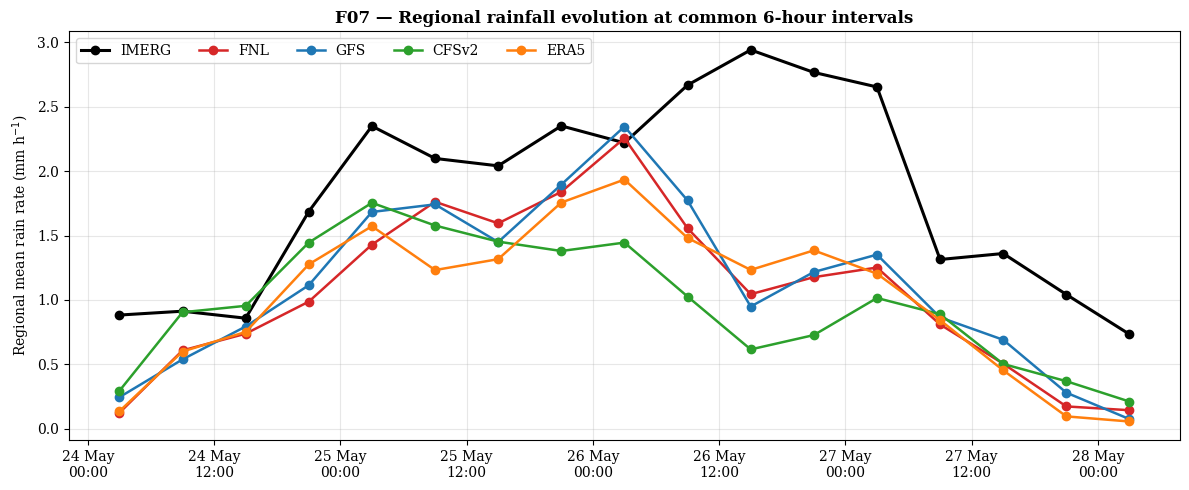

In [47]:
# CHUNK 43: A10 six-hour regional mean rain-rate evolution
# The checklist calls for a common 6-hour cadence, not a cumulative-only curve.

def regional_mean_from_wrf_total(path, region):
    ds = Dataset(path)
    total = np.array(ds.variables["RAINC"][0]) + np.array(ds.variables["RAINNC"][0])

    # Include bucket counters if present.
    if "I_RAINC" in ds.variables and "I_RAINNC" in ds.variables:
        total = total + (
            np.array(ds.variables["I_RAINC"][0]) +
            np.array(ds.variables["I_RAINNC"][0])
        ) * 100.0   # <----------------------- change 100.0 to bucket_mm from your namelist

    lat = np.array(ds.variables["XLAT"][0])
    lon = np.array(ds.variables["XLONG"][0])
    ds.close()

    mask = (
        (lat >= region["lat_min"]) & (lat <= region["lat_max"]) &
        (lon >= region["lon_min"]) & (lon <= region["lon_max"])
    )
    if mask.sum() == 0:
        return np.nan

    weights = np.cos(np.radians(lat))
    valid = mask & np.isfinite(total) & np.isfinite(weights)
    return np.sum(total[valid] * weights[valid]) / np.sum(weights[valid])


rain_6h_rows = []

# WRF 6-hour interval means
for name in MODEL_NAMES:
    files = list_wrfouts(MODEL_DIRS[name])
    time_file = []
    for f in files:
        stamp = os.path.basename(f).replace("wrfout_d02_", "")
        when = pd.to_datetime(stamp, format="%Y-%m-%d_%H_%M_%S", utc=True)
        time_file.append((when, f))
    time_file.sort()

    lookup = {t: f for t, f in time_file}
    t0 = RAINFALL_START
    while t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS) <= RAINFALL_END:
        t1 = t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS)

        if t0 in lookup and t1 in lookup:
            a = regional_mean_from_wrf_total(lookup[t0], RAINFALL_REGION)
            b = regional_mean_from_wrf_total(lookup[t1], RAINFALL_REGION)
            interval_mm = b - a
            rain_6h_rows.append({
                "source": name,
                "start_time_utc": t0,
                "end_time_utc": t1,
                "mid_time_utc": t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS / 2),
                "interval_rain_mm": interval_mm,
                "mean_rain_rate_mm_per_h": interval_mm / RAIN_INTERVAL_HOURS,
            })

        t0 = t1

# IMERG 6-hour interval means from exact half-hour intervals
if len(imerg_files) > 0:
    imerg_records = []
    for path in imerg_files:
        try:
            data = read_imerg_file(path)
        except Exception as error:
            print("IMERG file skipped in time-series step:", os.path.basename(path), error)
            continue

        lat_mask = (
            (data["lat"] >= RAINFALL_REGION["lat_min"]) &
            (data["lat"] <= RAINFALL_REGION["lat_max"])
        )
        lon_mask = (
            (data["lon"] >= RAINFALL_REGION["lon_min"]) &
            (data["lon"] <= RAINFALL_REGION["lon_max"])
        )

        field = data["precip_rate_mmhr"][np.ix_(lat_mask, lon_mask)]
        lat_sub = data["lat"][lat_mask]
        lat_2d = np.repeat(lat_sub[:, None], field.shape[1], axis=1)
        mean_rate = area_weighted_mean(field, lat_2d)

        imerg_records.append({
            "start": data["start"],
            "end": data["end"],
            "mean_rate_mm_per_h": mean_rate,
            "interval_hours": data["interval_hours"],
        })

    imerg_records = pd.DataFrame(imerg_records)

    t0 = RAINFALL_START
    while t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS) <= RAINFALL_END:
        t1 = t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS)

        use = imerg_records[
            (imerg_records["start"] >= t0) &
            (imerg_records["end"] <= t1)
        ].copy()

        covered = use["interval_hours"].sum() if len(use) > 0 else 0.0

        if np.isclose(covered, RAIN_INTERVAL_HOURS):
            interval_mm = np.sum(
                use["mean_rate_mm_per_h"] * use["interval_hours"]
            )
            rain_6h_rows.append({
                "source": "IMERG",
                "start_time_utc": t0,
                "end_time_utc": t1,
                "mid_time_utc": t0 + pd.Timedelta(hours=RAIN_INTERVAL_HOURS / 2),
                "interval_rain_mm": interval_mm,
                "mean_rain_rate_mm_per_h": interval_mm / RAIN_INTERVAL_HOURS,
            })
        else:
            print("IMERG incomplete 6-h bin:", t0, "to", t1, "covered", covered, "h")

        t0 = t1

rain_6h_table = pd.DataFrame(rain_6h_rows)
rain_6h_table.to_csv(
    OUTDIRS["A10_rainfall"] + "/F07_Regional_6h_Rain_Rate.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(12, 5))   # <----------------------- change this to resize the figure (inches)

if len(rain_6h_table) > 0:
    imerg_plot = rain_6h_table[rain_6h_table["source"] == "IMERG"]
    ax.plot(
        imerg_plot["mid_time_utc"], imerg_plot["mean_rain_rate_mm_per_h"],
        color=COLORS["IMD"], linewidth=2.2, marker="o", label="IMERG"
    )

    for name in MODEL_NAMES:
        s = rain_6h_table[rain_6h_table["source"] == name]
        ax.plot(
            s["mid_time_utc"], s["mean_rain_rate_mm_per_h"],
            color=COLORS[name], linewidth=1.8, marker="o", label=name
        )

ax.set_ylabel("Regional mean rain rate (mm h$^{-1}$)")
ax.set_title("F07 — Regional rainfall evolution at common 6-hour intervals")
ax.grid(alpha=0.3)
ax.legend(ncol=5)
format_time_axis(ax)
plt.tight_layout()
plt.savefig(
    OUTDIRS["A10_rainfall"] + "/F07_Regional_6h_Rain_Rate.png",
    dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
)
plt.show()


# A11: Ocean-wind validation against CCMP V3.1
CCMP is used for **spatial ocean-wind assessment only**. IMD remains the reference for cyclone maximum-wind validation (A05); the two are not interchangeable.

**Note on `nobs`:** CCMP is a blended analysis (satellite + a background model), so a grid cell with `nobs = 0` still has an analysed wind value from the background; zero observations does not mean the wind is missing. This matters most for the ERA5-forced run, since ERA5 itself can be part of CCMP's background, so a close match there may partly reflect that shared ancestry rather than independent verification.

**Folder:** `A11_ccmp_wind`

In [48]:
# CHUNK 44: CCMP: file discovery and reader
ccmp_files = sorted(glob.glob(CCMP_DIR + "/CCMP_Wind_Analysis_*_V03.1_L4.nc"))   # <----------------------- change this pattern if your CCMP files differ
print("CCMP files found:", len(ccmp_files))

def read_ccmp_file(path):
    ds = xr.open_dataset(path)
    # Confirm product identity from the file's own metadata rather than assuming from the folder name.
    title = ds.attrs.get("title", "") or ds.attrs.get("source", "")
    print("  ", os.path.basename(path), "— title/source attribute:", title if title else "(none found)")
    return ds

ccmp_data = {}
for path in ccmp_files:
    try:
        ccmp_data[path] = read_ccmp_file(path)
    except Exception as error:
        print("  could not read", os.path.basename(path), ":", error)

def nearest_ccmp_slice(when):
    # Finds the CCMP file/timestamp nearest to `when`; returns None if none is within 1 hour
    # (CCMP's own daily 00/06/12/18 UTC cadence, verified from the file's time coordinate, not assumed).
    best = None
    best_diff = None
    for path, ds in ccmp_data.items():
        if "time" not in ds.coords:
            continue
        times = pd.to_datetime(ds["time"].values, utc=True)
        for t in times:
            diff = abs((t - when).total_seconds())
            if best_diff is None or diff < best_diff:
                best_diff = diff
                best = (path, t)
    if best is not None and best_diff <= 3600:
        return best
    return None

CCMP files found: 5
   CCMP_Wind_Analysis_20240524_V03.1_L4.nc — title/source attribute: RSS CCMP V3.1 6-hourly surface winds (Level 4)
   CCMP_Wind_Analysis_20240525_V03.1_L4.nc — title/source attribute: RSS CCMP V3.1 6-hourly surface winds (Level 4)
   CCMP_Wind_Analysis_20240526_V03.1_L4.nc — title/source attribute: RSS CCMP V3.1 6-hourly surface winds (Level 4)
   CCMP_Wind_Analysis_20240527_V03.1_L4.nc — title/source attribute: RSS CCMP V3.1 6-hourly surface winds (Level 4)
   CCMP_Wind_Analysis_20240528_V03.1_L4.nc — title/source attribute: RSS CCMP V3.1 6-hourly surface winds (Level 4)


In [49]:
# CHUNK 45: CCMP: earth-relative wind rotation
def rotate_to_earth_relative(u_grid, v_grid, wrf_file_path):
    # WRF's U10/V10 are grid-relative on a rotated map projection. Rotate to earth-relative
    # using COSALPHA/SINALPHA when the file provides them; otherwise return the grid-relative
    # components unchanged and flag it (documented limitation for a heavily rotated domain).
    ds = Dataset(wrf_file_path)
    if "COSALPHA" in ds.variables and "SINALPHA" in ds.variables:
        cosalpha = np.array(ds.variables["COSALPHA"][0])
        sinalpha = np.array(ds.variables["SINALPHA"][0])
        ds.close()
        u_earth = u_grid * cosalpha - v_grid * sinalpha
        v_earth = u_grid * sinalpha + v_grid * cosalpha
        return u_earth, v_earth, True
    ds.close()
    return u_grid, v_grid, False

### How to read the CCMP wind maps
- F08A: CCMP V3.1 plus the four WRF 10 m wind-speed maps (earth-relative) with vectors, all on one common colour scale. WRF land points are masked.
- F08B: WRF minus CCMP on a zero-centred diverging scale; red = WRF stronger, blue = WRF weaker.
- One F08A/F08B pair is produced for every time in `MAP_TIMES`.

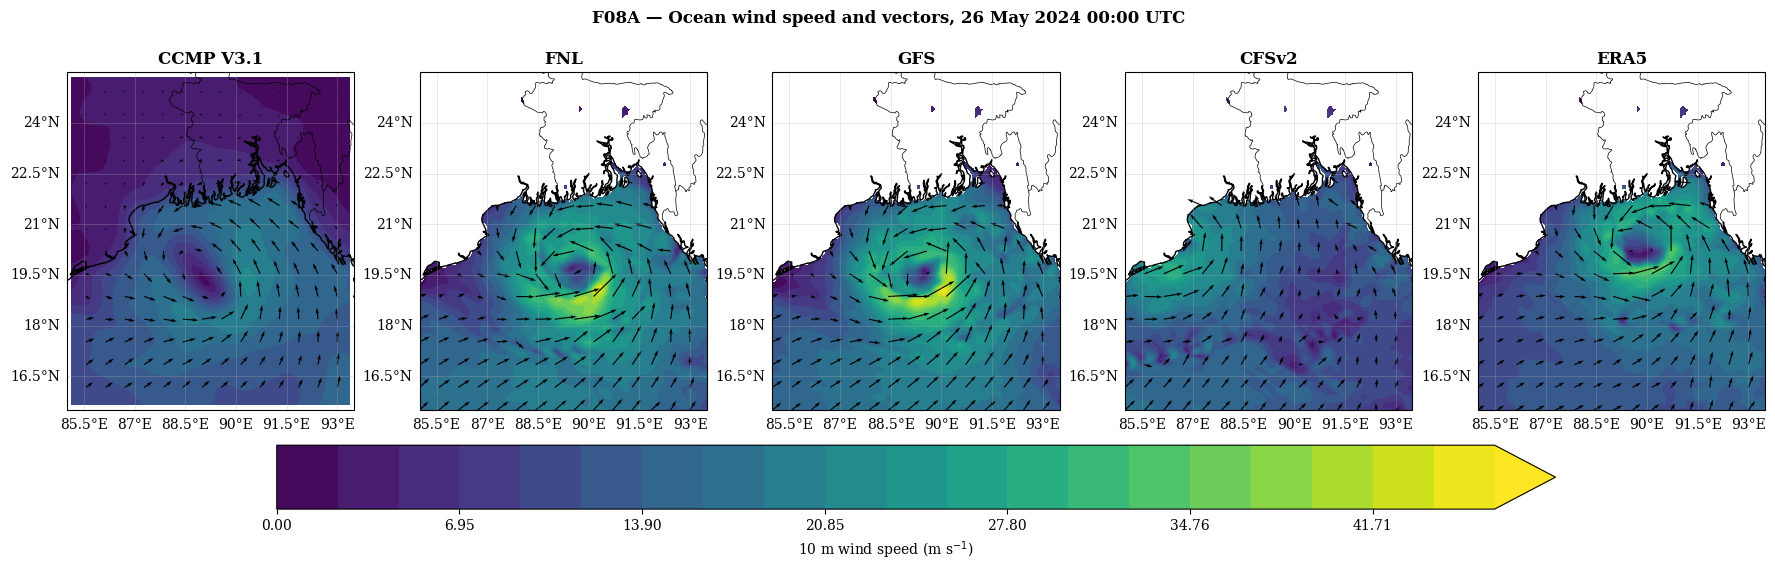

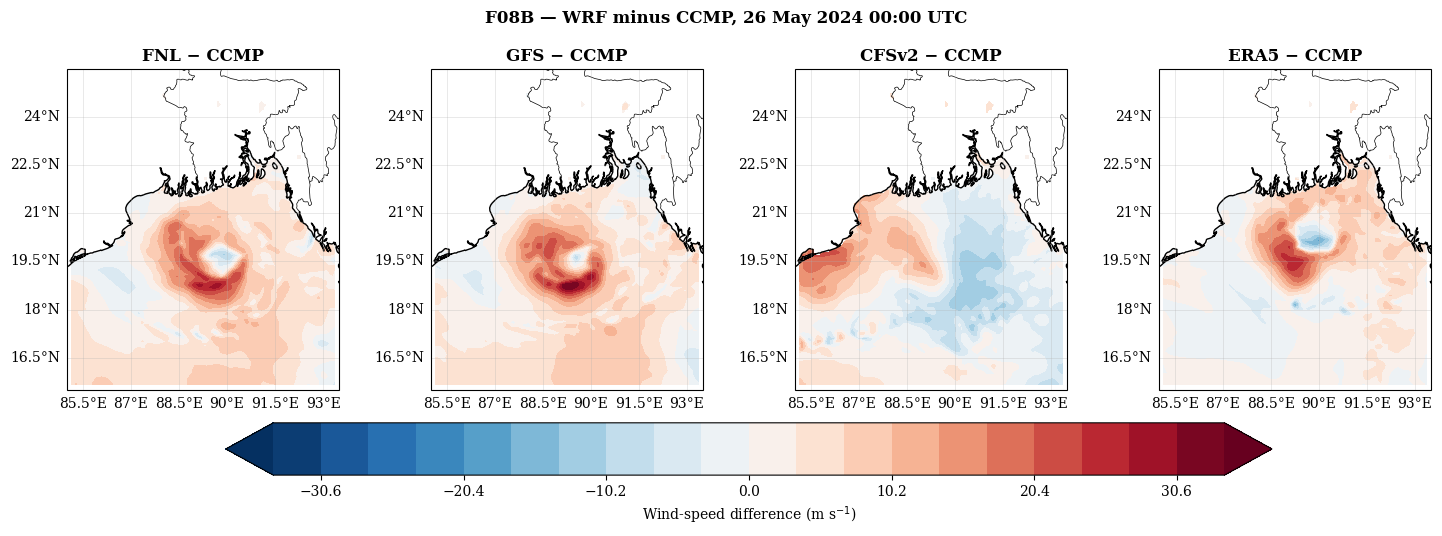

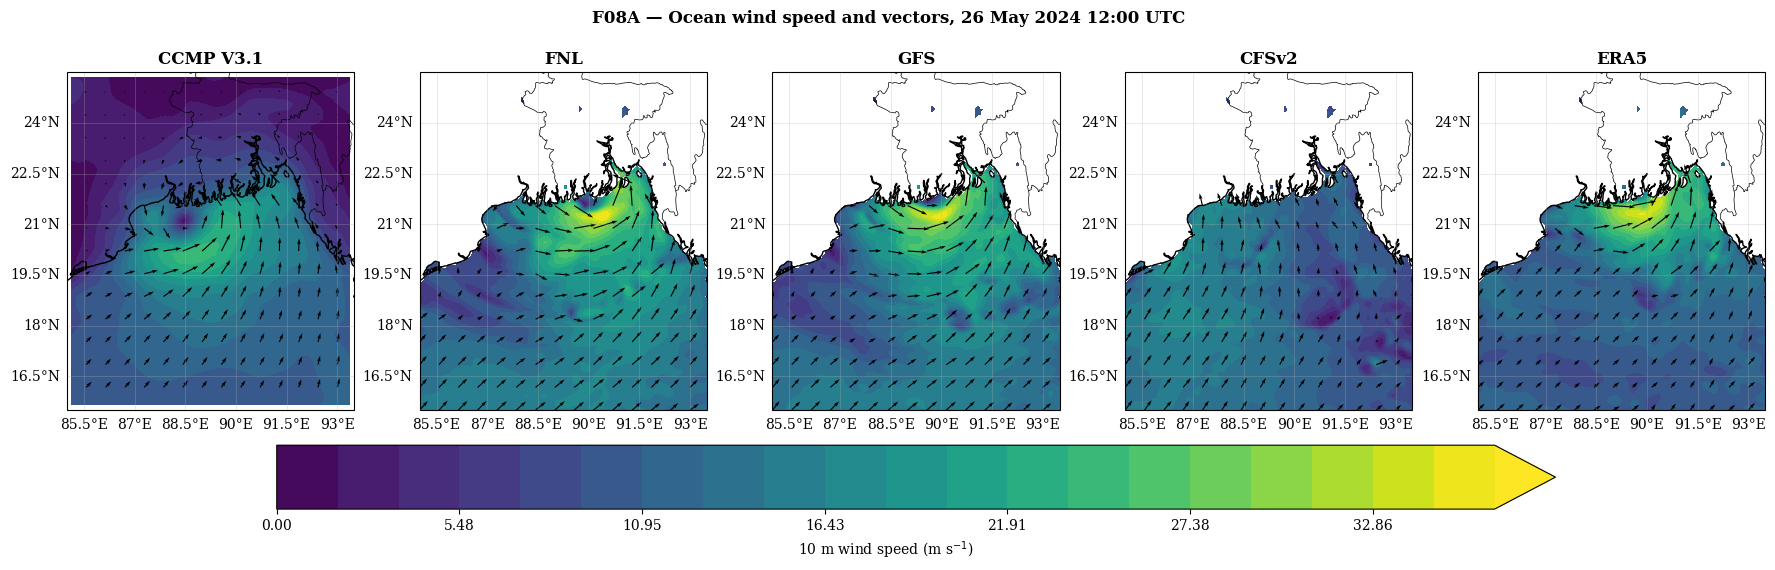

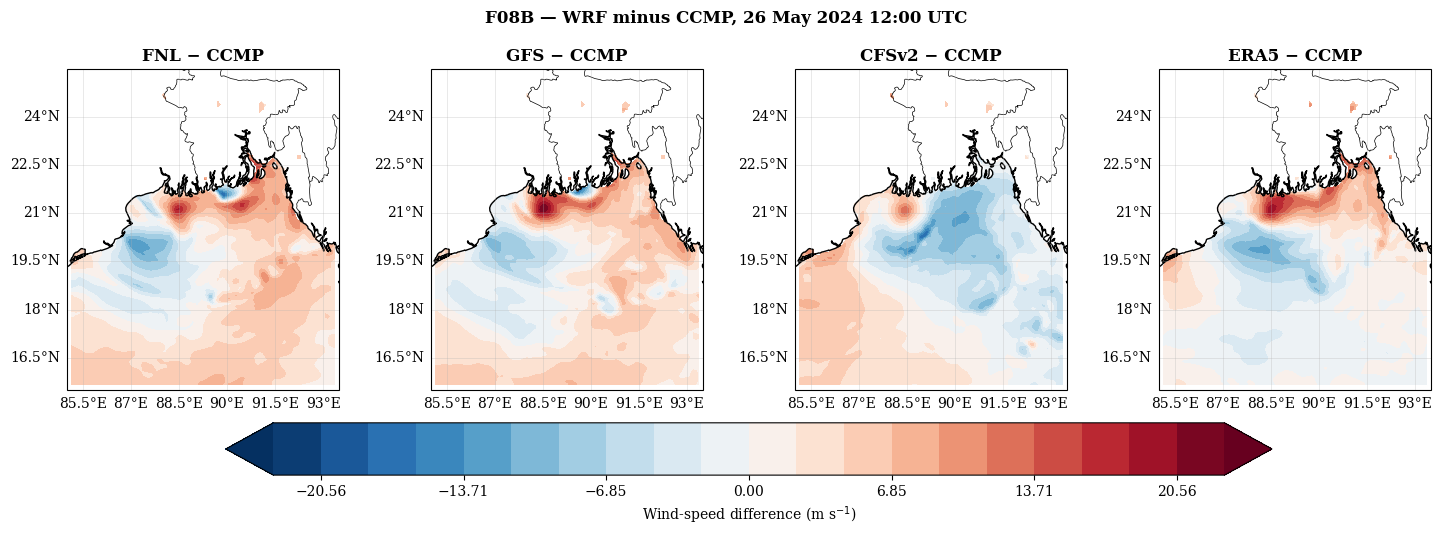

model  speed_bias_ms  speed_mae_ms  speed_rmse_ms  speed_spatial_corr  vector_rmse_ms
CFSv2          -0.50          4.60           5.73               -0.15           11.26
 ERA5           1.26          3.31           5.02                0.48           10.44
  FNL           3.87          5.05           6.20                0.54           11.09
  GFS           3.66          4.78           6.11                0.56           10.45


In [50]:
# CHUNK 46: A11 CCMP maps, vectors, differences and exact-time scores
ccmp_scores = []

def ccmp_components_at_time(match_time):
    matched = nearest_ccmp_slice(match_time)
    if matched is None:
        return None

    ccmp_path, ccmp_time = matched
    ccmp_time_naive = pd.Timestamp(ccmp_time).tz_localize(None)
    ds = ccmp_data[ccmp_path].sel(time=ccmp_time_naive, method="nearest")

    lat_name = "latitude" if "latitude" in ds.coords else "lat"
    lon_name = "longitude" if "longitude" in ds.coords else "lon"

    lat = np.asarray(ds[lat_name].values)
    lon = np.asarray(ds[lon_name].values)

    if "uwnd" in ds and "vwnd" in ds:
        u = np.asarray(ds["uwnd"].values, dtype=float)
        v = np.asarray(ds["vwnd"].values, dtype=float)
    elif "u" in ds and "v" in ds:
        u = np.asarray(ds["u"].values, dtype=float)
        v = np.asarray(ds["v"].values, dtype=float)
    else:
        raise KeyError("Could not find CCMP u/v wind components.")

    speed = np.hypot(u, v)

    lon180 = np.where(lon > 180, lon - 360, lon)
    order = np.argsort(lon180)
    lon180 = lon180[order]
    u = u[:, order]
    v = v[:, order]
    speed = speed[:, order]

    nobs = None
    if "nobs" in ds:
        nobs = np.asarray(ds["nobs"].values)
        if nobs.ndim == 2:
            nobs = nobs[:, order]

    return {
        "path": ccmp_path,
        "time": pd.Timestamp(ccmp_time),
        "lat": lat,
        "lon": lon180,
        "u": u,
        "v": v,
        "speed": speed,
        "nobs": nobs,
    }


if len(ccmp_files) > 0:

    common_lon = np.linspace(
        DIAGNOSTIC_REGION["lon_min"], DIAGNOSTIC_REGION["lon_max"], 120   # <----------------------- change 120 to set the common-grid size
    )
    common_lat = np.linspace(
        DIAGNOSTIC_REGION["lat_min"], DIAGNOSTIC_REGION["lat_max"], 120   # <----------------------- change 120 to set the common-grid size
    )
    common_lon_2d, common_lat_2d = np.meshgrid(common_lon, common_lat)

    for time_text in MAP_TIMES:
        match_time = pd.to_datetime(time_text, utc=True)
        ccmp_now = ccmp_components_at_time(match_time)

        if ccmp_now is None:
            print("No CCMP field close to", match_time, "— skipped.")
            continue

        # Restrict CCMP to the comparison region.
        lat_mask = (
            (ccmp_now["lat"] >= DIAGNOSTIC_REGION["lat_min"]) &
            (ccmp_now["lat"] <= DIAGNOSTIC_REGION["lat_max"])
        )
        lon_mask = (
            (ccmp_now["lon"] >= DIAGNOSTIC_REGION["lon_min"]) &
            (ccmp_now["lon"] <= DIAGNOSTIC_REGION["lon_max"])
        )

        c_lat = ccmp_now["lat"][lat_mask]
        c_lon = ccmp_now["lon"][lon_mask]
        c_u = ccmp_now["u"][np.ix_(lat_mask, lon_mask)]
        c_v = ccmp_now["v"][np.ix_(lat_mask, lon_mask)]
        c_speed = ccmp_now["speed"][np.ix_(lat_mask, lon_mask)]

        c_u_common = regrid_to_regular(c_lon, c_lat, c_u, common_lon, common_lat)
        c_v_common = regrid_to_regular(c_lon, c_lat, c_v, common_lon, common_lat)
        c_speed_common = np.hypot(c_u_common, c_v_common)

        wrf_fields = {}
        all_speed_max = [np.nanmax(c_speed_common)]

        for name in MODEL_NAMES:
            filename = (
                MODEL_DIRS[name] + "/wrfout_d02_" +
                match_time.strftime("%Y-%m-%d_%H_%M_%S")
            )

            if not os.path.exists(filename):
                print(name, ": WRF file missing at", match_time)
                wrf_fields[name] = None
                continue

            ds = Dataset(filename)
            u10 = np.asarray(ds.variables["U10"][0], dtype=float)
            v10 = np.asarray(ds.variables["V10"][0], dtype=float)
            lat = np.asarray(ds.variables["XLAT"][0], dtype=float)
            lon = np.asarray(ds.variables["XLONG"][0], dtype=float)
            xland = (
                np.asarray(ds.variables["XLAND"][0], dtype=float)
                if "XLAND" in ds.variables else None
            )
            ds.close()

            u_e, v_n, rotated = rotate_to_earth_relative(u10, v10, filename)
            if not rotated:
                print(name, ": WARNING — COSALPHA/SINALPHA unavailable; components remain grid-relative.")

            u_common = regrid_to_regular(lon, lat, u_e, common_lon, common_lat)
            v_common = regrid_to_regular(lon, lat, v_n, common_lon, common_lat)

            ocean_mask = np.ones(u_common.shape, dtype=bool)
            if xland is not None:
                xland_common = regrid_to_regular(
                    lon, lat, xland, common_lon, common_lat, method="nearest"
                )
                # WRF convention: XLAND=1 land, 2 water.
                ocean_mask = xland_common > 1.5

            u_common = np.where(ocean_mask, u_common, np.nan)
            v_common = np.where(ocean_mask, v_common, np.nan)
            speed_common = np.hypot(u_common, v_common)

            wrf_fields[name] = {
                "u": u_common, "v": v_common, "speed": speed_common,
                "ocean_mask": ocean_mask
            }

            if np.isfinite(speed_common).any():
                all_speed_max.append(np.nanmax(speed_common))

            # Spatial scores on identical valid support.
            speed_stats = spatial_error_stats(
                speed_common, c_speed_common, common_lat_2d
            )
            valid = (
                np.isfinite(u_common) & np.isfinite(v_common) &
                np.isfinite(c_u_common) & np.isfinite(c_v_common)
            )
            weights = np.cos(np.radians(common_lat_2d))
            valid = valid & np.isfinite(weights)

            if valid.sum() > 0:
                w = weights[valid]
                w = w / w.sum()
                vector_rmse = np.sqrt(np.sum(
                    w * (
                        (u_common[valid] - c_u_common[valid])**2 +
                        (v_common[valid] - c_v_common[valid])**2
                    )
                ))
                u_bias = np.sum(w * (u_common[valid] - c_u_common[valid]))
                v_bias = np.sum(w * (v_common[valid] - c_v_common[valid]))
            else:
                vector_rmse = np.nan
                u_bias = np.nan
                v_bias = np.nan

            ccmp_scores.append({
                "time_utc": match_time,
                "model": name,
                "n_valid_cells": speed_stats["n_valid_cells"],
                "speed_bias_ms": speed_stats["bias"],
                "speed_mae_ms": speed_stats["mae"],
                "speed_rmse_ms": speed_stats["rmse"],
                "speed_spatial_corr": speed_stats["corr"],
                "u_bias_ms": u_bias,
                "v_bias_ms": v_bias,
                "vector_rmse_ms": vector_rmse,
            })

        speed_levels = np.linspace(0, max(max(all_speed_max), 1.0), 21)

        # F08A: CCMP + four WRF maps, with vectors.
        fig, axes = plt.subplots(
            1, 5, figsize=(22, 5.7),   # <----------------------- change this to resize the figure (inches)
            subplot_kw={"projection": ccrs.PlateCarree()}
        )

        for ax in axes:
            draw_base_map(
                ax,
                [DIAGNOSTIC_REGION["lon_min"], DIAGNOSTIC_REGION["lon_max"],
                 DIAGNOSTIC_REGION["lat_min"], DIAGNOSTIC_REGION["lat_max"]]
            )

        cf = axes[0].contourf(
            common_lon, common_lat, c_speed_common,
            levels=speed_levels, cmap="viridis", extend="max",   # <----------------------- change this to use a different colour map
            transform=ccrs.PlateCarree()
        )
        skip = 8   # <----------------------- change this to thin or densify the wind vectors
        axes[0].quiver(
            common_lon_2d[::skip, ::skip], common_lat_2d[::skip, ::skip],
            c_u_common[::skip, ::skip], c_v_common[::skip, ::skip],
            transform=ccrs.PlateCarree(), scale=350   # <----------------------- change scale to resize the CCMP vectors
        )
        axes[0].set_title("CCMP V3.1")

        for i, name in enumerate(MODEL_NAMES, start=1):
            field = wrf_fields[name]
            if field is not None:
                cf = axes[i].contourf(
                    common_lon, common_lat, field["speed"],
                    levels=speed_levels, cmap="viridis", extend="max",   # <----------------------- change this to use a different colour map
                    transform=ccrs.PlateCarree()
                )
                axes[i].quiver(
                    common_lon_2d[::skip, ::skip], common_lat_2d[::skip, ::skip],
                    field["u"][::skip, ::skip], field["v"][::skip, ::skip],
                    transform=ccrs.PlateCarree(), scale=350   # <----------------------- change scale to resize the WRF vectors
                )
            axes[i].set_title(name)

        cbar = fig.colorbar(
            cf, ax=axes.tolist(), orientation="horizontal", pad=0.08, shrink=0.75
        )
        cbar.set_label("10 m wind speed (m s$^{-1}$)")
        fig.suptitle(
            "F08A — Ocean wind speed and vectors, " +
            match_time.strftime("%d %b %Y %H:%M UTC"), y=0.99
        )
        stamp = match_time.strftime("%Y%m%d_%H%M")
        plt.savefig(
            OUTDIRS["A11_ccmp_wind"] + "/F08A_CCMP_WRF_Wind_" + stamp + ".png",
            dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
        )
        plt.show()

        # F08B: speed differences with one common symmetric colour scale.
        differences = {}
        diff_max = 0.0
        for name in MODEL_NAMES:
            if wrf_fields[name] is None:
                differences[name] = None
                continue
            differences[name] = wrf_fields[name]["speed"] - c_speed_common
            if np.isfinite(differences[name]).any():
                diff_max = max(diff_max, np.nanmax(np.abs(differences[name])))
        if diff_max == 0:
            diff_max = 1.0
        diff_levels = np.linspace(-diff_max, diff_max, 21)

        fig, axes = plt.subplots(
            1, 4, figsize=(18, 5.4),   # <----------------------- change this to resize the figure (inches)
            subplot_kw={"projection": ccrs.PlateCarree()}
        )
        for i, name in enumerate(MODEL_NAMES):
            ax = axes[i]
            draw_base_map(
                ax,
                [DIAGNOSTIC_REGION["lon_min"], DIAGNOSTIC_REGION["lon_max"],
                 DIAGNOSTIC_REGION["lat_min"], DIAGNOSTIC_REGION["lat_max"]]
            )
            if differences[name] is not None:
                cf2 = ax.contourf(
                    common_lon, common_lat, differences[name],
                    levels=diff_levels, cmap="RdBu_r", extend="both",   # <----------------------- change this to use a different colour map
                    transform=ccrs.PlateCarree()
                )
            ax.set_title(name + " − CCMP")

        cbar = fig.colorbar(
            cf2, ax=axes.tolist(), orientation="horizontal", pad=0.08, shrink=0.75
        )
        cbar.set_label("Wind-speed difference (m s$^{-1}$)")
        fig.suptitle(
            "F08B — WRF minus CCMP, " +
            match_time.strftime("%d %b %Y %H:%M UTC"), y=0.99
        )
        plt.savefig(
            OUTDIRS["A11_ccmp_wind"] + "/F08B_CCMP_Differences_" + stamp + ".png",
            dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
        )
        plt.show()

    ccmp_score_table = pd.DataFrame(ccmp_scores)
    ccmp_score_table.to_csv(
        OUTDIRS["A11_ccmp_wind"] + "/T06_CCMP_Wind_Scores_By_Time.csv",
        index=False
    )

    if len(ccmp_score_table) > 0:
        ccmp_score_summary = (
            ccmp_score_table.groupby("model", as_index=False)
            .agg({
                "speed_bias_ms": "mean",
                "speed_mae_ms": "mean",
                "speed_rmse_ms": "mean",
                "speed_spatial_corr": "mean",
                "vector_rmse_ms": "mean",
            })
        )
        ccmp_score_summary.to_csv(
            OUTDIRS["A11_ccmp_wind"] + "/T06_CCMP_Wind_Score_Summary.csv",
            index=False
        )
        show(ccmp_score_summary, 2)
    else:
        ccmp_score_summary = pd.DataFrame()

else:
    ccmp_score_table = pd.DataFrame()
    ccmp_score_summary = pd.DataFrame()
    print("No CCMP files found in", CCMP_DIR, "— ocean wind validation skipped.")


# A12: Moisture and surface-flux diagnostics

These are **model-to-model physical diagnostics**, not independent validation. For the selected common UTC snapshots the notebook maps precipitable water (PW) and RH at 850 hPa using WRF-Python diagnostics. It also extracts area-weighted latent heat flux (`LH`) over the fixed diagnostic region at all available analysis times.


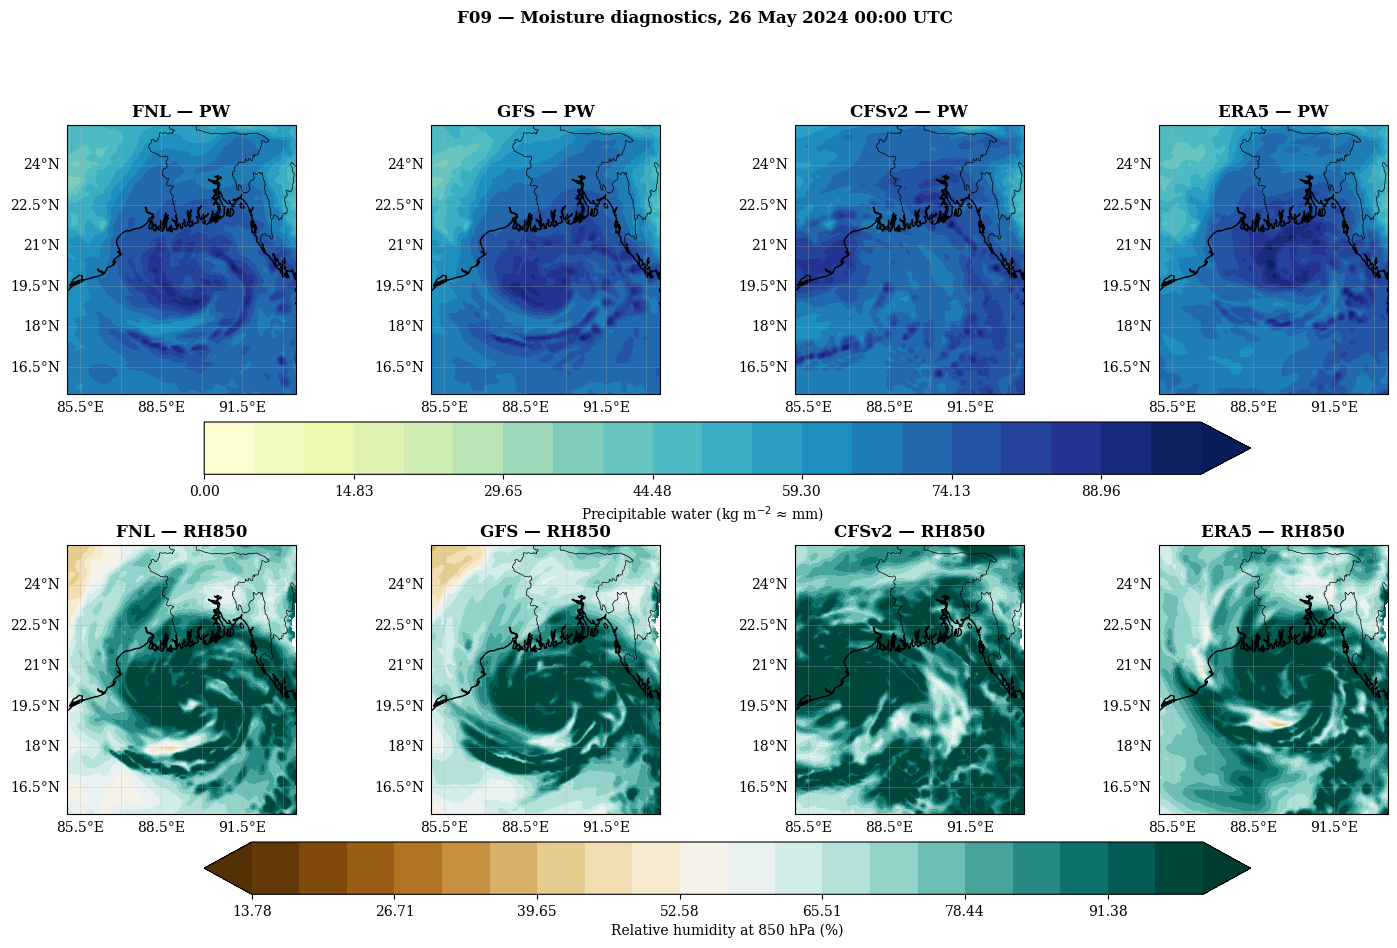

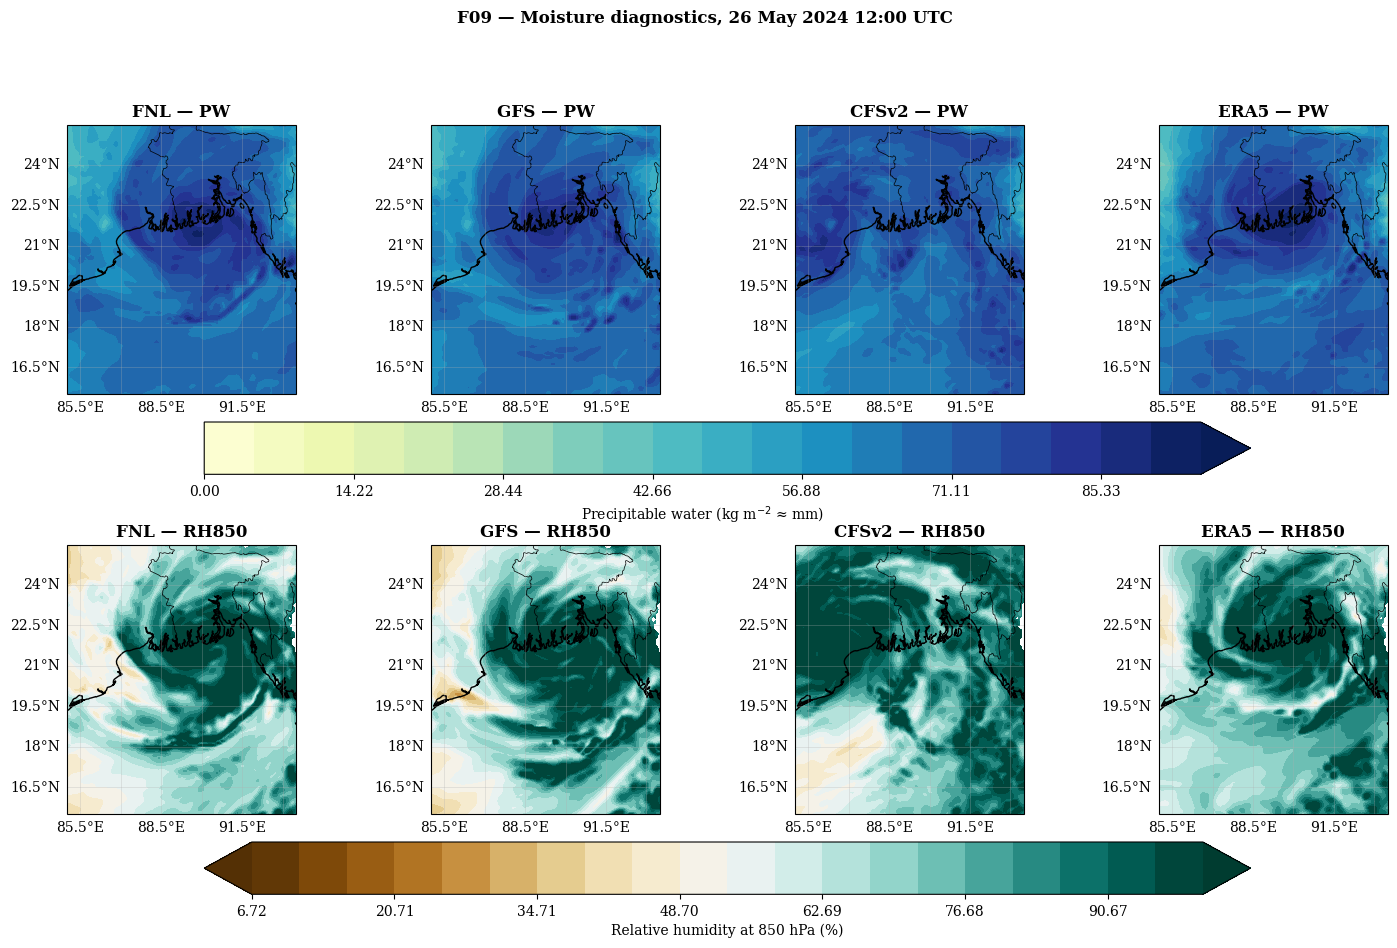

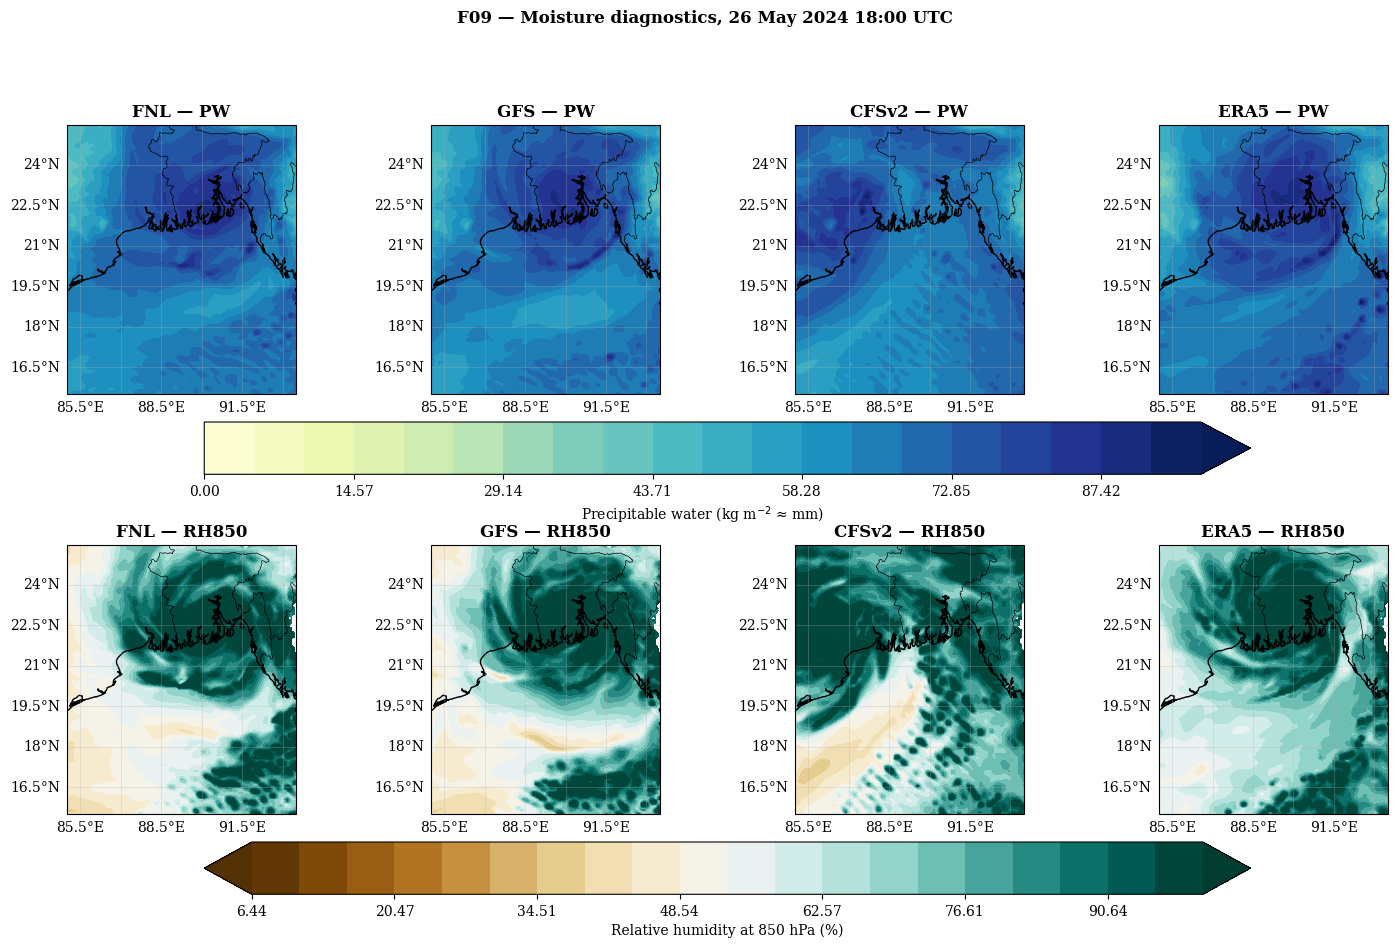

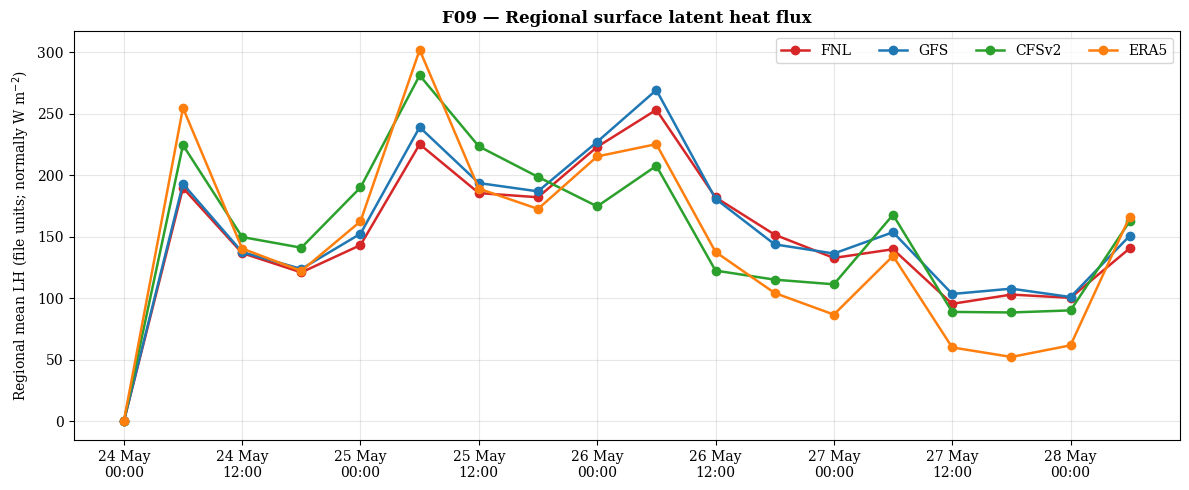

In [51]:
# CHUNK 46B: A12 precipitable water, RH850 and latent heat flux

def wrf_file_for_time(model_name, when):
    when = pd.to_datetime(when, utc=True)
    filename = (
        MODEL_DIRS[model_name] + "/wrfout_d02_" +
        when.strftime("%Y-%m-%d_%H_%M_%S")
    )
    return filename if os.path.exists(filename) else None


def get_pw_rh850(filename):
    nc = Dataset(filename)

    # WRF-Python PW is a full-column precipitable-water diagnostic.
    pw = getvar(nc, "pw")
    pressure = getvar(nc, "pressure")      # hPa
    rh = getvar(nc, "rh")                 # %
    rh850 = interplevel(rh, pressure, 850.0)

    lat, lon = latlon_coords(pw)

    out = {
        "pw": to_np(pw).astype(float),
        "rh850": to_np(rh850).astype(float),
        "lat": to_np(lat).astype(float),
        "lon": to_np(lon).astype(float),
    }
    nc.close()
    return out


moisture_extracts = {}

for time_text in DIAGNOSTIC_TIMES:
    when = pd.to_datetime(time_text, utc=True)
    available = {}

    for name in MODEL_NAMES:
        filename = wrf_file_for_time(name, when)
        if filename is None:
            print(name, ": no WRF file at", when, "for A12")
            continue

        try:
            available[name] = get_pw_rh850(filename)
        except Exception as error:
            print(name, ": A12 PW/RH850 failed at", when, ":", error)

    if len(available) == 0:
        continue

    moisture_extracts[when] = available

    # Common limits across all four experiments at this UTC time.
    pw_max = max(np.nanmax(v["pw"]) for v in available.values())
    rh_min = min(np.nanmin(v["rh850"]) for v in available.values())
    rh_max = max(np.nanmax(v["rh850"]) for v in available.values())

    pw_levels = np.linspace(0, max(pw_max, 1.0), 21)
    rh_levels = np.linspace(max(0, rh_min), min(100, max(rh_max, 1.0)), 21)

    fig, axes = plt.subplots(
        2, 4, figsize=(18, 10),   # <----------------------- change this to resize the figure (inches)
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    pw_handle = None
    rh_handle = None

    for i, name in enumerate(MODEL_NAMES):
        for row in [0, 1]:
            draw_base_map(
                axes[row, i],
                [DIAGNOSTIC_REGION["lon_min"], DIAGNOSTIC_REGION["lon_max"],
                 DIAGNOSTIC_REGION["lat_min"], DIAGNOSTIC_REGION["lat_max"]]
            )

        if name not in available:
            axes[0, i].set_title(name + " — missing")
            axes[1, i].set_title(name + " — missing")
            continue

        d = available[name]

        pw_handle = axes[0, i].contourf(
            d["lon"], d["lat"], d["pw"],
            levels=pw_levels, cmap="YlGnBu", extend="max",   # <----------------------- change this to use a different colour map
            transform=ccrs.PlateCarree()
        )
        rh_handle = axes[1, i].contourf(
            d["lon"], d["lat"], d["rh850"],
            levels=rh_levels, cmap="BrBG", extend="both",   # <----------------------- change this to use a different colour map
            transform=ccrs.PlateCarree()
        )

        axes[0, i].set_title(name + " — PW")
        axes[1, i].set_title(name + " — RH850")

        # Save each model/time gridded extract.
        xr.Dataset(
            data_vars={
                "precipitable_water": (("y", "x"), d["pw"]),
                "rh850": (("y", "x"), d["rh850"]),
                "latitude": (("y", "x"), d["lat"]),
                "longitude": (("y", "x"), d["lon"]),
            },
            attrs={
                "model": name,
                "time_utc": when.isoformat(),
                "note": "A12 model diagnostic; not independent validation."
            }
        ).to_netcdf(
            OUTDIRS["A12_moisture_flux"] + "/A12_" + name + "_" +
            when.strftime("%Y%m%d_%H%M") + "_PW_RH850.nc"
        )

    if pw_handle is not None:
        cb1 = fig.colorbar(
            pw_handle, ax=axes[0, :].tolist(),
            orientation="horizontal", pad=0.08, shrink=0.75
        )
        cb1.set_label("Precipitable water (kg m$^{-2}$ ≈ mm)")

    if rh_handle is not None:
        cb2 = fig.colorbar(
            rh_handle, ax=axes[1, :].tolist(),
            orientation="horizontal", pad=0.08, shrink=0.75
        )
        cb2.set_label("Relative humidity at 850 hPa (%)")

    fig.suptitle(
        "F09 — Moisture diagnostics, " +
        when.strftime("%d %b %Y %H:%M UTC"), y=0.995
    )
    plt.savefig(
        OUTDIRS["A12_moisture_flux"] + "/F09_PW_RH850_" +
        when.strftime("%Y%m%d_%H%M") + ".png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()


# ---------- Regional latent heat flux time series ----------
lh_rows = []

for name in MODEL_NAMES:
    for filename in list_wrfouts(MODEL_DIRS[name]):
        stamp = os.path.basename(filename).replace("wrfout_d02_", "")
        when = pd.to_datetime(stamp, format="%Y-%m-%d_%H_%M_%S", utc=True)

        ds = Dataset(filename)

        if "LH" not in ds.variables:
            ds.close()
            print(name, ": LH not found in", os.path.basename(filename))
            continue

        lh = np.asarray(ds.variables["LH"][0], dtype=float)
        lat = np.asarray(ds.variables["XLAT"][0], dtype=float)
        lon = np.asarray(ds.variables["XLONG"][0], dtype=float)

        units = getattr(ds.variables["LH"], "units", "")
        description = getattr(ds.variables["LH"], "description", "")
        ds.close()

        mask = (
            (lat >= DIAGNOSTIC_REGION["lat_min"]) &
            (lat <= DIAGNOSTIC_REGION["lat_max"]) &
            (lon >= DIAGNOSTIC_REGION["lon_min"]) &
            (lon <= DIAGNOSTIC_REGION["lon_max"])
        )

        lat_for_mean = np.where(mask, lat, np.nan)
        lh_for_mean = np.where(mask, lh, np.nan)
        mean_lh = area_weighted_mean(lh_for_mean, lat_for_mean)

        lh_rows.append({
            "model": name,
            "time_utc": when,
            "regional_mean_LH": mean_lh,
            "units_from_file": units,
            "description_from_file": description,
        })

lh_table = pd.DataFrame(lh_rows)
lh_table.to_csv(
    OUTDIRS["A12_moisture_flux"] + "/A12_regional_latent_heat_flux.csv",
    index=False
)

if len(lh_table) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))   # <----------------------- change this to resize the figure (inches)
    for name in MODEL_NAMES:
        s = lh_table[lh_table["model"] == name].sort_values("time_utc")
        ax.plot(
            s["time_utc"], s["regional_mean_LH"],
            color=COLORS[name], linewidth=1.8, marker="o", label=name
        )

    ax.set_ylabel("Regional mean LH (file units; normally W m$^{-2}$)")
    ax.set_title("F09 — Regional surface latent heat flux")
    ax.grid(alpha=0.3)
    ax.legend(ncol=4)
    format_time_axis(ax)
    plt.tight_layout()
    plt.savefig(
        OUTDIRS["A12_moisture_flux"] + "/F09_Regional_Latent_Heat_Flux.png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()


# A13: Environmental 850–200 hPa vector shear

For each model time, 850 and 200 hPa **earth-relative vector components** are area-averaged inside the same storm-relative annulus, then subtracted. The magnitude is therefore based on the vector difference, not a difference of scalar wind speeds. Coverage is saved and low-coverage samples are flagged.


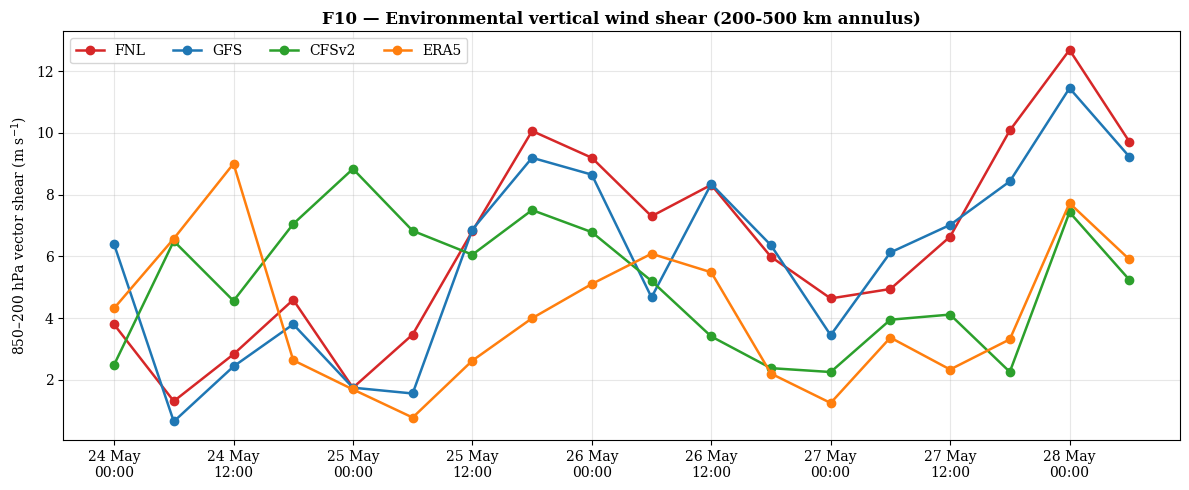

In [52]:
# CHUNK 46C: A13 environmental 850-200 hPa shear

def centre_at_time(model_name, when):
    when = pd.to_datetime(when, utc=True)
    table = centroid[model_name]
    match = table[table["time_utc"] == when]
    if len(match) == 0:
        return None
    row = match.iloc[0]
    return float(row["latitude"]), float(row["longitude"])


shear_rows = []

for name in MODEL_NAMES:
    for _, track_row in centroid[name].sort_values("time_utc").iterrows():
        when = pd.to_datetime(track_row["time_utc"], utc=True)
        filename = wrf_file_for_time(name, when)
        if filename is None:
            continue

        centre_lat = float(track_row["latitude"])
        centre_lon = float(track_row["longitude"])

        try:
            nc = Dataset(filename)
            pressure = getvar(nc, "pressure")               # hPa
            uvmet = getvar(nc, "uvmet", units="m s-1")    # [2,z,y,x], earth-relative
            u3d = uvmet[0]
            v3d = uvmet[1]

            u850 = to_np(interplevel(u3d, pressure, 850.0)).astype(float)
            v850 = to_np(interplevel(v3d, pressure, 850.0)).astype(float)
            u200 = to_np(interplevel(u3d, pressure, 200.0)).astype(float)
            v200 = to_np(interplevel(v3d, pressure, 200.0)).astype(float)

            lat, lon = latlon_coords(interplevel(u3d, pressure, 850.0))
            lat = to_np(lat).astype(float)
            lon = to_np(lon).astype(float)
            nc.close()

        except Exception as error:
            try:
                nc.close()
            except Exception:
                pass
            print(name, ": shear diagnostic failed at", when, ":", error)
            continue

        radius = distance_km(lat, lon, centre_lat, centre_lon)
        annulus = (
            (radius >= SHEAR_INNER_RADIUS_KM) &
            (radius <= SHEAR_OUTER_RADIUS_KM)
        )

        total_annulus = int(annulus.sum())
        valid = (
            annulus &
            np.isfinite(u850) & np.isfinite(v850) &
            np.isfinite(u200) & np.isfinite(v200)
        )
        valid_count = int(valid.sum())
        coverage = (
            valid_count / total_annulus if total_annulus > 0 else np.nan
        )

        if valid_count == 0:
            u850_mean = v850_mean = u200_mean = v200_mean = np.nan
        else:
            weights = np.cos(np.radians(lat[valid]))
            weights = weights / weights.sum()
            u850_mean = np.sum(weights * u850[valid])
            v850_mean = np.sum(weights * v850[valid])
            u200_mean = np.sum(weights * u200[valid])
            v200_mean = np.sum(weights * v200[valid])

        du = u200_mean - u850_mean
        dv = v200_mean - v850_mean
        shear_mag = np.sqrt(du**2 + dv**2)

        shear_rows.append({
            "model": name,
            "time_utc": when,
            "centre_latitude": centre_lat,
            "centre_longitude": centre_lon,
            "inner_radius_km": SHEAR_INNER_RADIUS_KM,
            "outer_radius_km": SHEAR_OUTER_RADIUS_KM,
            "coverage_fraction": coverage,
            "coverage_ok": bool(
                np.isfinite(coverage) and coverage >= SHEAR_MIN_COVERAGE
            ),
            "u850_mean_ms": u850_mean,
            "v850_mean_ms": v850_mean,
            "u200_mean_ms": u200_mean,
            "v200_mean_ms": v200_mean,
            "delta_u_ms": du,
            "delta_v_ms": dv,
            "shear_850_200_ms": shear_mag,
        })

shear_table = pd.DataFrame(shear_rows)
shear_table.to_csv(
    OUTDIRS["A13_shear"] + "/A13_850_200hPa_environmental_shear.csv",
    index=False
)

if len(shear_table) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))   # <----------------------- change this to resize the figure (inches)

    for name in MODEL_NAMES:
        s = shear_table[shear_table["model"] == name].sort_values("time_utc")
        good = s["coverage_ok"]
        ax.plot(
            s.loc[good, "time_utc"],
            s.loc[good, "shear_850_200_ms"],
            color=COLORS[name], linewidth=1.8, marker="o", label=name
        )
        # Low-coverage points remain visible as x markers rather than silently disappearing.
        bad = ~good
        if bad.any():
            ax.scatter(
                s.loc[bad, "time_utc"],
                s.loc[bad, "shear_850_200_ms"],
                marker="x", s=45, color=COLORS[name]
            )

    ax.set_ylabel("850–200 hPa vector shear (m s$^{-1}$)")
    ax.set_title(
        "F10 — Environmental vertical wind shear "
        f"({SHEAR_INNER_RADIUS_KM}-{SHEAR_OUTER_RADIUS_KM} km annulus)"
    )
    ax.grid(alpha=0.3)
    ax.legend(ncol=4)
    format_time_axis(ax)
    plt.tight_layout()
    plt.savefig(
        OUTDIRS["A13_shear"] + "/F10_Environmental_850_200hPa_Shear.png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()


# A14: Storm-centred vertical sections

At each selected UTC time, the section is a fixed east–west transect through the model storm centre with the same ±500 km half-length and the same 0–16 km vertical grid. Horizontal wind speed is shaded and model vertical velocity is contoured. The gridded section arrays are saved to NetCDF so figure styling can be changed without rereading the WRF files.


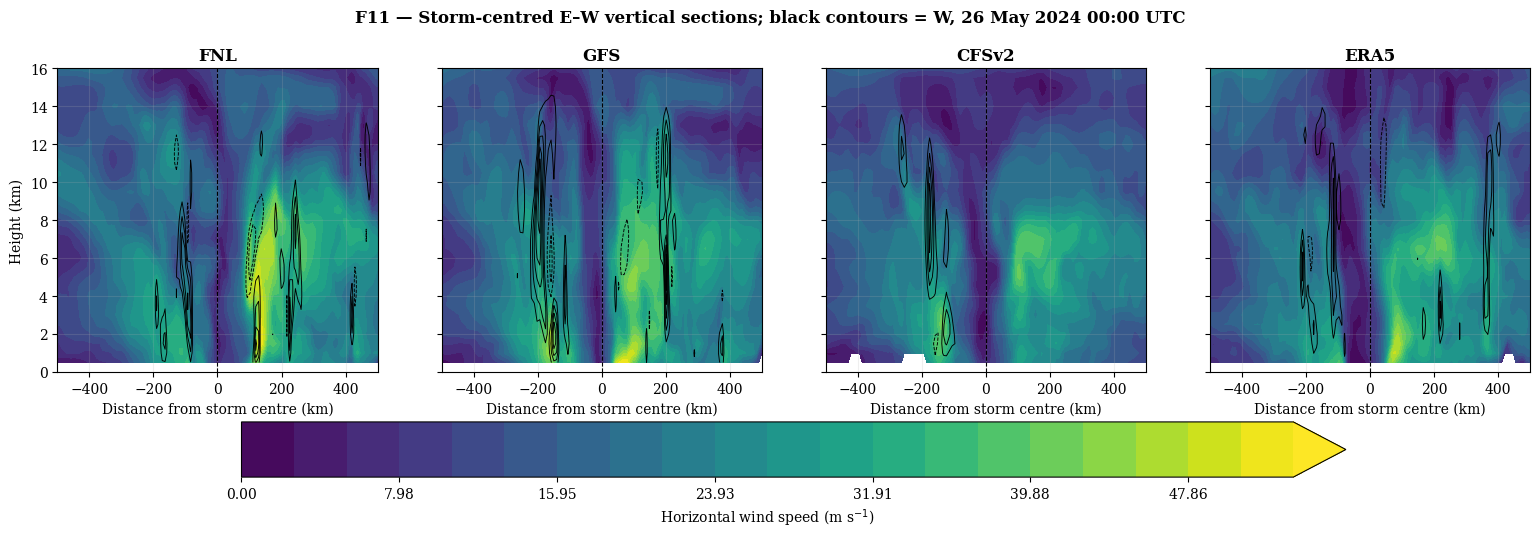

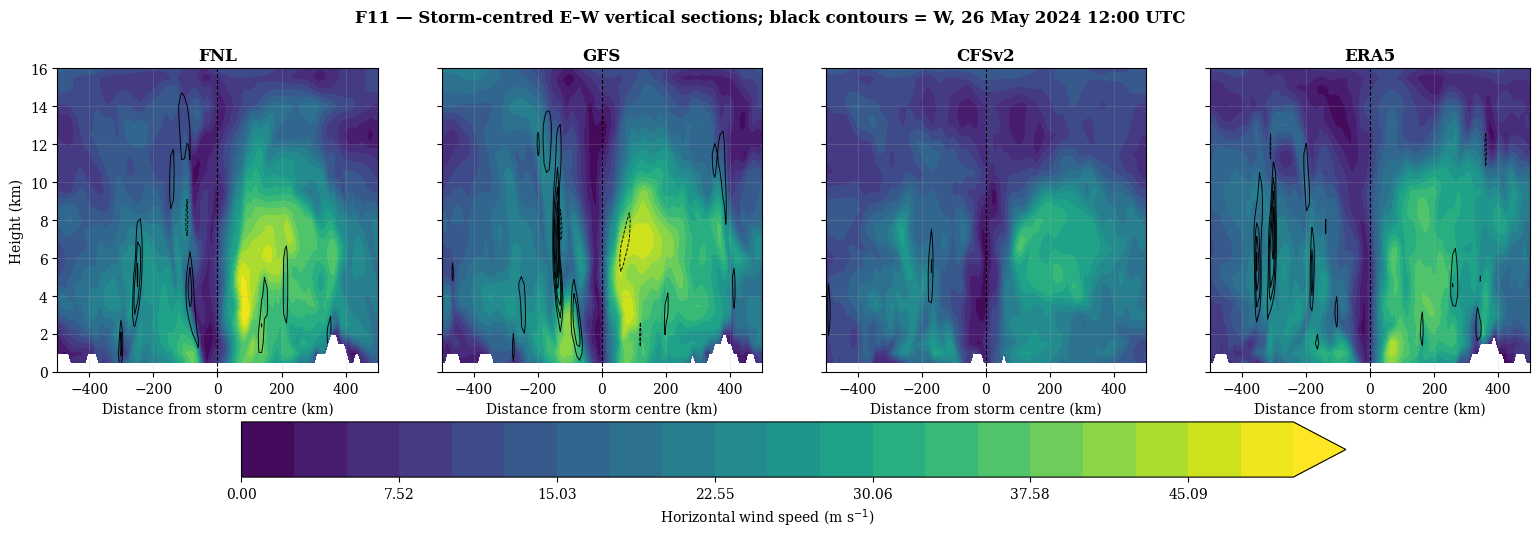

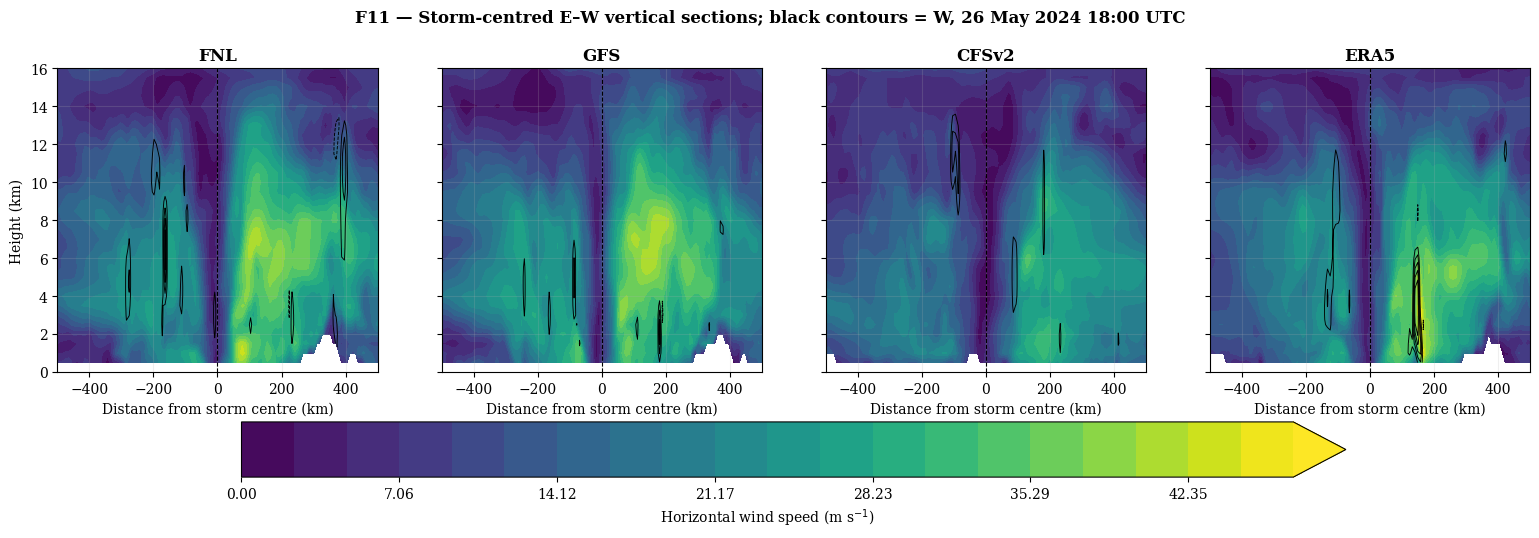

In [53]:
# CHUNK 46D: A14 storm-centred vertical sections

def cross_section_for_model(model_name, when):
    centre = centre_at_time(model_name, when)
    if centre is None:
        return None

    centre_lat, centre_lon = centre
    filename = wrf_file_for_time(model_name, when)
    if filename is None:
        return None

    # Convert the desired half-length in km to a longitude offset at the storm latitude.
    km_per_degree_lon = 111.32 * np.cos(np.radians(centre_lat))
    if km_per_degree_lon <= 0:
        return None

    dlon = CROSS_SECTION_HALF_LENGTH_KM / km_per_degree_lon

    start = CoordPair(lat=centre_lat, lon=centre_lon - dlon)
    end = CoordPair(lat=centre_lat, lon=centre_lon + dlon)

    levels_m = np.arange(
        0,
        CROSS_SECTION_TOP_KM * 1000 + CROSS_SECTION_DZ_KM * 1000,
        CROSS_SECTION_DZ_KM * 1000
    )

    nc = Dataset(filename)

    z = getvar(nc, "z", units="m")
    uvmet = getvar(nc, "uvmet", units="m s-1")
    horizontal_speed = np.sqrt(uvmet[0]**2 + uvmet[1]**2)
    w = getvar(nc, "wa", units="m s-1")

    wind_xs = vertcross(
        horizontal_speed, z, wrfin=nc,
        start_point=start, end_point=end,
        latlon=True, meta=True, levels=levels_m
    )
    w_xs = vertcross(
        w, z, wrfin=nc,
        start_point=start, end_point=end,
        latlon=True, meta=True, levels=levels_m
    )

    nc.close()

    wind_array = to_np(wind_xs).astype(float)
    w_array = to_np(w_xs).astype(float)

    # vertcross samples evenly along the chosen transect; use physical end-to-end length.
    x_km = np.linspace(
        -CROSS_SECTION_HALF_LENGTH_KM,
        CROSS_SECTION_HALF_LENGTH_KM,
        wind_array.shape[1]
    )
    z_km = levels_m / 1000.0

    return {
        "wind_ms": wind_array,
        "w_ms": w_array,
        "x_km": x_km,
        "z_km": z_km,
        "centre_lat": centre_lat,
        "centre_lon": centre_lon,
        "start_lon": centre_lon - dlon,
        "end_lon": centre_lon + dlon,
    }


for time_text in DIAGNOSTIC_TIMES:
    when = pd.to_datetime(time_text, utc=True)
    sections = {}

    for name in MODEL_NAMES:
        try:
            section = cross_section_for_model(name, when)
            if section is not None:
                sections[name] = section
        except Exception as error:
            print(name, ": A14 section failed at", when, ":", error)

    if len(sections) == 0:
        continue

    wind_max = max(
        np.nanmax(s["wind_ms"]) for s in sections.values()
        if np.isfinite(s["wind_ms"]).any()
    )
    wind_levels = np.linspace(0, max(wind_max, 1.0), 21)

    w_abs = max(
        np.nanmax(np.abs(s["w_ms"])) for s in sections.values()
        if np.isfinite(s["w_ms"]).any()
    )
    if w_abs == 0:
        w_abs = 0.1

    # Symmetric contour levels around zero, excluding exact zero for clearer ascent/descent contours.
    w_levels = np.linspace(-w_abs, w_abs, 13)   # <----------------------- change 13 to set the number of W contours
    w_levels = w_levels[np.abs(w_levels) > 1e-12]

    fig, axes = plt.subplots(1, 4, figsize=(19, 5.4), sharey=True)   # <----------------------- change this to resize the figure (inches)
    wind_handle = None

    for i, name in enumerate(MODEL_NAMES):
        ax = axes[i]

        if name not in sections:
            ax.set_title(name + " — missing")
            ax.set_xlim(
                -CROSS_SECTION_HALF_LENGTH_KM,
                CROSS_SECTION_HALF_LENGTH_KM
            )
            ax.set_ylim(0, CROSS_SECTION_TOP_KM)
            continue

        s = sections[name]

        wind_handle = ax.contourf(
            s["x_km"], s["z_km"], s["wind_ms"],
            levels=wind_levels, cmap="viridis", extend="max"   # <----------------------- change this to use a different colour map
        )

        ax.contour(
            s["x_km"], s["z_km"], s["w_ms"],
            levels=w_levels, colors="black", linewidths=0.65
        )

        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(name)
        ax.set_xlabel("Distance from storm centre (km)")
        ax.grid(alpha=0.2)

        xr.Dataset(
            data_vars={
                "horizontal_wind_speed": (
                    ("height_km", "distance_km"), s["wind_ms"]
                ),
                "vertical_velocity": (
                    ("height_km", "distance_km"), s["w_ms"]
                ),
            },
            coords={
                "height_km": s["z_km"],
                "distance_km": s["x_km"],
            },
            attrs={
                "model": name,
                "time_utc": when.isoformat(),
                "centre_latitude": s["centre_lat"],
                "centre_longitude": s["centre_lon"],
                "transect_orientation": "east-west through storm centre",
                "half_length_km": CROSS_SECTION_HALF_LENGTH_KM,
            }
        ).to_netcdf(
            OUTDIRS["A14_vertical_sections"] + "/A14_" + name + "_" +
            when.strftime("%Y%m%d_%H%M") + "_vertical_section.nc"
        )

    axes[0].set_ylabel("Height (km)")
    axes[0].set_ylim(0, CROSS_SECTION_TOP_KM)

    if wind_handle is not None:
        cbar = fig.colorbar(
            wind_handle, ax=axes.tolist(),
            orientation="horizontal", pad=0.12, shrink=0.75
        )
        cbar.set_label("Horizontal wind speed (m s$^{-1}$)")

    fig.suptitle(
        "F11 — Storm-centred E–W vertical sections; black contours = W, " +
        when.strftime("%d %b %Y %H:%M UTC"), y=0.99
    )
    plt.savefig(
        OUTDIRS["A14_vertical_sections"] + "/F11_Vertical_Section_" +
        when.strftime("%Y%m%d_%H%M") + ".png",
        dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
    )
    plt.show()


# A15: Consolidated validation summary
The headline wind/pressure metrics in this summary are the **time-weighted full-time scores**. Ordinary unweighted all-match scores are retained in separate columns, and A16 shows whether conclusions change on the regular 6-hour subset.

In [54]:
# CHUNK 47: A15 consolidated performance table
summary_rows = []

for name in MODEL_NAMES:

    t = track_table[track_table["model"] == name].iloc[0]
    w = wind_table[wind_table["model"] == name].iloc[0]
    pr = pressure_table[pressure_table["model"] == name].iloc[0]
    sp = translation_score_table[
        translation_score_table["model"] == name
    ].iloc[0]

    pk_w = peak_table[
        (peak_table["model"] == name) &
        (peak_table["variable"] == "Maximum wind (kt)")
    ].iloc[0]
    pk_p = peak_table[
        (peak_table["model"] == name) &
        (peak_table["variable"] == "Minimum pressure (hPa)")
    ].iloc[0]
    pdi = pdi_table[pdi_table["source"] == name].iloc[0]

    landfall_time_error = np.nan
    landfall_position_error = np.nan
    if imd_landfall is not None:
        row = landfall_table[landfall_table["source"] == name].iloc[0]
        landfall_time_error = row["time_error_h"]
        landfall_position_error = row["position_error_km"]

    rain_row = (
        rainfall_score_table[rainfall_score_table["model"] == name]
        if "rainfall_score_table" in dir() and len(rainfall_score_table) > 0
        else pd.DataFrame()
    )

    ccmp_row = (
        ccmp_score_summary[ccmp_score_summary["model"] == name]
        if "ccmp_score_summary" in dir() and len(ccmp_score_summary) > 0
        else pd.DataFrame()
    )

    shear_row = (
        shear_table[shear_table["model"] == name]
        if "shear_table" in dir() and len(shear_table) > 0
        else pd.DataFrame()
    )

    summary_rows.append({
        "model": name,
        "n_shared_track_times": t["n_matched"],
        "n_shared_intensity_times": int(w["n"]),
        "n_carried_forward_in_sample": t["n_carried_forward_in_sample"],

        "mean_position_error_km": t["mean_error_km"],
        "track_rmse_km": t["track_rmse_km"],

        "translation_speed_bias_kmh": sp["bias_kmh"],
        "translation_speed_rmse_kmh": sp["rmse_kmh"],

        # Headline full-time scores are time-weighted because the 30-point
        # IMD timeline is irregularly sampled. Ordinary paired-observation
        # scores are retained explicitly for transparency.
        "wind_bias_kt": w["time_weighted_bias_kt"],
        "wind_rmse_kt": w["time_weighted_rmse_kt"],
        "wind_corr": w["time_weighted_correlation"],
        "wind_bias_kt_unweighted_all_matches": w["mean_bias_kt"],
        "wind_rmse_kt_unweighted_all_matches": w["rmse_kt"],
        "wind_corr_unweighted_all_matches": w["correlation"],

        "pressure_bias_hpa": pr["time_weighted_bias_hpa"],
        "pressure_rmse_hpa": pr["time_weighted_rmse_hpa"],
        "pressure_corr": pr["time_weighted_correlation"],
        "pressure_bias_hpa_unweighted_all_matches": pr["mean_bias_hpa"],
        "pressure_rmse_hpa_unweighted_all_matches": pr["rmse_hpa"],
        "pressure_corr_unweighted_all_matches": pr["correlation"],

        "peak_wind_error_kt": pk_w["value_error"],
        "peak_wind_timing_error_h": pk_w["timing_error_h_nearest_tie"],
        "min_pressure_error_hpa": pk_p["value_error"],
        "min_pressure_timing_error_h": pk_p["timing_error_h_nearest_tie"],

        "landfall_time_error_h": landfall_time_error,
        "landfall_position_error_km": landfall_position_error,

        "pdi_model_over_imd": pdi["model_over_imd"],

        "rainfall_bias_mm": (
            rain_row["bias"].iloc[0] if len(rain_row) > 0 else np.nan
        ),
        "rainfall_rmse_mm": (
            rain_row["rmse"].iloc[0] if len(rain_row) > 0 else np.nan
        ),
        "rainfall_spatial_corr": (
            rain_row["corr"].iloc[0] if len(rain_row) > 0 else np.nan
        ),

        "ccmp_speed_bias_ms_mean_selected_times": (
            ccmp_row["speed_bias_ms"].iloc[0] if len(ccmp_row) > 0 else np.nan
        ),
        "ccmp_speed_rmse_ms_mean_selected_times": (
            ccmp_row["speed_rmse_ms"].iloc[0] if len(ccmp_row) > 0 else np.nan
        ),
        "ccmp_speed_spatial_corr_mean_selected_times": (
            ccmp_row["speed_spatial_corr"].iloc[0] if len(ccmp_row) > 0 else np.nan
        ),
        "ccmp_vector_rmse_ms_mean_selected_times": (
            ccmp_row["vector_rmse_ms"].iloc[0] if len(ccmp_row) > 0 else np.nan
        ),

        # A13 is a diagnostic, not a validation score.
        "mean_environmental_shear_850_200_ms": (
            shear_row.loc[
                shear_row["coverage_ok"], "shear_850_200_ms"
            ].mean()
            if len(shear_row) > 0 else np.nan
        ),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    OUTDIRS["A15_summary"] + "/T07_Consolidated_Performance_and_Diagnostics.csv",
    index=False
)
print(summary.round(2).T.to_string(header=False))


model                                           FNL     GFS   CFSv2    ERA5
n_shared_track_times                             18      18      18      18
n_shared_intensity_times                         30      30      30      30
n_carried_forward_in_sample                       3       3       0       3
mean_position_error_km                       102.13   99.46  261.71   95.79
track_rmse_km                                123.46  110.86  273.26   109.2
translation_speed_bias_kmh                    -1.24   -0.99     0.3   -0.93
translation_speed_rmse_kmh                     7.54     7.6    5.72    7.61
wind_bias_kt                                  13.56   13.34    6.63    7.19
wind_rmse_kt                                  18.57   18.09   17.97   11.86
wind_corr                                      0.78    0.79    0.09     0.8
wind_bias_kt_unweighted_all_matches           13.04   13.01    4.74     6.2
wind_rmse_kt_unweighted_all_matches           18.62   18.22   17.41   11.39
wind_corr_un

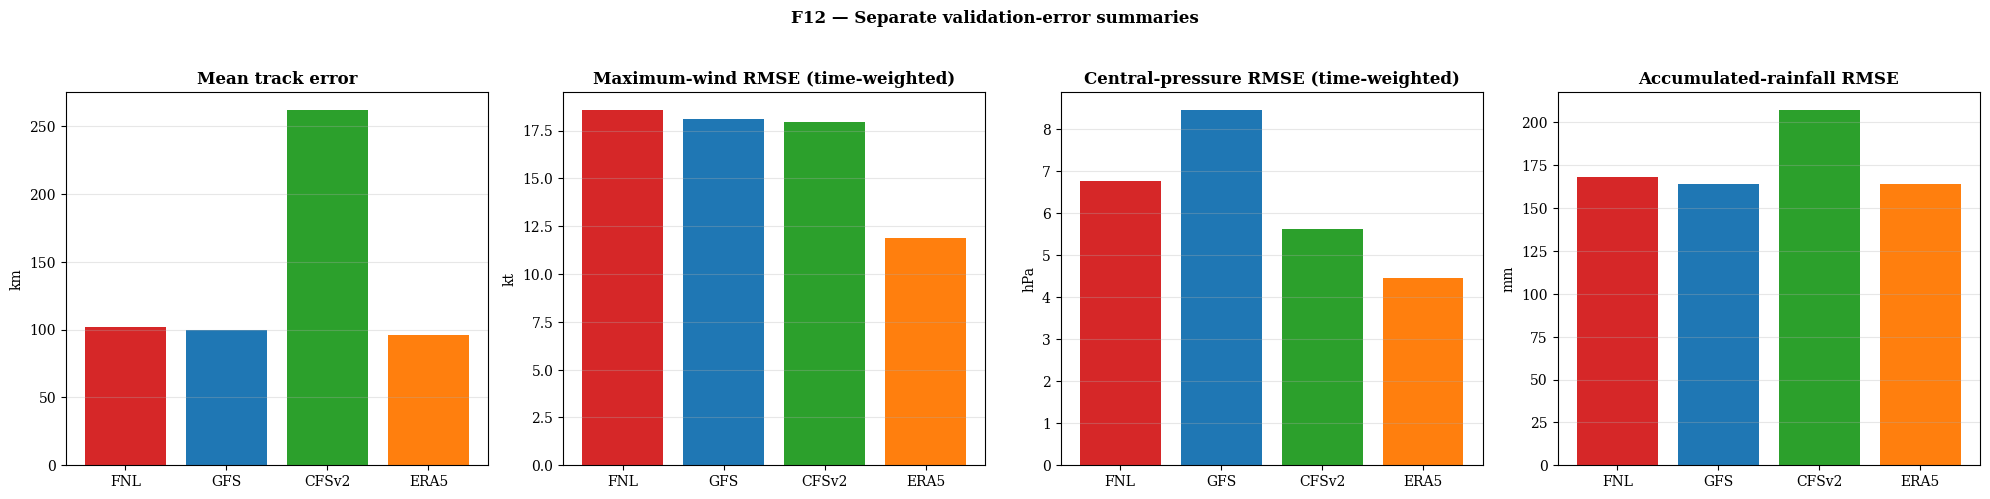

In [55]:
# CHUNK 48: F12 separate-panel validation-error bars
# Different physical units remain on separate axes.

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))   # <----------------------- change this to resize the figure (inches)

panels = [   # <----------------------- change these to choose which summary metrics are plotted
    ("mean_position_error_km", "Mean track error", "km"),
    ("wind_rmse_kt", "Maximum-wind RMSE (time-weighted)", "kt"),
    ("pressure_rmse_hpa", "Central-pressure RMSE (time-weighted)", "hPa"),
    ("rainfall_rmse_mm", "Accumulated-rainfall RMSE", "mm"),
]

for i, (column, title, unit) in enumerate(panels):
    values = summary[column]
    axes[i].bar(
        summary["model"], values,
        color=[COLORS[name] for name in summary["model"]]
    )
    axes[i].set_title(title)
    axes[i].set_ylabel(unit)
    axes[i].grid(axis="y", alpha=0.3)

fig.suptitle("F12 — Separate validation-error summaries", y=1.03)
plt.tight_layout()
plt.savefig(
    OUTDIRS["A15_summary"] + "/F12_Separate_Validation_Error_Bars.png",
    dpi=300, bbox_inches="tight"   # <----------------------- change this to set the saved-figure resolution
)
plt.show()


# A16: Temporal-sampling sensitivity
This is an **additional robustness analysis**, not a replacement for the original checklist. It asks whether the wind/pressure conclusions depend strongly on using every exact IMD match instead of the regular 6-hour subset.

Three score conventions are compared:
1. **All exact matches - unweighted:** every paired IMD observation receives equal weight.
2. **All exact matches - time-weighted:** irregular intervals are weighted by their temporal support, so densely sampled periods do not automatically dominate.
3. **Regular 6-hour subset:** the same full-time intensity extraction is sampled only at timestamps common to the frozen 6-hour track support. The track algorithm itself is not reused for wind/pressure values.

PDI is also recalculated on the full exact-match support and the regular 6-hour subset to show sensitivity to temporal resolution.

Full exact-match intensity timestamps: 30
Regular 6-hour sensitivity timestamps: 18
All regular-subset gaps are 6 h: True


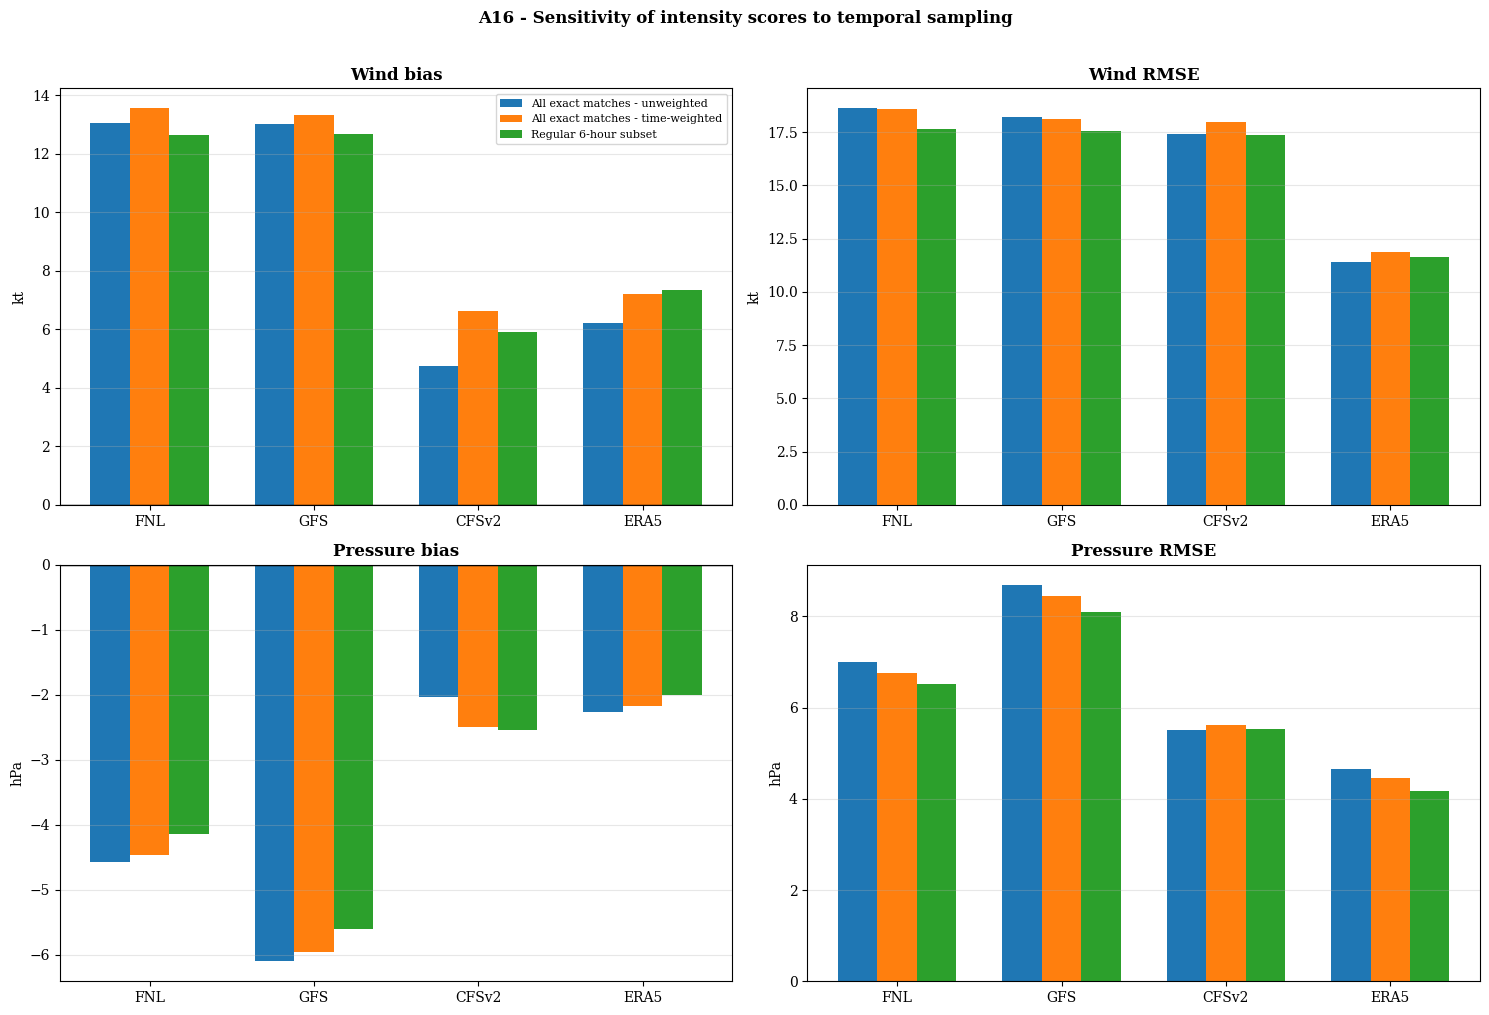


A16 wind/pressure sampling sensitivity:
model variable unit                   sampling_scheme  n   bias    mae   rmse  correlation
  FNL     Wind   kt    All exact matches - unweighted 30 13.040 13.905 18.623        0.789
  FNL     Wind   kt All exact matches - time-weighted 30 13.555 14.357 18.571        0.778
  FNL     Wind   kt             Regular 6-hour subset 18 12.650 13.549 17.631        0.814
  FNL Pressure  hPa    All exact matches - unweighted 30 -4.579  5.569  6.993        0.883
  FNL Pressure  hPa All exact matches - time-weighted 30 -4.461  5.385  6.757        0.881
  FNL Pressure  hPa             Regular 6-hour subset 18 -4.149  5.039  6.508        0.889
  GFS     Wind   kt    All exact matches - unweighted 30 13.013 13.839 18.224        0.798
  GFS     Wind   kt All exact matches - time-weighted 30 13.336 14.094 18.093        0.790
  GFS     Wind   kt             Regular 6-hour subset 18 12.676 13.685 17.530        0.814
  GFS Pressure  hPa    All exact matches - unweig

In [56]:
# CHUNK 48B: A16 temporal-sampling sensitivity
# ------------------------------------------------------------
# 1. FIND THE REGULAR 6-HOUR SUPPORT COMMON TO EVERYTHING
# ------------------------------------------------------------
regular_6h_times = set(common_intensity_times)

for name in MODEL_NAMES:
    regular_6h_times = regular_6h_times & set(
        pd.DatetimeIndex(pairs[name]["time_utc"])
    )

regular_6h_times = pd.DatetimeIndex(sorted(regular_6h_times))

if len(regular_6h_times) >= 2:
    regular_gaps_h = (
        np.diff(regular_6h_times.asi8.astype(float) / 1.0e9) / 3600.0
    )
    regular_support_is_6h = bool(np.allclose(regular_gaps_h, 6.0))
else:
    regular_gaps_h = np.array([])
    regular_support_is_6h = False

print("Full exact-match intensity timestamps:", len(common_intensity_times))
print("Regular 6-hour sensitivity timestamps:", len(regular_6h_times))
print("All regular-subset gaps are 6 h:", regular_support_is_6h)

support_rows = []
previous_time = None

for when in common_intensity_times:
    elapsed_h = np.nan
    if previous_time is not None:
        elapsed_h = (when - previous_time) / pd.Timedelta(hours=1)

    support_rows.append({
        "time_utc": when,
        "full_exact_match_support": True,
        "regular_6h_subset": when in set(regular_6h_times),
        "elapsed_from_previous_full_match_h": elapsed_h,
    })
    previous_time = when

sampling_support_table = pd.DataFrame(support_rows)
sampling_support_table.to_csv(
    OUTDIRS["A16_sampling_sensitivity"] + "/A16_Timestamp_Support.csv",
    index=False
)

# ------------------------------------------------------------
# 2. WIND AND PRESSURE: THREE SCORE CONVENTIONS
# ------------------------------------------------------------
sampling_rows = []

variable_settings = [
    ("Wind", "wind_model", "wind_imd", "kt"),
    ("Pressure", "pres_model", "pres_imd", "hPa"),
]

for name in MODEL_NAMES:
    full = intensity_pairs[name].copy().sort_values("time_utc").reset_index(drop=True)
    six = full[full["time_utc"].isin(regular_6h_times)].copy().reset_index(drop=True)

    for variable_name, model_column, imd_column, unit in variable_settings:
        full_unweighted = error_stats(
            full[model_column],
            full[imd_column]
        )

        full_weighted = time_weighted_error_stats(
            full["time_utc"],
            full[model_column],
            full[imd_column]
        )

        six_unweighted = error_stats(
            six[model_column],
            six[imd_column]
        )

        for scheme, stats_result in [
            ("All exact matches - unweighted", full_unweighted),
            ("All exact matches - time-weighted", full_weighted),
            ("Regular 6-hour subset", six_unweighted),
        ]:
            sampling_rows.append({
                "model": name,
                "variable": variable_name,
                "unit": unit,
                "sampling_scheme": scheme,
                "n": stats_result["n"],
                "bias": stats_result["bias"],
                "mae": stats_result["mae"],
                "rmse": stats_result["rmse"],
                "correlation": stats_result["corr"],
            })

sampling_sensitivity_table = pd.DataFrame(sampling_rows)
sampling_sensitivity_table.to_csv(
    OUTDIRS["A16_sampling_sensitivity"] + "/A16_Wind_Pressure_Sampling_Sensitivity.csv",
    index=False
)

# ------------------------------------------------------------
# 3. PDI FULL SUPPORT VS REGULAR 6-HOUR SUPPORT
# ------------------------------------------------------------
pdi_sensitivity_rows = []

for source in ["IMD"] + MODEL_NAMES:
    if source == "IMD":
        full_table = intensity_pairs[MODEL_NAMES[0]][
            ["time_utc", "wind_imd"]
        ].copy()
        full_table.columns = ["time_utc", "wind_kt"]
    else:
        full_table = intensity_pairs[source][
            ["time_utc", "wind_model"]
        ].copy()
        full_table.columns = ["time_utc", "wind_kt"]

    full_table = full_table.sort_values("time_utc").reset_index(drop=True)
    six_table = full_table[
        full_table["time_utc"].isin(regular_6h_times)
    ].copy().reset_index(drop=True)

    pdi_full, n_full_above, full_intervals, full_hours = time_weighted_pdi(
        full_table["time_utc"],
        full_table["wind_kt"].to_numpy(),
        PDI_MIN_WIND_KT,
    )

    pdi_six, n_six_above, six_intervals, six_hours = time_weighted_pdi(
        six_table["time_utc"],
        six_table["wind_kt"].to_numpy(),
        PDI_MIN_WIND_KT,
    )

    if np.isfinite(pdi_full) and pdi_full != 0:
        six_vs_full_pct = 100.0 * (pdi_six - pdi_full) / pdi_full
    else:
        six_vs_full_pct = np.nan

    pdi_sensitivity_rows.append({
        "source": source,
        "full_n_timestamps": len(full_table),
        "full_valid_intervals": full_intervals,
        "full_integrated_hours": full_hours,
        "full_pdi_m3_s_minus2": pdi_full,
        "six_hour_n_timestamps": len(six_table),
        "six_hour_valid_intervals": six_intervals,
        "six_hour_integrated_hours": six_hours,
        "six_hour_pdi_m3_s_minus2": pdi_six,
        "six_hour_minus_full_pct": six_vs_full_pct,
    })

pdi_sampling_sensitivity_table = pd.DataFrame(pdi_sensitivity_rows)
pdi_sampling_sensitivity_table.to_csv(
    OUTDIRS["A16_sampling_sensitivity"] + "/A16_PDI_Full_vs_6hour_Sensitivity.csv",
    index=False
)

# ------------------------------------------------------------
# 4. COMPACT ROBUSTNESS FIGURE: BIAS AND RMSE
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))   # <----------------------- change this to resize the figure (inches)

schemes = [
    "All exact matches - unweighted",
    "All exact matches - time-weighted",
    "Regular 6-hour subset",
]

x = np.arange(len(MODEL_NAMES))
bar_width = 0.24

def draw_sampling_bars(ax, variable_name, metric, ylabel, title):
    for j, scheme in enumerate(schemes):
        values = []
        for name in MODEL_NAMES:
            row = sampling_sensitivity_table[
                (sampling_sensitivity_table["model"] == name)
                & (sampling_sensitivity_table["variable"] == variable_name)
                & (sampling_sensitivity_table["sampling_scheme"] == scheme)
            ]
            values.append(row[metric].iloc[0] if len(row) > 0 else np.nan)

        ax.bar(
            x + (j - 1) * bar_width,
            values,
            width=bar_width,
            label=scheme,
        )

    if metric == "bias":
        ax.axhline(0, color="black", linewidth=1)

    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_NAMES)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)


draw_sampling_bars(axes[0, 0], "Wind", "bias", "kt", "Wind bias")
draw_sampling_bars(axes[0, 1], "Wind", "rmse", "kt", "Wind RMSE")
draw_sampling_bars(axes[1, 0], "Pressure", "bias", "hPa", "Pressure bias")
draw_sampling_bars(axes[1, 1], "Pressure", "rmse", "hPa", "Pressure RMSE")

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    "A16 - Sensitivity of intensity scores to temporal sampling",
    y=1.01,
    fontweight="bold",
)

plt.tight_layout()
plt.savefig(
    OUTDIRS["A16_sampling_sensitivity"] + "/A16_Sampling_Sensitivity_Bias_RMSE.png",
    dpi=300,   # <----------------------- change this to set the saved-figure resolution
    bbox_inches="tight",
)
plt.show()

print("\nA16 wind/pressure sampling sensitivity:")
show(sampling_sensitivity_table, 3)

print("\nA16 PDI sampling sensitivity:")
show(pdi_sampling_sensitivity_table, 3)

In [57]:
# CHUNK 49: Final validation/reproducibility checks
checks = []

def add_check(check, ok, detail):
    checks.append({
        "check": check,
        "result": "PASS" if ok else "WARN",
        "detail": detail,
    })


# ------------------------------------------------------------
# TRACK SUPPORT: frozen 6-hourly method
# ------------------------------------------------------------

track_counts = [
    len(pairs[name])
    for name in MODEL_NAMES
]

add_check(
    "Same number of shared 6-hourly track timestamps for all models",
    len(set(track_counts)) == 1,
    "counts = " + str(track_counts)
)


# ------------------------------------------------------------
# INTENSITY SUPPORT: all exact IMD matches
# ------------------------------------------------------------

intensity_counts = [
    len(intensity_pairs[name])
    for name in MODEL_NAMES
]

add_check(
    "Same number of full-time intensity timestamps for all models",
    len(set(intensity_counts)) == 1,
    "counts = " + str(intensity_counts)
)

add_check(
    "Every supplied IMD intensity timestamp has an exact WRF match in all four runs",
    len(common_intensity_times) == len(imd),
    "used "
    + str(len(common_intensity_times))
    + " of "
    + str(len(imd))
    + " IMD timestamps"
)


# ------------------------------------------------------------
# MODEL-SPECIFIC CHECKS
# ------------------------------------------------------------

for name in MODEL_NAMES:

    p_track = pairs[name]
    p_intensity = intensity_pairs[name]

    missing_wind = int(
        p_intensity["wind_imd"].isna().sum()
        + p_intensity["wind_model"].isna().sum()
    )

    missing_pres = int(
        p_intensity["pres_imd"].isna().sum()
        + p_intensity["pres_model"].isna().sum()
    )

    add_check(
        name + ": no missing full-time matched wind/pressure values",
        missing_wind == 0 and missing_pres == 0,
        "missing wind = "
        + str(missing_wind)
        + ", missing pressure = "
        + str(missing_pres)
    )

    duplicates_track = int(
        smooth[name]["time_utc"].duplicated().sum()
    )

    add_check(
        name + ": no duplicate 6-hourly model-track times",
        duplicates_track == 0,
        str(duplicates_track)
        + " duplicates"
    )

    duplicates_intensity = int(
        p_intensity["time_utc"].duplicated().sum()
    )

    add_check(
        name + ": no duplicate full-time intensity times",
        duplicates_intensity == 0,
        str(duplicates_intensity)
        + " duplicates"
    )

    wind_ok = p_intensity[
        "wind_model"
    ].between(
        0,
        200   # <----------------------- change this plausible wind range (kt)
    ).all()

    pres_ok = p_intensity[
        "pres_model"
    ].between(
        850,
        1030   # <----------------------- change this plausible pressure range (hPa)
    ).all()

    add_check(
        name + ": full-time model wind/pressure broadly plausible",
        wind_ok and pres_ok,
        "wind "
        + str(round(p_intensity["wind_model"].min(), 1))
        + "-"
        + str(round(p_intensity["wind_model"].max(), 1))
        + " kt; pressure "
        + str(round(p_intensity["pres_model"].min(), 1))
        + "-"
        + str(round(p_intensity["pres_model"].max(), 1))
        + " hPa"
    )

    n_rejected = int(
        (
            diag[name]["status"]
            == "REJECTED"
        ).sum()
    )

    add_check(
        name + ": 6-hourly tracking candidates requiring review",
        n_rejected == 0,
        str(n_rejected)
        + " rejected/carry-forward timestamps; see A02"
    )


# ------------------------------------------------------------
# LANDFALL
# ------------------------------------------------------------

if imd_landfall is not None:

    for name in MODEL_NAMES:

        add_check(
            name + ": landfall crossing found",
            model_landfalls[name] is not None,
            "IMD source: "
            + imd_landfall_source
        )


# ------------------------------------------------------------
# PLANNED ANALYSES A01-A16
# ------------------------------------------------------------

add_check(
    "A01 domain/configuration output created",
    "domain_table" in dir()
    and len(domain_table) > 0,
    "A01_configuration"
)

add_check(
    "A04 translation speed created",
    "translation_score_table" in dir()
    and len(translation_score_table) == 4,
    "A04_translation_speed"
)

add_check(
    "A05/A06 full-time intensity coverage table created",
    "intensity_coverage_table" in dir()
    and len(intensity_coverage_table) == 4,
    "A05_wind_validation / A06_pressure_validation"
)

add_check(
    "A07 intensity-change rates created",
    "intensity_rate_table" in dir()
    and len(intensity_rate_table) > 0,
    "A07_intensity_change"
)

add_check(
    "A10 IMERG rainfall validation ran",
    "rainfall_score_table" in dir()
    and len(rainfall_score_table) > 0,
    "A10_rainfall"
)

add_check(
    "A11 CCMP wind validation ran",
    "ccmp_score_table" in dir()
    and len(ccmp_score_table) > 0,
    "A11_ccmp_wind"
)

add_check(
    "A12 PW/RH850 diagnostics ran",
    "moisture_extracts" in dir()
    and len(moisture_extracts) > 0,
    "A12_moisture_flux"
)

add_check(
    "A12 latent-heat-flux diagnostic ran",
    "lh_table" in dir()
    and len(lh_table) > 0,
    "A12_moisture_flux"
)

add_check(
    "A13 environmental shear diagnostic ran",
    "shear_table" in dir()
    and len(shear_table) > 0,
    "A13_shear"
)



add_check(
    "A16 sampling-sensitivity analysis ran",
    "sampling_sensitivity_table" in dir()
    and len(sampling_sensitivity_table) > 0
    and "pdi_sampling_sensitivity_table" in dir()
    and len(pdi_sampling_sensitivity_table) > 0,
    "A16_sampling_sensitivity"
)

add_check(
    "A16 regular-subset timestamps are exactly 6 hours apart",
    "regular_support_is_6h" in dir() and regular_support_is_6h,
    "regular subset N = "
    + str(len(regular_6h_times))
    + "; gaps = "
    + str(list(np.round(regular_gaps_h, 3)))
)

# A14: count NetCDF section outputs actually created.
section_files = glob.glob(
    OUTDIRS["A14_vertical_sections"]
    + "/A14_*_vertical_section.nc"
)

add_check(
    "A14 vertical sections ran",
    len(section_files) > 0,
    str(len(section_files))
    + " gridded section files created"
)


checks_table = pd.DataFrame(
    checks
)

checks_table.to_csv(
    OUTDIRS["A15_summary"]
    + "/A15_Final_Checks.csv",
    index=False
)


print(
    checks_table[
        "result"
    ].value_counts().to_string()
)

print()

print(
    checks_table.to_string(
        index=False
    )
)


# Final general-folder mirrors for quick coding/navigation.
mirror_counts = (
    sync_general_output_folders()
)

print()

print(
    "General output mirrors updated:",
    mirror_counts
)


result
PASS    36
WARN     3

                                                                         check result                                                                                                                                                                                                                                                                                                                          detail
                Same number of shared 6-hourly track timestamps for all models   PASS                                                                                                                                                                                                                                                                                                       counts = [18, 18, 18, 18]
                  Same number of full-time intensity timestamps for all models   PASS                                                                         

# Limitations

- **Tracking remains intentionally frozen.** The existing centroid/smoothing/carry-forward behaviour is preserved because the track method was explicitly not to be redesigned in this pass. Rejected candidates are flagged and saved for sensitivity review rather than silently hidden. Any manuscript claim must state whether carried-forward points were included in the main sample.
- **The 6-hour gap check is exact.** The frozen extraction stops if two consecutive 6-hourly files are not exactly 6 h apart, so even a one-second timestamp discrepancy halts the run. This is kept to preserve the frozen method.
- **Track and intensity use different temporal supports by design.** Track, translation speed and track-dependent landfall analysis remain on the frozen 6-hourly sequence. Wind, pressure, peak-intensity, intensity-change and main PDI analyses use every exact IMD-matching WRF timestamp available in all four runs (30 for the supplied complete set). No synthetic wind or pressure values are created by temporal interpolation.
- **Irregular full-time sampling is handled explicitly.** Ordinary paired-observation Bias/MAE/RMSE/correlation are retained, but the A15 headline wind/pressure scores use trapezoidal time-support weights. A16 repeats the statistics on the regular 6-hour subset so conclusions can be checked for sampling sensitivity.
- **Full-time intensity centres are diagnostic centres, not a replacement track.** Each exact IMD-matching WRF output is sampled independently using the same low-SLP centroid definition, but without the frozen track's temporal carry-forward or smoothing. This avoids forcing irregular intensity values onto a 6-hour track while keeping A02-A04 unchanged.
- **PDI is a common-period numerical index, not storm energy.** It is calculated as the trapezoidal integral of V^3 over the matched period using actual elapsed seconds and is reported in m^3 s^-2. A16 shows how the value changes when only the regular 6-hour subset is retained.
- **WRF versus IMD wind is not a perfect like-for-like observation.** WRF grid-scale 10 m wind within the fixed radius is compared with IMD maximum sustained wind. Report that representativeness limitation.
- **Rainfall remapping is interpolative, not conservative.** The 2-D code handles regular IMERG grids and curvilinear WRF grids correctly, but the common-grid step still uses linear interpolation rather than conservative area-overlap remapping. This can affect rainfall totals and spatial scores.
- **IMERG completeness matters.** Missing half-hourly intervals are never treated as zero. Six-hour bins are only produced when the required interval coverage is complete.
- **CCMP is a blended product.** It is appropriate for broad ocean-wind pattern comparison, not cyclone peak-wind validation. Shared background heritage can reduce independence relative to ERA5-forced WRF.
- **A12-A14 are physical diagnostics, not independent validation.** PW, RH850, latent heat flux, environmental shear and vertical sections support interpretation of model differences but do not prove causation.
- **Pressure-level diagnostics can be masked below ground.** RH850 and 850-hPa winds may be unavailable over elevated terrain; the notebook uses only finite valid points and records coverage for the shear annulus.
- **Vertical sections are fixed E-W transects.** They are consistent across experiments and centred on each model storm at the same UTC times, but a different scientific question could justify a motion-relative or shear-relative transect.
- **No formal significance testing is used.** Temporal samples are serially correlated and spatial grid cells are also not independent. Statistics are descriptive and robustness is assessed through explicit sampling sensitivity rather than treating timestamps as independent storm realizations.

# Final revision summary

## Preserved
- The existing tracking implementation and its local thresholds/settings are left intact.
- Exact-time IMD matching remains the basis of validation. The frozen track uses its regular 6-hourly support; wind/pressure/intensity/PDI use all exact common IMD matches.
- Wind intensity remains the maximum 10 m wind inside the fixed storm-centred radius.

## Scientifically strengthened intensity validation
- A05/A06 retain the ordinary full-time Bias/MAE/RMSE/correlation but now also calculate **time-weighted** versions so irregularly sampled periods do not receive extra influence simply because they contain more timestamps.
- A15 uses the time-weighted full-time wind/pressure scores as the headline summary while retaining the ordinary all-match scores in separate columns.
- **A16** explicitly compares all exact matches (ordinary), all exact matches (time-weighted), and the regular 6-hour subset for wind and pressure.
- A16 also repeats PDI on the full exact-match support and the regular 6-hour subset.

## Corrected PDI
- PDI is now calculated by direct trapezoidal integration of `V^3` using **actual elapsed seconds** and wind in m s-1.
- The main T05 output is a **five-row table**: IMD + FNL + GFS + CFSv2 + ERA5.
- Absolute values are reported in `m^3 s^-2`; percentage difference and model/IMD ratio are saved explicitly.

## Added/retained checklist analyses
- **A01:** domain map and domain metadata.
- **A04:** translation-speed time series and unsmoothed-track sensitivity.
- **A07:** interval intensity-change rates and exact 24-hour changes.
- **A12:** precipitable-water maps, RH850 maps and regional latent heat flux.
- **A13:** storm-relative 850-200 hPa vector shear with annulus coverage.
- **A14:** storm-centred horizontal-wind/vertical-velocity sections and NetCDF extracts.
- **A15:** consolidated performance and final reproducibility checks.
- **A16:** temporal-sampling robustness analysis.

## 2-D plot rebuild
- Rainfall is shown as a clean **1x5 accumulation comparison** (IMERG + four WRF runs) and a separate **1x4 difference figure**, using one common scale per figure.
- WRF curvilinear lon/lat grids are not treated as separable 1-D grids during regridding.
- Rainfall regional evolution uses the checklist's **common six-hour rain-rate cadence**.
- CCMP is shown as **CCMP + four WRF wind-speed/vector maps** plus separate difference maps at every selected UTC time.
- CCMP scores are saved by time and as a selected-time summary.
- A12 moisture maps and A14 cross-sections use common comparison limits across experiments.

## Output structure
Every analysis has its own A01-A16 folder. CSV, figure and NetCDF outputs are mirrored into `_ALL_CSV`, `_ALL_FIGURES` and `_ALL_NETCDF` so later plotting/writing code can find everything from one place.

## Automatic final report
The last notebook chunk builds `FINAL_REPORT/Remal_WRF_Complete_Analysis_Report.docx`. It creates a Word report with a cover, one section for every A01-A16 analysis, every saved PNG/JPG figure, every CSV table (wide tables are split into column blocks), and a filename list for NetCDF diagnostic extracts.

## Runtime
The saved outputs come from a full run against the local WRF, IMERG and CCMP datasets in the `wrf_custom_env` environment. Any diagnostic that fails is reported explicitly rather than replaced with fabricated values.

In [58]:
# ============================================================
# CHUNK 50
# BUILD ONE COMPLETE WORD DOCX REPORT FROM A01-A16 OUTPUTS
# ============================================================
#
# Run this only AFTER the analysis cells above have produced their
# figures and CSV tables.
#
# The DOCX contains:
#   - Cover page
#   - One section per A01-A16 analysis
#   - Every PNG/JPG figure saved in that section
#   - Every CSV table saved in that section
#   - A list of NetCDF extracts (raw gridded arrays are not printed)
#
# Wide tables are split into manageable column blocks. Long tables
# continue naturally across Word pages.
# ============================================================

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.section import WD_ORIENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_CELL_VERTICAL_ALIGNMENT


SECTION_TITLES = {
    "A01_configuration": "A01 - Configuration, inventory and domains",
    "A02_tracking": "A02 - Tracking sensitivity and diagnostics",
    "A03_track_validation": "A03 - Track validation against IMD",
    "A04_translation_speed": "A04 - Translation speed",
    "A05_wind_validation": "A05 - Maximum 10 m wind validation",
    "A06_pressure_validation": "A06 - Central-pressure validation",
    "A07_intensity_change": "A07 - Peak intensity and intensity-change rates",
    "A08_landfall": "A08 - Landfall / coastal crossing",
    "A09_pdi": "A09 - Common-period PDI",
    "A10_rainfall": "A10 - Rainfall validation against IMERG",
    "A11_ccmp_wind": "A11 - Ocean-wind validation against CCMP",
    "A12_moisture_flux": "A12 - Moisture and latent heat flux",
    "A13_shear": "A13 - Environmental 850-200 hPa shear",
    "A14_vertical_sections": "A14 - Storm-centred vertical sections",
    "A15_summary": "A15 - Consolidated performance and checks",
    "A16_sampling_sensitivity": "A16 - Temporal-sampling sensitivity",
}


def compact_docx_text(value, maximum=70):
    if pd.isna(value):
        return ""

    text = str(value)

    if len(text) <= maximum:
        return text

    return text[:maximum - 3] + "..."


def set_docx_landscape_layout(document):
    section = document.sections[0]
    section.orientation = WD_ORIENT.LANDSCAPE
    section.page_width, section.page_height = section.page_height, section.page_width
    section.top_margin = Inches(0.5)
    section.bottom_margin = Inches(0.5)
    section.left_margin = Inches(0.55)
    section.right_margin = Inches(0.55)

    normal = document.styles["Normal"]
    normal.font.name = "Times New Roman"   # <----------------------- change this to set the report font
    normal.font.size = Pt(9)   # <----------------------- change this to set the report body text size

    for style_name in ["Title", "Heading 1", "Heading 2", "Heading 3"]:
        if style_name in document.styles:
            document.styles[style_name].font.name = "Times New Roman"   # <----------------------- change this to set the heading font


def add_docx_cover(document):
    title = document.add_paragraph()
    title.alignment = WD_ALIGN_PARAGRAPH.CENTER

    run = title.add_run("Cyclone Remal (2024)\nComplete WRF Analysis Report")   # <----------------------- change this to set the cover title
    run.bold = True
    run.font.size = Pt(22)

    subtitle = document.add_paragraph()
    subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER
    subtitle.add_run("FNL - GFS - CFSv2 - ERA5").bold = True

    document.add_paragraph()

    lines = [
        "Primary references: IMD for cyclone track/intensity, IMERG for rainfall, CCMP for ocean-wind patterns.",
        "Track, translation speed and track-dependent landfall: frozen regular 6-hourly workflow.",
        "Wind, pressure, peaks, change rates and main PDI: all exact common IMD-WRF timestamps.",
        "Full-time wind/pressure validation: both ordinary paired-observation scores and time-weighted scores are reported.",
        "A16: explicit all-match versus regular-6-hour sampling sensitivity.",
        "PDI: trapezoidal integral of V^3 using wind in m s-1 and actual elapsed seconds; units m^3 s^-2.",
    ]

    if "common_intensity_times" in globals():
        lines.append("Full-time intensity timestamps used: " + str(len(common_intensity_times)))

    if "regular_6h_times" in globals():
        lines.append("Regular 6-hour sensitivity timestamps used: " + str(len(regular_6h_times)))

    lines.append(
        "Generated: "
        + pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC")
    )

    for line in lines:
        paragraph = document.add_paragraph(style="List Bullet")
        paragraph.add_run(line)

    document.add_paragraph(
        "This Word report is assembled directly from the figures and tables saved by the notebook. "
        "NetCDF diagnostic arrays are listed by filename rather than printed cell-by-cell."
    )

    document.add_page_break()


def add_docx_table(document, dataframe, table_title, max_columns_per_block=7):   # <----------------------- change 7 to fit more or fewer columns per table block
    df = dataframe.copy()

    heading = document.add_paragraph()
    heading.add_run(table_title).bold = True

    if len(df.columns) == 0:
        document.add_paragraph("CSV contains no columns.")
        return

    if len(df) == 0:
        document.add_paragraph("CSV contains headers but no rows.")
        document.add_paragraph("Columns: " + ", ".join(df.columns.astype(str)))
        return

    for column in df.columns:
        if pd.api.types.is_float_dtype(df[column]):
            df[column] = df[column].round(3)

    all_columns = list(df.columns)
    first_column = all_columns[0]
    remaining = all_columns[1:]

    if len(remaining) == 0:
        blocks = [[first_column]]
    else:
        width = max(1, max_columns_per_block - 1)
        blocks = []
        for start in range(0, len(remaining), width):
            blocks.append([first_column] + remaining[start:start + width])

    for block_number, columns in enumerate(blocks, start=1):
        if len(blocks) > 1:
            p = document.add_paragraph()
            p.add_run(
                "Column block " + str(block_number) + " of " + str(len(blocks))
            ).italic = True

        table = document.add_table(rows=1, cols=len(columns))
        table.style = "Table Grid"
        table.autofit = True

        header = table.rows[0].cells
        for j, column in enumerate(columns):
            header[j].text = str(column)
            header[j].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
            for run in header[j].paragraphs[0].runs:
                run.bold = True
                run.font.size = Pt(7.5)

        for _, row in df[columns].iterrows():
            cells = table.add_row().cells
            for j, column in enumerate(columns):
                cells[j].text = compact_docx_text(row[column], maximum=70)
                cells[j].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
                for paragraph in cells[j].paragraphs:
                    for run in paragraph.runs:
                        run.font.size = Pt(7)

        document.add_paragraph()


def build_complete_analysis_docx():
    os.makedirs(FINAL_REPORT_DIR, exist_ok=True)

    report_file = (
        FINAL_REPORT_DIR
        + "/Remal_WRF_Complete_Analysis_Report.docx"   # <----------------------- change this to rename the report
    )

    manifest_rows = []
    skipped_rows = []

    document = Document()
    set_docx_landscape_layout(document)
    add_docx_cover(document)

    for section_key in OUTDIRS:
        folder = OUTDIRS[section_key]
        section_title = SECTION_TITLES.get(section_key, section_key)

        image_files = []
        for extension in ["*.png", "*.jpg", "*.jpeg"]:
            image_files.extend(glob.glob(folder + "/" + extension))
        image_files = sorted(image_files)

        csv_files = sorted(glob.glob(folder + "/*.csv"))
        netcdf_files = sorted(
            glob.glob(folder + "/*.nc")
            + glob.glob(folder + "/*.nc4")
            + glob.glob(folder + "/*.netcdf")
        )

        document.add_heading(section_title, level=1)
        document.add_paragraph(
            "Figures: " + str(len(image_files))
            + " | CSV tables: " + str(len(csv_files))
            + " | NetCDF extracts: " + str(len(netcdf_files))
        )

        if len(image_files) == 0 and len(csv_files) == 0 and len(netcdf_files) == 0:
            document.add_paragraph("No saved outputs were found for this section.")

        for image_file in image_files:
            try:
                caption = document.add_paragraph()
                caption.alignment = WD_ALIGN_PARAGRAPH.CENTER
                caption.add_run(os.path.basename(image_file)).bold = True

                document.add_picture(image_file, width=Inches(9.7))   # <----------------------- change this to resize report figures (inches)
                document.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

                manifest_rows.append({
                    "section": section_key,
                    "type": "figure",
                    "file": image_file,
                    "included": True,
                })

            except Exception as error:
                message = "Could not add image " + image_file + ": " + str(error)
                document.add_paragraph("WARNING: " + message)
                skipped_rows.append({
                    "section": section_key,
                    "file": image_file,
                    "reason": message,
                })
                manifest_rows.append({
                    "section": section_key,
                    "type": "figure",
                    "file": image_file,
                    "included": False,
                })

        for csv_file in csv_files:
            try:
                table = pd.read_csv(csv_file)
                add_docx_table(
                    document,
                    table,
                    os.path.basename(csv_file),
                )

                manifest_rows.append({
                    "section": section_key,
                    "type": "table",
                    "file": csv_file,
                    "included": True,
                })

            except Exception as error:
                message = "Could not read CSV " + csv_file + ": " + str(error)
                document.add_paragraph("WARNING: " + message)
                skipped_rows.append({
                    "section": section_key,
                    "file": csv_file,
                    "reason": message,
                })
                manifest_rows.append({
                    "section": section_key,
                    "type": "table",
                    "file": csv_file,
                    "included": False,
                })

        if len(netcdf_files) > 0:
            document.add_heading("NetCDF diagnostic extracts", level=2)
            for netcdf_file in netcdf_files:
                document.add_paragraph(
                    os.path.basename(netcdf_file),
                    style="List Bullet"
                )
                manifest_rows.append({
                    "section": section_key,
                    "type": "netcdf_listed_only",
                    "file": netcdf_file,
                    "included": True,
                })

        document.add_page_break()

    document.add_heading("Report build summary", level=1)
    document.add_paragraph(
        "Figures are reproduced from the PNG/JPG outputs saved by the notebook. "
        "Tables are reproduced from CSV outputs; wide tables are split into column blocks. "
        "NetCDF files remain available in their original analysis folders and the _ALL_NETCDF mirror."
    )

    if len(skipped_rows) == 0:
        document.add_paragraph("No figure or CSV embedding errors were recorded.")
    else:
        document.add_paragraph(
            "WARNING: " + str(len(skipped_rows))
            + " item(s) could not be embedded. See the skipped-items CSV."
        )

    document.save(report_file)

    manifest = pd.DataFrame(manifest_rows)
    manifest_file = FINAL_REPORT_DIR + "/Remal_DOCX_Report_Manifest.csv"
    manifest.to_csv(manifest_file, index=False)

    skipped = pd.DataFrame(skipped_rows)
    skipped_file = FINAL_REPORT_DIR + "/Remal_DOCX_Report_Skipped_Items.csv"
    skipped.to_csv(skipped_file, index=False)

    file_size_mb = os.path.getsize(report_file) / 1024.0 / 1024.0

    print()
    print("FINAL WORD DOCX REPORT CREATED")
    print("File:", report_file)
    print("Size:", round(file_size_mb, 2), "MB")
    print("Manifest:", manifest_file)

    if len(skipped) == 0:
        print("All readable PNG/JPG figures and CSV tables were added successfully.")
    else:
        print("Skipped items:", len(skipped))
        print(skipped.to_string(index=False))

    return report_file


FINAL_DOCX_REPORT = build_complete_analysis_docx()



FINAL WORD DOCX REPORT CREATED
File: /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/FINAL_REPORT/Remal_WRF_Complete_Analysis_Report.docx
Size: 17.34 MB
Manifest: /home/ushmo/Desktop/remaL_portfolio/analysis_outputs/FINAL_REPORT/Remal_DOCX_Report_Manifest.csv
All readable PNG/JPG figures and CSV tables were added successfully.
